# TabTune · Enterprise Time Series for Banking
### From a raw multi-entity ledger to liquidity forecasts and anomaly alerts

**Library:** TabTune open source (`tabtune.TimeSeries`) · **Runtime:** Colab, H100 GPU, High-RAM

## Notebook map

| # | Section | What you get |
|---|---|---|
| 1 | Onboarding | Install, the time-series models available in TabTune |
| 2 | Product options | Problem statement, training and test data, development vs production choices |
| 3 | Data preparation | Enterprise ledger of about 1 million postings: de-duplication, unit errors, label drift, outage repair, FX conversion; a **data readiness agent** with approval gates; feature engineering dashboards |
| 4 | Model training | AutoML race on rolling backtests, hyperparameter sweeps, selection rule, covariate explainability, ensembles |
| 5 | Model testing | Fan charts, hold-out dashboard, group liquidity dashboard |
| 6 | Batch inference | Every series forecast in one call, written to a file |
| 7 | Model risk | Calibrated bands with measured coverage, accuracy guards, regulatory evidence map |
| 8 | Artefacts before production | Model card written by an open-source LLM with trace and grounding check, forecast API contract |
| 9 | Model in production | Anomaly detection on a live feed with labelled incidents, drift monitoring, **retraining agent** with human approval, regenerated model card |
| 10 | Conclusions | Plain-English summary and the audit trail |

> **Data note.** The ledger is synthetic and generated here, so it can be shared freely. It is engineered to behave like a GCC banking group: entity-specific weekends and holidays, Ramadan and Eid, payroll cycles, quarter-end funding, oil- and rate-sensitive corporate flows, four currencies, and the data-quality defects a real extract carries. The companion notebook runs the same pipeline on real public cash-flow data.

**Run:** *Runtime → Change runtime type → H100 GPU, High-RAM*, then *Run all*. Set `AUTO_APPROVE = False` in the imports cell to be asked at each approval gate. First run downloads model weights (about 1–2 GB).

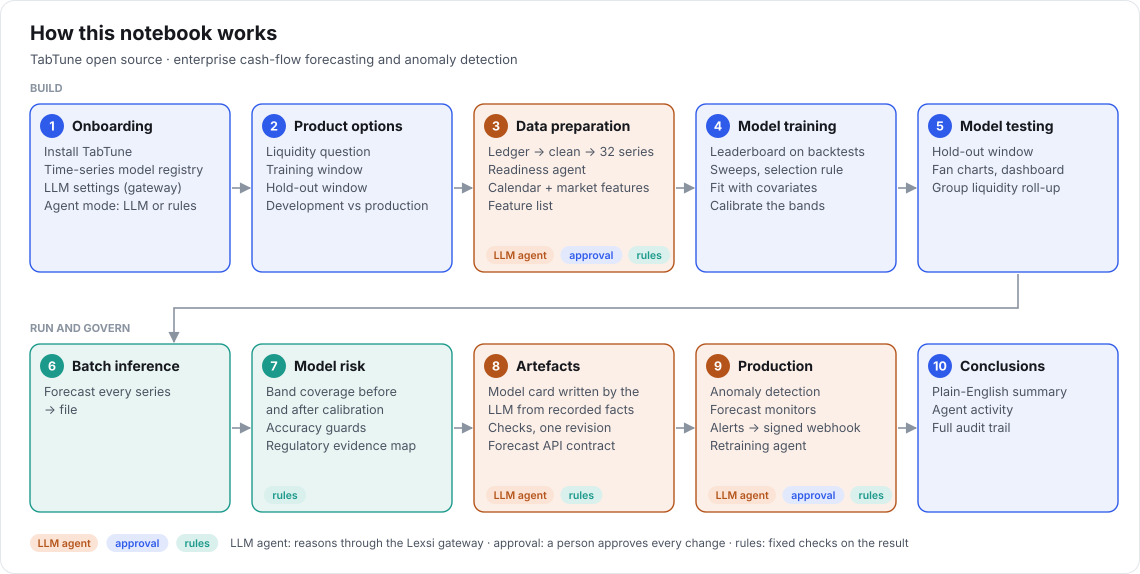

In [ ]:
# @title Diagram: how this notebook works { display-mode: "form" }
from IPython.display import SVG, display
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1140 574" width="1140" height="574" font-family="Inter, \'Helvetica Neue\', Helvetica, Arial, sans-serif" role="img" aria-label="How this notebook works"><defs><marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#8A93A0"/></marker></defs><rect x="0.5" y="0.5" width="1139" height="573" rx="14" fill="#FFFFFF" stroke="#E3E6EB"/><text x="30" y="40" font-size="20" fill="#16181D" font-weight="700" text-anchor="start">How this notebook works</text><text x="30" y="64" font-size="13" fill="#4A5260" font-weight="400" text-anchor="start">TabTune open source · enterprise cash-flow forecasting and anomaly detection</text><text x="30" y="92" font-size="11" fill="#8A93A0" font-weight="700" text-anchor="start">BUILD</text><text x="30" y="332" font-size="11" fill="#8A93A0" font-weight="700" text-anchor="start">RUN AND GOVERN</text><rect x="30" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="52" cy="126" r="12" fill="#2F5BEA"/><text x="52" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">1</text><text x="72" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Onboarding</text><text x="44" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Install TabTune</text><text x="44" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Time-series model registry</text><text x="44" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">LLM settings (gateway)</text><text x="44" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Agent mode: LLM or rules</text><path d="M232,188.0 L250,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="252" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="274" cy="126" r="12" fill="#2F5BEA"/><text x="274" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">2</text><text x="294" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Product options</text><text x="266" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Liquidity question</text><text x="266" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Training window</text><text x="266" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Hold-out window</text><text x="266" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Development vs production</text><path d="M454,188.0 L472,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="474" y="104" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="496" cy="126" r="12" fill="#B4541A"/><text x="496" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">3</text><text x="516" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Data preparation</text><text x="488" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Ledger → clean → 32 series</text><text x="488" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Readiness agent</text><text x="488" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Calendar + market features</text><text x="488" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Feature list</text><rect x="486" y="246" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="520.2" y="259" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="560.4" y="246" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="591.3" y="259" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><rect x="628.1999999999999" y="246" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="649.1999999999999" y="259" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M676,188.0 L694,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="696" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="718" cy="126" r="12" fill="#2F5BEA"/><text x="718" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">4</text><text x="738" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Model training</text><text x="710" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Leaderboard on backtests</text><text x="710" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Sweeps, selection rule</text><text x="710" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Fit with covariates</text><text x="710" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Calibrate the bands</text><path d="M898,188.0 L916,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="918" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="940" cy="126" r="12" fill="#2F5BEA"/><text x="940" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">5</text><text x="960" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Model testing</text><text x="932" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Hold-out window</text><text x="932" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Fan charts, dashboard</text><text x="932" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Group liquidity roll-up</text><rect x="30" y="344" width="200" height="168" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><circle cx="52" cy="366" r="12" fill="#1B998B"/><text x="52" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">6</text><text x="72" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Batch inference</text><text x="44" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Forecast every series</text><text x="44" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">→ file</text><path d="M232,428.0 L250,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="252" y="344" width="200" height="168" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><circle cx="274" cy="366" r="12" fill="#1B998B"/><text x="274" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">7</text><text x="294" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Model risk</text><text x="266" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Band coverage before</text><text x="266" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">and after calibration</text><text x="266" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Accuracy guards</text><text x="266" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Regulatory evidence map</text><rect x="264" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="285.0" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M454,428.0 L472,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="474" y="344" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="496" cy="366" r="12" fill="#B4541A"/><text x="496" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">8</text><text x="516" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Artefacts</text><text x="488" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Model card written by the</text><text x="488" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">LLM from recorded facts</text><text x="488" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Checks, one revision</text><text x="488" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Forecast API contract</text><rect x="486" y="486" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="520.2" y="499" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="560.4" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="581.4" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M676,428.0 L694,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="696" y="344" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="718" cy="366" r="12" fill="#B4541A"/><text x="718" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">9</text><text x="738" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Production</text><text x="710" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Anomaly detection</text><text x="710" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Forecast monitors</text><text x="710" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Alerts → signed webhook</text><text x="710" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Retraining agent</text><rect x="708" y="486" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="742.2" y="499" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="782.4" y="486" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="813.3" y="499" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><rect x="850.1999999999999" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="871.1999999999999" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M898,428.0 L916,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="918" y="344" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="940" cy="366" r="12" fill="#2F5BEA"/><text x="940" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">10</text><text x="960" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Conclusions</text><text x="932" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Plain-English summary</text><text x="932" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Agent activity</text><text x="932" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Full audit trail</text><path d="M1018.0,274 L1018.0,308 L174.0,308 L174.0,342" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="30" y="534" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="64.2" y="547" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="106.4" y="534" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="137.3" y="547" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><rect x="176.2" y="534" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="197.2" y="547" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><text x="230.2" y="547" font-size="11.5" fill="#4A5260" font-weight="400" text-anchor="start">LLM agent: reasons through the Lexsi gateway · approval: a person approves every change · rules: fixed checks on the result</text></svg>'))

# 1 · Onboarding

In [ ]:
# @title Install TabTune and dependencies { display-mode: "form" }
# ⚙️ Install TabTune (open source) — about 3 minutes on Colab
import os, sys, subprocess
from importlib.metadata import version, PackageNotFoundError

def _v(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None

def pip_install(*packages):
    # pip install that prints pip's own error message instead of a bare CalledProcessError
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], capture_output=True, text=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-4000:])
        raise RuntimeError("pip install failed; pip's message is printed above")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    WATCH = {"numpy": "numpy", "pandas": "pandas", "scikit-learn": "sklearn", "transformers": "transformers", "huggingface-hub": "huggingface_hub"}
    before = {p: _v(p) for p in WATCH}
    # One pip call, so pip resolves everything together:
    #  * no [colab] extra: it pins pandas==2.2.2, which has no wheel for Python 3.13
    #  * TabTune needs transformers 4.x, and transformers 4.x needs huggingface-hub < 1.0 (Colab ships 2.x)
    pip_install("tabtune @ git+https://github.com/Lexsi-Labs/TabTune.git", "huggingface_hub>=0.34,<1.0",
                "plotly", "ipywidgets", "accelerate", "kernels>=0.9,<0.11", "httpx[http2]")
    # Changing a package that this Python session has already imported needs a restart
    stale = [p for p, mod in WATCH.items() if before[p] != _v(p) and mod in sys.modules]
    if stale:
        raise SystemExit(f"⚠️ {', '.join(stale)} changed after being imported. Runtime → Restart session, then Run all (the reinstall is instant).")
    # Check the stack imports cleanly in a fresh process before going on
    chk = subprocess.run([sys.executable, "-c", "from tabtune import TabularPipeline; import transformers, huggingface_hub; "
                          "print(transformers.__version__, huggingface_hub.__version__)"], capture_output=True, text=True)
    if chk.returncode != 0:
        print(chk.stderr[-3000:])
        raise RuntimeError("TabTune does not import cleanly; the error is printed above")

print(f"python       {sys.version.split()[0]}")
for pkg in ("tabtune", "torch", "transformers", "huggingface-hub", "numpy", "pandas", "kernels", "httpx", "h2"):
    print(f"{pkg:12} {_v(pkg) or 'MISSING'}")

In [ ]:
# @title Imports, models, theme, fact sheet, audit trail and approval gates { display-mode: "form" }
# 🔧 Imports, theme and the run-wide fact sheet
import json, logging, re, time, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML
import ipywidgets as W

warnings.filterwarnings("ignore")
from tabtune.logger import setup_logger
setup_logger(level=logging.WARNING)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 60)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    GPU = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"
except ImportError:
    DEVICE, GPU = "cpu", "none"

FAST = os.environ.get("TABTUNE_DEMO_FAST") == "1"      # tiny settings for a smoke test without a GPU
AUTO_APPROVE = True                                    # False = the agents stop and ask you to type yes / no
BLUE, ORANGE, TEAL, GREY, DARK, RED, GOLD = "#2F5BEA", "#B4541A", "#1B998B", "#9AA0A8", "#16181D", "#D7263D", "#E8C547"
PALETTE = [BLUE, ORANGE, TEAL, RED, GOLD, GREY, DARK, "#7A5CFA"]
FACTS = {}                                             # every number that reaches the model card is recorded here
AUDIT = []                                             # every agent step and human decision


def record(section, **values):
    """Store results for the model card and the conclusions."""
    FACTS.setdefault(section, {}).update({k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) and not isinstance(v, bool) else v)
                                          for k, v in values.items()})


def audit(actor, step, finding, decision=""):
    AUDIT.append({"at": pd.Timestamp.now().strftime("%H:%M:%S"), "actor": actor, "step": step, "finding": finding, "decision": decision})
    print(f"[{actor} · {step}] {finding}" + (f"  →  {decision}" if decision else ""))


def human_gate(question, recommended=True):
    """Human-in-the-loop checkpoint. With AUTO_APPROVE the recommendation is taken and logged; otherwise you are asked."""
    if AUTO_APPROVE:
        answer = recommended
        who = "auto-approved (AUTO_APPROVE=True)"
    else:
        reply = input(f"🧑 {question}  [recommended: {'yes' if recommended else 'no'}]  yes/no: ").strip().lower()
        answer = reply.startswith("y") if reply else recommended
        who = "human reviewer"
    audit("human", "approval gate", question, f"{'APPROVED' if answer else 'REJECTED'} · {who}")
    return answer


from tabtune.TimeSeries import (TimeSeriesPipeline, TimeSeriesSchema, TimeSeriesLeaderboard,
                                TimeSeriesEnsemble, split_horizon)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# FAST=1 swaps foundation models for weight-free models (smoke test without GPU or downloads)
QUANTILES = [0.05, 0.1, 0.5, 0.9, 0.95]
FOUNDATION_MODELS = [] if FAST else ["ChronosBolt", "Chronos2"]     # Apache-2.0 weights: commercial-safe
BASELINES = ["SeasonalNaive", "WindowAverage", "TabularTS-GBM"]
PRIMARY = "TabularTS-GBM" if FAST else "Chronos2"                   # reads covariates
DETECTOR = "SeasonalNaive" if FAST else "ChronosBolt"
EMBEDDER = None if FAST else "ChronosBolt"
RUN_FINETUNE = False                                                # True adds a LoRA fine-tuned challenger (GPU, a few minutes)
GBM_PARAMS = {"max_iter": 60}                                       # keeps the tree baseline quick
PRIMARY_PARAMS = GBM_PARAMS if PRIMARY == "TabularTS-GBM" else {}
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MON = ["", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(f"device: {DEVICE} ({GPU}) · primary model: {PRIMARY} · detector: {DETECTOR} · fast mode: {FAST} · auto-approve: {AUTO_APPROVE}")

### Model support in TabTune time series

The dictionary below is built from the library's own registry, so it always matches the installed version.

In [ ]:
# @title Time-series models available in TabTune (read live from the registry) { display-mode: "form" }
# 📚 Time-series models available in TabTune today (read live from the library's registry)
from tabtune.registry import list_time_series_models

def model_kind(spec):
    if spec.name.startswith("TabularTS") or spec.name == "TabPFN-TS":
        return "Tabular model as forecaster"
    return "Foundation model" if spec.default_checkpoint else "Statistical baseline"

TS_MODELS = {
    spec.name: {
        "kind": model_kind(spec),
        "family": spec.family,
        "tasks": sorted(spec.tasks),
        "strategies": sorted(spec.strategies),          # inference = zero-shot, finetune, peft = LoRA
        "default_checkpoint": spec.default_checkpoint or "none (no weights)",
        "max_context": spec.max_context,
        "multivariate": spec.supports_multivariate,
        "covariates": spec.supports_covariates,
        "licence": spec.license.name,
        "commercial_use": {True: "yes", False: "no", None: "unverified"}[spec.license.commercial_use_ok],
    }
    for spec in list_time_series_models()
}

catalogue_ts = pd.DataFrame(TS_MODELS).T.rename_axis("model")
print(f"{len(TS_MODELS)} models registered:", catalogue_ts["kind"].value_counts().to_dict())
for kind in ("Foundation model", "Tabular model as forecaster", "Statistical baseline"):
    part = catalogue_ts[catalogue_ts.kind == kind].drop(columns="kind")
    part = part.assign(tasks=part.tasks.map(", ".join), strategies=part.strategies.map(", ".join))
    display(part.style.set_caption(f"{kind} · {len(part)} models"))
TS_MODELS["Chronos2"]          # one entry of the dictionary

### LLM for the agents and the model card
The agents in this notebook are **LLM agents**. Each one gets a goal, a set of **tools** (Python functions that inspect the data or act on it), and the evidence those tools return. The LLM decides which tool to call next and why; the tool runs; the result goes back to the LLM; and so on until it calls `finish`.

- **The LLM** is the model set below (`LEXSI_PROVIDER`, `LEXSI_MODEL`), called through the **Lexsi LLM gateway** (`/gateway/v1/chat/completions`), so every call is traced in the Lexsi project. The same model writes the model card in section 8.
- **A human approves** every action that changes data or models. The approval prompt shows the agent's own reasoning.
- **Rules guard the result.** After an agent finishes, hard rules check what must hold (for example: known leaks removed, no series too short to model). If the agent left something undone, the rule applies it and says so.
- **Without the gateway** (no `LEXSI_API_TOKEN` secret), or with `AGENT_MODE = "rules"`, the original rule-based agents run instead.

Only aggregate evidence reaches the LLM: feature names, counts, scores. No customer rows are sent.

In [ ]:
# @title LLM connection (Lexsi gateway) and writer options { display-mode: "form" }
import html as _html, textwrap

GATEWAY_PROVIDERS = ["OpenAI", "Anthropic", "Gemini", "Groq", "Grok", "Mistral", "Hugging Face", "AWS Bedrock", "Replicate",
                     "Open Router", "Together", "Lexsi", "Self Hosted"]          # spelled exactly as the gateway expects
LOCAL_WRITERS = ["openai/gpt-oss-120b", "Qwen/Qwen2.5-32B-Instruct", "Qwen/Qwen2.5-7B-Instruct"]   # fallback: open weights on this GPU
REVISION_PASS = True            # if the automatic checks find problems, send them back to the writer once
try:
    import h2                   # HTTP/2 support for httpx
    HTTP2 = True
except ImportError:
    HTTP2 = False


def _secret(name):
    # Colab secret (key icon in the left bar) or environment variable
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)


def resolve_writer(choice):
    token = _secret("LEXSI_API_TOKEN")
    if choice == "template":
        return "template"
    if choice in ("auto", "lexsi"):
        missing = [n for n, v in (("LEXSI_API_TOKEN secret", token), ("LEXSI_PROVIDER", LEXSI_PROVIDER), ("LEXSI_MODEL", LEXSI_MODEL)) if not v]
        if not missing and LEXSI_PROVIDER not in GATEWAY_PROVIDERS:
            missing = [f"a valid LEXSI_PROVIDER (got '{LEXSI_PROVIDER}'; use one of: {', '.join(GATEWAY_PROVIDERS)})"]
        if not missing:
            return "lexsi"
        if choice == "lexsi" or token:
            print("Lexsi gateway not used; still needed:", "; ".join(missing))
    if choice in ("auto", "lexsi", "local"):
        return "local" if (DEVICE == "cuda" and not FAST) else "template"
    return choice                                   # an explicit local model name


def writer_options(selected):
    tab = pd.DataFrame([
        ("lexsi", "Lexsi LLM gateway", f"{LEXSI_PROVIDER or '<provider>'} · {LEXSI_MODEL or '<model>'} · project {LEXSI_PROJECT}; every call is traced in the project; "
                  "only the aggregate fact sheet is sent, never customer rows"),
        ("local", "Open weights on this GPU", "gpt-oss-120b (about 63 GB, needs an 80 GB GPU), then Qwen2.5-32B, then Qwen2.5-7B"),
        ("template", "Deterministic", "no LLM; fills the same template from the facts"),
    ], columns=["writer", "kind", "notes"])
    row = selected if selected in ("lexsi", "template") else "local"
    tab[""] = np.where(tab.writer.eq(row), "◀ this run", "")
    return tab.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

In [ ]:
CARD_WRITER = "auto"                           # "auto" = Lexsi gateway if the token secret is set, else local GPU, else template
LEXSI_PROVIDER = "Open Router"                 # exactly as registered in the Lexsi project
LEXSI_MODEL = "anthropic-claude-sonnet-5.5_v1"
LEXSI_PROJECT = "demo_Z1P8OHR7RU"
LEXSI_CLIENT_ID = "adityatanna"
LEXSI_ENDPOINT = "chat"                        # "chat" = /gateway/v1/chat/completions · "text" = /gateway/v1/text/generation (Lexsi-hosted models only)
LEXSI_MAX_TOKENS = 32000                       # thinking tokens count against this limit
LEXSI_REASONING = {"effort": "low"}            # forwarded to OpenRouter: short thinking, so the budget goes to the card · None = model default
LEXSI_TEMPERATURE, LEXSI_TOP_P, LEXSI_TOP_K = 0.2, 0.9, 50     # used by the text endpoint only
LEXSI_MIN_TOKENS, LEXSI_EXPLAIN_TOKENS = None, 1               # used by the text endpoint only
# The API token is read from the Colab secret LEXSI_API_TOKEN (key icon in the left bar); never paste it here.

WRITER = resolve_writer(CARD_WRITER)
writer_options(WRITER)

In [ ]:
import httpx

LEXSI_BASE = os.environ.get("LEXSI_GATEWAY_BASE", "https://api.lexsi.ai/gateway/v1")


def _lexsi_post(path, payload):
    headers = {"x-api-token": _secret("LEXSI_API_TOKEN"), "Content-Type": "application/json"}
    with httpx.Client(http2=HTTP2, timeout=httpx.Timeout(900, connect=30)) as client:
        return client.post(f"{LEXSI_BASE}/{path}", headers=headers, json=payload)


def lexsi_chat(messages, max_tokens, reasoning=None):              # POST /gateway/v1/chat/completions
    payload = {"provider": LEXSI_PROVIDER, "client_id": LEXSI_CLIENT_ID, "project_name": LEXSI_PROJECT, "model": LEXSI_MODEL,
               "max_tokens": max_tokens, "messages": messages, "stream": False}
    if reasoning:
        payload["reasoning"] = reasoning
    return _lexsi_post("chat/completions", payload)


def lexsi_generate(prompt, max_tokens):                            # POST /gateway/v1/text/generation
    payload = {"provider": LEXSI_PROVIDER, "client_id": LEXSI_CLIENT_ID, "project_name": LEXSI_PROJECT, "model": LEXSI_MODEL,
               "prompt": prompt, "explain_tokens": LEXSI_EXPLAIN_TOKENS, "temperature": LEXSI_TEMPERATURE,
               "top_p": LEXSI_TOP_P, "top_k": LEXSI_TOP_K, "max_tokens": max_tokens}
    if LEXSI_MIN_TOKENS:
        payload["min_tokens"] = LEXSI_MIN_TOKENS
    return _lexsi_post("text/generation", payload)

In [ ]:
# @title Agent framework: the LLM decides, tools act, rules guard, a human approves { display-mode: "form" }
AGENT_STEPS, AGENT_CALLS = [], []          # every step every agent took · every LLM call
AGENT_REASONING = {"effort": "low"}        # short thinking per step; set None for the model's default


class Tool:
    def __init__(self, name, fn, description, args=None, approval=False):
        self.name, self.fn, self.description, self.args, self.approval = name, fn, description, args or {}, approval

    def signature(self):
        a = ", ".join(f"{k}: {v}" for k, v in self.args.items())
        return f"- {self.name}({a}) — {self.description}" + (" [needs human approval]" if self.approval else "")


PROTOCOL = """AGENT PROTOCOL
Reply with ONE JSON object and nothing else:
{"thought": "<one or two sentences for a human reviewer: what the evidence shows and why this is the next action>", "tool": "<tool name>", "args": {<arguments>}}
After each action you receive an OBSERVATION with the tool's result. Call the tool "finish" with {"summary": "..."} when the goal is met."""


def _compact(obj, limit=3500):
    """JSON for an observation, shortened by trimming long lists rather than cutting the text."""
    text = json.dumps(obj, default=str)
    keep = 25
    while len(text) > limit and keep >= 3:
        def trim(o):
            if isinstance(o, list) and len(o) > keep:
                return [trim(x) for x in o[:keep]] + [f"... {len(o) - keep} more"]
            if isinstance(o, list):
                return [trim(x) for x in o]
            if isinstance(o, dict):
                return {k: trim(v) for k, v in o.items()}
            return o
        text = json.dumps(trim(obj), default=str)
        keep //= 2
    return text[:limit]


def parse_action(text):
    """First JSON object in the reply that names a tool (tolerates code fences and surrounding prose)."""
    dec = json.JSONDecoder()
    for i, ch in enumerate(text or ""):
        if ch == "{":
            try:
                obj, _ = dec.raw_decode(text[i:])
            except ValueError:
                continue
            if isinstance(obj, dict) and ("tool" in obj or "action" in obj):
                obj.setdefault("tool", obj.pop("action", None))
                obj.setdefault("args", {})
                obj.setdefault("thought", "")
                return obj
    return None


class LLMAgent:
    def __init__(self, name, role, goal, rules, tools, max_steps=16):
        self.name, self.role, self.goal, self.rules, self.max_steps = name, role, goal, rules, max_steps
        self.tools = {t.name: t for t in tools}
        self.summary = None

    def system_prompt(self):
        tools = "\n".join(t.signature() for t in self.tools.values()) + "\n- finish(summary: what you did and why, in plain English) — end the task"
        rules = "\n".join(f"- {r}" for r in ["Decide only from evidence returned by the tools. Never invent numbers, features or series names.",
                                              "Actions marked [needs human approval] are shown to a reviewer together with your thought.",
                                              *self.rules, f"You have at most {self.max_steps} replies."])
        return f"You are the {self.name}. {self.role}\n\nGOAL\n{self.goal}\n\nTOOLS (call exactly one per reply)\n{tools}\n\nRULES\n{rules}\n\n{PROTOCOL}"

    def _llm(self, messages):
        global AGENT_REASONING
        t0 = time.time()
        r = lexsi_chat(messages, AGENT_MAX_TOKENS, AGENT_REASONING)
        if r.status_code in (400, 422) and AGENT_REASONING:
            AGENT_REASONING = None
            r = lexsi_chat(messages, AGENT_MAX_TOKENS)
        if r.status_code != 200:
            raise RuntimeError(f"gateway returned {r.status_code}: {r.text[:200]}")
        body = r.json()
        if not body.get("choices"):
            raise RuntimeError(f"no answer from the gateway: {str(body)[:200]}")          # e.g. blocked by a guardrail
        msg = body["choices"][0].get("message") or {}
        text = msg.get("content") or ""
        if isinstance(text, list):
            text = "".join(b.get("text", "") for b in text if isinstance(b, dict))
        u = body.get("usage") or {}
        AGENT_CALLS.append({"agent": self.name, "seconds": round(time.time() - t0, 1), "input_tokens": u.get("prompt_tokens") or 0,
                            "output_tokens": u.get("completion_tokens") or 0, "model": f"{LEXSI_PROVIDER} · {LEXSI_MODEL}"})
        return text

    def _log(self, step, thought, tool, args, outcome, approved=None):
        AGENT_STEPS.append({"agent": self.name, "step": step, "thought": thought, "tool": tool,
                            "args": _compact(args, 300), "outcome": outcome[:300], "approved": approved})
        print(f"[{self.name} · {step}] {thought[:220]}\n      → {tool}({_compact(args, 160)}) → {outcome[:200]}")

    def run(self, task):
        messages = [{"role": "system", "content": self.system_prompt()}, {"role": "user", "content": task}]
        for step in range(1, self.max_steps + 1):
            text = self._llm(messages)
            act = parse_action(text)
            if act is None or (act["tool"] != "finish" and act["tool"] not in self.tools):
                why = "not a JSON action" if act is None else f"unknown tool '{act['tool']}'"
                self._log(step, (text or "")[:200], "—", {}, f"invalid reply ({why}); asked again")
                messages += [{"role": "assistant", "content": text or ""},
                             {"role": "user", "content": f"Invalid reply ({why}). Reply with exactly one JSON object as described in the AGENT PROTOCOL."}]
                continue
            thought, name, args = str(act["thought"]), act["tool"], act["args"] if isinstance(act["args"], dict) else {}
            if name == "finish":
                self.summary = str(args.get("summary", thought))
                self._log(step, thought, "finish", {}, self.summary)
                audit(self.name, "finish", self.summary[:300], "DONE")
                return self.summary
            tool = self.tools[name]
            approved = None
            if tool.approval:
                approved = human_gate(f"{self.name} wants {name}({_compact(args, 200)}). Its reasoning: {thought}", True)
            if approved is False:
                obs = {"rejected": True, "message": "The human reviewer rejected this action. Do not repeat it; choose another action or finish."}
            else:
                try:
                    obs = tool.fn(**args)
                except Exception as exc:
                    obs = {"error": f"{type(exc).__name__}: {str(exc)[:300]}"}
            out = _compact(obs)
            self._log(step, thought, name, args, out, approved)
            if tool.approval or name.startswith(("remove", "exclude", "promote")):
                audit(self.name, name, thought[:300], ("APPLIED" if approved else "REJECTED by reviewer") if approved is not None else "")
            messages += [{"role": "assistant", "content": json.dumps(act)}, {"role": "user", "content": "OBSERVATION\n" + out}]
        self.summary = f"stopped after {self.max_steps} steps"
        audit(self.name, "step limit", self.summary, "STOPPED")
        return self.summary


def run_llm_agent(agent, task, fallback):
    """Run an LLM agent; if the gateway fails, the rule-based version finishes the job and says so."""
    try:
        return agent.run(task)
    except Exception as exc:
        print(f"⚠️ {agent.name}: the LLM call failed ({str(exc)[:200]}) → the rule-based version takes over from here")
        audit(agent.name, "fallback", str(exc)[:200], "RULES")
        fallback()
        return "rule-based fallback"


def show_agent_trace(name):
    S = pd.DataFrame([s for s in AGENT_STEPS if s["agent"] == name])
    if not len(S):
        print(f"{name}: no LLM steps (AGENT_MODE = '{AGENT_MODE}')")
        return
    C_ = pd.DataFrame([c for c in AGENT_CALLS if c["agent"] == name])
    print(f"{name}: {len(S)} steps · {len(C_)} LLM calls · {C_.seconds.sum():.0f}s · {int(C_.input_tokens.sum()):,} input / "
          f"{int(C_.output_tokens.sum()):,} output tokens · {C_.model.iloc[0] if len(C_) else ''}")
    display(S[["step", "thought", "tool", "args", "outcome", "approved"]].style.hide(axis="index")
            .set_properties(**{"text-align": "left", "white-space": "pre-wrap", "font-size": "12px"}).set_caption(f"{name}: every step, in order"))



def agent_overview():
    tab = pd.DataFrame([
        ("Data readiness agent", "3.3", "which series to exclude, what to fill, what to flag, what to do with extreme days",
         "readiness_overview, series_detail, exclude_series, interpolate_missing, forward_fill_covariates, flag_for_data_owner, decide_extreme_days",
         "no series shorter than the minimum history; no missing target or covariate values go to the models"),
        ("Retraining agent", "9.3", "whether to run a champion-challenger review, which challengers to build, whether to promote",
         "read_job, run_challengers, promote",
         "promotion only if WQL improves by the margin and MASE is no worse than the tolerance, on the next unseen window"),
        ("Model-card writer", "8.1", "the model card, from the recorded facts", "fact sheet → card → automatic checks → one revision",
         "every number must match a recorded fact"),
    ], columns=["agent", "section", "decides", "tools", "rules that always hold"])
    tab["runs as"] = ["LLM" if AGENT_MODE == "llm" else "rules", "LLM" if AGENT_MODE == "llm" else "rules", WRITER]
    who = f"{LEXSI_PROVIDER} · {LEXSI_MODEL} through the Lexsi gateway" if AGENT_MODE == "llm" else "rule-based (no gateway)"
    display(tab.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).set_caption(f"Agents in this notebook · LLM: {who}"))

In [ ]:
AGENT_MODE = "llm" if WRITER == "lexsi" else "rules"   # "llm" = the agents reason with the LLM above · "rules" = the rule-based agents
AGENT_MAX_TOKENS = 3000                                 # per agent step (thinking tokens count against it)
agent_overview()

# 2 · Product options

## Problem statement
**How much cash will each entity and business line need over the next four weeks, and is today's activity normal?** A banking group's treasury forecasts daily flows for 32 entity-product series to size liquidity buffers, and monitors the same feed for incidents (fraud spikes, outages, reporting breaks).

## Training and test data

| Set | What it is | Used for |
|---|---|---|
| History (training / context) | all days before the final 28 | context for foundation models; training data for the tree forecaster |
| Rolling backtests | the last three 28-day windows inside the history | model race and selection |
| Inner window | one 28-day window inside the history | hyperparameter sweeps and covariate explainability |
| Hold-out (test) | the final 28 days | untouched final report |
| Live feed | last 480 days with labelled incidents injected | anomaly detection |

## Development vs production

| Choice | In development (this notebook) | In production |
|---|---|---|
| Engine | TabTune open source (`tabtune.TimeSeries`) on the notebook GPU | the same library as a scheduled job on the bank's GPU compute |
| Models | 33 registered forecasters: 9 foundation models, 19 tabular-as-forecaster, 5 baselines | the commercially licensed subset, fixed per use case |
| Adaptation | zero-shot, optional LoRA fine-tuning | zero-shot by default; fine-tuning as a managed job |
| Scoring | batch forecast in the notebook | scheduled batch, plus the forecast API in section 8 |
| Governance | audit list and model card in this notebook | model registry, approvals and audit trail in the bank's MLOps stack |

In [ ]:
# @title Use-case settings { display-mode: "form" }
USE_CASE_NAME, DECISION_SUPPORTED = 'Enterprise liquidity forecasting and anomaly monitoring', 'four-week liquidity buffers by entity and business line; incident alerts'
CLOSING_LINE = "**Next step:** replace section 3.1 with the bank's own ledger extract in the same ten-column layout; every later cell runs unchanged."
HORIZON, SEASON, MONTH_LAG, SCALE_WINDOW = 28, 7, 28, 365     # daily data: 4-week horizon, weekly cycle
UNIT = "USD mn"
GROUP_COLORS = {"Retail": BLUE, "Corporate": ORANGE, "Treasury": TEAL}
ENTITY_COLORS = {"KSA": BLUE, "BHR": ORANGE, "UAE": TEAL, "UK": GREY}

# 3 · Data preparation

## 3.1 The enterprise ledger

**Structure** — every row is one account's posting for one day:

`txn_id · value_date · posting_date · entity · business_line · product · account_id · currency · amount_lcy_mn · source_system`

| Entity | Currency | Weekend | Calendar |
|---|---|---|---|
| KSA | SAR (pegged 3.75) | Fri–Sat | Ramadan, Eid, 27th payroll, National Day |
| BHR | BHD (pegged 0.376) | Fri–Sat | Ramadan, Eid, 27th payroll, National Day |
| UAE | AED (pegged 3.6725) | Sat–Sun | Ramadan, Eid, 27th payroll, National Day |
| UK | GBP (floating) | Sat–Sun | Christmas, bank holidays, month-end payroll |

**Market drivers:** Brent crude (drives GCC supplier and trade-finance flows with a lag), policy rate (drives interbank funding) and GBP/USD.

In [ ]:
# @title Generate market drivers, entity calendars and series-level flows { display-mode: "form" }
DATES = pd.date_range("2022-01-01", "2026-10-31", freq="D")
NT = len(DATES)
rng = np.random.default_rng(7)

RAMADAN = [("2022-04-02", "2022-05-01"), ("2023-03-23", "2023-04-20"), ("2024-03-11", "2024-04-09"),
           ("2025-03-01", "2025-03-29"), ("2026-02-18", "2026-03-19")]      # approximate (moon sighting)
EID_FITR = ["2022-05-02", "2023-04-21", "2024-04-10", "2025-03-30", "2026-03-20"]
EID_ADHA = ["2022-07-09", "2023-06-28", "2024-06-16", "2025-06-06", "2026-05-27"]
ENTITIES = {"KSA": dict(ccy="SAR", weekend=(4, 5), gcc=True,  size=1.00, national=(9, 23)),
            "BHR": dict(ccy="BHD", weekend=(4, 5), gcc=True,  size=0.40, national=(12, 16)),
            "UAE": dict(ccy="AED", weekend=(5, 6), gcc=True,  size=0.60, national=(12, 2)),
            "UK":  dict(ccy="GBP", weekend=(5, 6), gcc=False, size=0.35, national=(12, 25))}
#            line,        product,                      base USD mn, noise, accounts
PRODUCTS = [("Retail",    "Branch cash withdrawals",       6.0, 0.08, 18),
            ("Retail",    "ATM withdrawals",               3.5, 0.07, 18),
            ("Retail",    "Card spend",                   12.0, 0.06, 18),
            ("Corporate", "Payroll disbursements",        40.0, 0.10, 18),
            ("Corporate", "Supplier payments",            90.0, 0.14, 18),
            ("Corporate", "Trade finance settlements",    55.0, 0.30, 18),
            ("Treasury",  "Interbank funding",           160.0, 0.12, 18),
            ("Treasury",  "FX settlements",              110.0, 0.18, 18)]

# --- market drivers -------------------------------------------------------------------------------
brent = np.empty(NT); brent[0] = 82.0
for t in range(1, NT):                                   # mean-reverting with occasional shocks
    brent[t] = brent[t - 1] + 0.01 * (80 - brent[t - 1]) + rng.normal(0, 1.3) + (rng.random() < 0.004) * rng.normal(0, 7)
brent = np.clip(brent, 45, 130)
rate_path = [("2022-01-01", 1.25), ("2022-06-01", 2.75), ("2022-12-01", 5.0), ("2023-07-01", 6.0),
             ("2024-10-01", 5.5), ("2025-03-01", 5.0), ("2025-10-01", 4.5)]
policy_rate = pd.Series(np.nan, index=DATES)
for d0, r in rate_path:
    policy_rate[pd.Timestamp(d0):] = r
gbpusd = 1.27 * np.exp(np.cumsum(rng.normal(0, 0.004, NT)) - np.linspace(0, 0.02, NT))
oil_5d_move = np.abs(pd.Series(brent).pct_change(5).fillna(0).to_numpy())
brent_lag30 = pd.Series(brent).shift(30).bfill().to_numpy()
market = pd.DataFrame({"timestamp": DATES, "brent_usd": brent, "policy_rate": policy_rate.to_numpy(), "gbpusd": gbpusd})
LCY_PER_USD = {"SAR": np.full(NT, 3.75), "BHD": np.full(NT, 0.376), "AED": np.full(NT, 3.6725), "GBP": 1 / gbpusd}


# --- entity calendars -----------------------------------------------------------------------------
def entity_calendar(entity):
    e = ENTITIES[entity]
    cal = pd.DataFrame({"timestamp": DATES})
    dow, day, month = DATES.dayofweek, DATES.day, DATES.month
    cal["is_weekend"] = np.isin(dow, e["weekend"]).astype(int)
    ram, pre, eid = (np.zeros(NT, bool) for _ in range(3))
    if e["gcc"]:
        for s, x in RAMADAN:
            s, x = pd.Timestamp(s), pd.Timestamp(x)
            ram |= (DATES >= s) & (DATES <= x); pre |= (DATES > x - pd.Timedelta(days=7)) & (DATES <= x)
        for d0 in EID_FITR:
            d0 = pd.Timestamp(d0); eid |= (DATES >= d0) & (DATES < d0 + pd.Timedelta(days=4))
        for d0 in EID_ADHA:
            d0 = pd.Timestamp(d0); eid |= (DATES >= d0 - pd.Timedelta(days=1)) & (DATES < d0 + pd.Timedelta(days=4))
        payday = (day >= 25) & (day <= 27)
        holiday = eid | ((month == e["national"][0]) & (day == e["national"][1]))
    else:
        pre = (month == 12) & (day >= 15) & (day <= 24)                      # pre-Christmas peak
        eid = ((month == 12) & (day >= 25) & (day <= 26)) | ((month == 1) & (day == 1))
        payday = day >= (DATES.days_in_month - 2)
        holiday = eid
    cal["is_payday"] = np.asarray(payday).astype(int)
    cal["is_month_end"] = np.asarray(day >= DATES.days_in_month - 1).astype(int)
    cal["is_quarter_end"] = np.asarray(np.isin(month, [3, 6, 9, 12]) & (day >= DATES.days_in_month - 2)).astype(int)
    cal["is_ramadan"], cal["is_pre_festival"], cal["is_festival"] = ram.astype(int), np.asarray(pre).astype(int), np.asarray(eid).astype(int)
    cal["is_holiday"] = np.asarray(holiday).astype(int)
    return cal


CALENDARS = {e: entity_calendar(e) for e in ENTITIES}
t_years = np.arange(NT) / 365.25


def series_level(entity, product, base):
    """Expected daily flow (USD mn) for one entity × product, before noise."""
    c, e = CALENDARS[entity], ENTITIES[entity]
    wk, pay, me, qe = c.is_weekend.to_numpy(), c.is_payday.to_numpy(), c.is_month_end.to_numpy(), c.is_quarter_end.to_numpy()
    ram, pre, fest = c.is_ramadan.to_numpy(), c.is_pre_festival.to_numpy(), c.is_festival.to_numpy()
    pre_weekend = np.roll(wk, -1) * (1 - wk)                              # the day before the weekend
    oil = (brent_lag30 / 80) if e["gcc"] else np.ones(NT)
    b = base * e["size"]
    if product == "Branch cash withdrawals":
        return b * 1.04 ** t_years * (1 - 0.35 * wk) * (1 + 0.18 * pre_weekend) * (1 + 0.45 * pay) * (1 + 0.2 * ram) * (1 + 0.55 * pre) * (1 - 0.55 * fest)
    if product == "ATM withdrawals":
        return b * 1.05 ** t_years * (1 - 0.10 * wk) * (1 + 0.12 * pre_weekend) * (1 + 0.35 * pay) * (1 + 0.15 * ram) * (1 + 0.45 * pre) * (1 - 0.25 * fest)
    if product == "Card spend":
        return b * 1.15 ** t_years * (1 + 0.14 * wk) * (1 + 0.25 * pay) * (1 + 0.18 * ram) * (1 + 0.6 * pre) * (1 - 0.2 * fest)
    if product == "Payroll disbursements":
        return b * 1.06 ** t_years * (0.06 + 5.5 * pay) * (1 - 0.9 * wk * (1 - pay))
    if product == "Supplier payments":
        return b * 1.07 ** t_years * (1 - 0.93 * wk) * (1 + 0.6 * me) * (1 + 0.35 * qe) * (1 - 0.12 * ram) * (1 - 0.85 * fest) * oil ** 0.5
    if product == "Trade finance settlements":
        return b * 1.05 ** t_years * (1 - 0.95 * wk) * (1 + 0.25 * me) * (1 - 0.15 * ram) * (1 - 0.9 * fest) * oil ** 0.9
    if product == "Interbank funding":
        return b * 1.03 ** t_years * (1 - 0.97 * wk) * (1 + 0.45 * me) * (1 + 0.9 * qe) * (1 + 0.07 * (policy_rate.to_numpy() - 4)) * (1 - 0.8 * fest)
    if product == "FX settlements":
        return b * 1.06 ** t_years * (1 - 0.97 * wk) * (1 + 6.0 * oil_5d_move) * (1 + 0.2 * me) * (1 - 0.85 * fest)
    raise ValueError(product)


SERIES = [(e, line, prod, base, noise, n_acc) for e in ENTITIES for line, prod, base, noise, n_acc in PRODUCTS]
print(f"{len(SERIES)} series = {len(ENTITIES)} entities × {len(PRODUCTS)} products · {NT:,} days")

In [ ]:
# @title Explode the series into an account-level ledger, then inject realistic defects { display-mode: "form" }
A = PRODUCTS[0][4]
blocks, truth_rows = [], []
for s_idx, (entity, line, product, base, noise, n_acc) in enumerate(SERIES):
    level = series_level(entity, product, base) * rng.lognormal(0, noise, NT)
    weights = rng.dirichlet(np.full(n_acc, 0.7))
    acct = level[None, :] * weights[:, None] * rng.lognormal(0, 0.25, (n_acc, NT))           # USD mn, account × day
    lcy = acct * LCY_PER_USD[ENTITIES[entity]["ccy"]][None, :]
    blocks.append(pd.DataFrame({
        "value_date": np.tile(DATES.values, n_acc),
        "entity": entity, "business_line": line, "product": product,
        "account_id": np.repeat([f"{entity}-{s_idx % len(PRODUCTS):02d}-{a:03d}" for a in range(n_acc)], NT),
        "currency": ENTITIES[entity]["ccy"], "amount_lcy_mn": lcy.ravel(),
        "source_system": f"{'CORE' if line == 'Retail' else 'GTB' if line == 'Corporate' else 'TRSY'}-{entity}"}))
    truth_rows.append(pd.DataFrame({"item_id": f"{entity} · {product}", "timestamp": DATES, "truth_usd_mn": acct.sum(axis=0)}))
ledger = pd.concat(blocks, ignore_index=True)
truth = pd.concat(truth_rows, ignore_index=True)
ledger.insert(0, "txn_id", np.arange(len(ledger)))
ledger["posting_date"] = ledger["value_date"]

q = np.random.default_rng(99)
n = len(ledger)
# 1 · late postings: booked 1–3 days after the value date
late = q.choice(n, int(n * 0.03), replace=False)
ledger.loc[late, "posting_date"] = ledger.loc[late, "value_date"] + pd.to_timedelta(q.integers(1, 4, len(late)), unit="D")
# 2 · unit errors: amount keyed in thousands instead of millions
unit_err = q.choice(n, 150, replace=False)
ledger.loc[unit_err, "amount_lcy_mn"] *= 1000
# 3 · missing amounts
nulls = q.choice(n, int(n * 0.0015), replace=False)
ledger.loc[nulls, "amount_lcy_mn"] = np.nan
# 4 · label drift: the same product spelled differently by different systems
drift = q.choice(n, int(n * 0.02), replace=False)
variants = [str.upper, lambda s: s.lower().replace(" ", "_"), lambda s: s + " ", lambda s: s.replace("settlements", "sttl")]
ledger["product"] = ledger["product"].astype(object)
ledger.loc[drift, "product"] = [variants[i % 4](p) for i, p in enumerate(ledger.loc[drift, "product"])]
# 5 · source-system outage: CORE-BHR delivered nothing for four days
OUTAGE = pd.date_range("2026-03-08", periods=4)
ledger = ledger[~((ledger.source_system == "CORE-BHR") & ledger.value_date.isin(OUTAGE))]
# 6 · replayed batches: duplicate rows
dups = ledger.sample(int(len(ledger) * 0.004), random_state=3)
ledger = pd.concat([ledger, dups], ignore_index=True).sample(frac=1, random_state=1).reset_index(drop=True)

print(f"raw ledger: {len(ledger):,} rows · {ledger.account_id.nunique()} accounts · "
      f"{ledger.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
display(ledger.head(6))

## 3.2 Cleaning the ledger, visualised

A forecasting model is only as good as the series it is given. Each step below fixes one defect, and each plot shows what the defect looked like and what the fix did.

In [ ]:
# @title Profile of the raw extract { display-mode: "form" }
norm = lambda p: re.sub(r"[^a-z]", "", p.lower()).replace("sttl", "settlements")     # one key per product, however it is spelled
canon = {norm(p): p for _, p, *_ in PRODUCTS}
profile = pd.DataFrame({
    "rows": [len(ledger)], "accounts": [ledger.account_id.nunique()], "source systems": [ledger.source_system.nunique()],
    "distinct product labels": [ledger["product"].nunique()], "null amounts": [int(ledger.amount_lcy_mn.isna().sum())],
    "duplicate txn_id": [int(ledger.txn_id.duplicated().sum())],
    "late postings": [int((ledger.posting_date > ledger.value_date).sum())]}).T.rename(columns={0: "raw extract"})
display(profile.style.format("{:,.0f}"))

daily_rows = ledger.groupby(["value_date", "source_system"]).size().unstack(fill_value=0)
labels = ledger["product"].value_counts()
fig = make_subplots(rows=1, cols=3, column_widths=[0.4, 0.3, 0.3],
                    subplot_titles=("Rows delivered per day by source system (2026)", "Product labels found (log count)",
                                    "Amount distribution by currency (log10)"))
recent = daily_rows[daily_rows.index >= "2026-01-01"]
fig.add_trace(go.Heatmap(z=recent.T.values, x=recent.index, y=recent.columns, colorscale=[[0, RED], [0.01, "#DCE4FB"], [1, BLUE]],
                         showscale=False), 1, 1)
fig.add_trace(go.Bar(y=[repr(l) for l in labels.index[::-1]], x=labels.values[::-1], orientation="h",
                     marker_color=[GREY if l in canon.values() else RED for l in labels.index[::-1]], showlegend=False), 1, 2)
for ccy, g in ledger.sample(60000, random_state=0).groupby("currency"):
    fig.add_trace(go.Histogram(x=np.log10(g.amount_lcy_mn.dropna().clip(lower=1e-6)), name=ccy, opacity=0.6, nbinsx=60), 1, 3)
fig.update_xaxes(type="log", row=1, col=2)
fig.update_layout(template="plotly_white", height=560, barmode="overlay",
                  title="Raw extract · red = outage (left), non-standard labels (middle); the right tail holds unit errors")
fig.show()

In [ ]:
# @title Cleaning pipeline: each step is counted for the waterfall below { display-mode: "form" }
steps = [("raw rows", len(ledger))]
clean = ledger.drop_duplicates("txn_id")
steps.append(("− replayed duplicates", len(clean)))
clean = clean[clean.amount_lcy_mn.notna()]
steps.append(("− null amounts", len(clean)))

# label drift → canonical product names
clean["product"] = clean["product"].map(lambda p: canon[norm(p)])
n_relabelled = int((ledger["product"].map(lambda p: p not in canon.values())).sum())

# unit errors: an amount far above the account's own busiest days is a thousands-for-millions slip
p99 = clean.groupby("account_id")["amount_lcy_mn"].transform(lambda s: s.quantile(0.99))
ratio = clean.amount_lcy_mn / p99.clip(lower=1e-9)
is_unit_error = ratio > 8
before_fix = clean.loc[is_unit_error, ["account_id", "value_date", "amount_lcy_mn"]].assign(ratio=ratio[is_unit_error])
clean.loc[is_unit_error, "amount_lcy_mn"] /= 1000

# FX: convert every posting to USD at the day's rate
fx = pd.DataFrame({"value_date": np.tile(DATES.values, 4), "currency": np.repeat(list(LCY_PER_USD), NT),
                   "lcy_per_usd": np.concatenate(list(LCY_PER_USD.values()))})
clean = clean.merge(fx, on=["value_date", "currency"])
clean["amount_usd_mn"] = clean.amount_lcy_mn / clean.lcy_per_usd
clean["item_id"] = clean.entity + " · " + clean["product"]

fig = make_subplots(rows=1, cols=3, column_widths=[0.34, 0.33, 0.33],
                    subplot_titles=("Rows through the pipeline", "Unit errors: amount ÷ account 99th percentile", "Late postings: days after value date"))
fig.add_trace(go.Waterfall(x=[s for s, _ in steps], measure=["absolute", "relative", "relative"],
                           y=[steps[0][1], steps[1][1] - steps[0][1], steps[2][1] - steps[1][1]],
                           text=[f"{steps[0][1]:,}", f"{steps[1][1] - steps[0][1]:,}", f"{steps[2][1] - steps[1][1]:,}"],
                           decreasing=dict(marker_color=RED), totals=dict(marker_color=BLUE), showlegend=False), 1, 1)
samp = ratio.sample(40000, random_state=0)
fig.add_trace(go.Histogram(x=np.log10(pd.concat([samp, ratio[is_unit_error]]).clip(lower=1e-3)), nbinsx=80, marker_color=GREY, showlegend=False), 1, 2)
fig.add_vline(x=np.log10(8), line_dash="dot", line_color=RED, row=1, col=2)
lag_days = (clean.posting_date - clean.value_date).dt.days
fig.add_trace(go.Bar(x=["on time", "1 day", "2 days", "3 days"], y=[int((lag_days == k).sum()) for k in range(4)],
                     marker_color=[GREY, ORANGE, ORANGE, ORANGE], showlegend=False), 1, 3)
fig.update_yaxes(type="log", row=1, col=2); fig.update_yaxes(type="log", row=1, col=3)
fig.update_yaxes(range=[steps[2][1] * 0.99, steps[0][1] * 1.002], row=1, col=1)
fig.update_xaxes(title_text="log10 ratio (red line = rule)", row=1, col=2)
fig.update_layout(template="plotly_white", height=460, title="Cleaning the ledger")
fig.show()
print(f"relabelled {n_relabelled:,} rows to {clean['product'].nunique()} canonical products · fixed {int(is_unit_error.sum())} unit errors "
      f"· aggregating on value_date keeps {int((lag_days > 0).sum()):,} late postings on the right day")

In [ ]:
# @title Aggregate to one series per entity × product, find gaps, impute the outage { display-mode: "form" }
agg = clean.groupby(["item_id", "value_date"], observed=True)["amount_usd_mn"].sum().rename("value").reset_index()
grid = pd.MultiIndex.from_product([sorted(agg.item_id.unique()), DATES], names=["item_id", "timestamp"])
panel = agg.rename(columns={"value_date": "timestamp"}).set_index(["item_id", "timestamp"]).reindex(grid).reset_index()
gaps = panel[panel.value.isna()]
print(f"{panel.item_id.nunique()} series × {NT:,} days · missing series-days after aggregation: {len(gaps)}")
display(gaps.groupby("item_id").timestamp.agg(["min", "max", "count"]))

# impute a gap with the same weekday's median over the previous four weeks, scaled by the latest week's level
def impute(g):
    v = g["value"].copy()
    for i in np.flatnonzero(v.isna().to_numpy()):
        prior = [v.iloc[i - 7 * k] for k in range(1, 5) if i - 7 * k >= 0 and pd.notna(v.iloc[i - 7 * k])]
        v.iloc[i] = float(np.median(prior)) if prior else float(v.dropna().median())
    return v
panel["was_imputed"] = panel.value.isna()
panel["value"] = panel.groupby("item_id", group_keys=False).apply(impute)

# what a naive pipeline would have produced, for comparison with the truth
naive = (ledger.assign(item_id=ledger.entity + " · " + ledger["product"].astype(str))
         .merge(fx, on=["value_date", "currency"])
         .assign(usd=lambda d: d.amount_lcy_mn / d.lcy_per_usd)
         .groupby(["item_id", "posting_date"])["usd"].sum().rename("naive").reset_index().rename(columns={"posting_date": "timestamp"}))
check = panel.merge(truth, on=["item_id", "timestamp"]).merge(naive, on=["item_id", "timestamp"], how="left").fillna({"naive": 0})
err = lambda col: (check[col] - check.truth_usd_mn).abs().sum() / check.truth_usd_mn.sum() * 100

show = "BHR · Branch cash withdrawals"
w = check[(check.item_id == show) & (check.timestamp >= "2026-02-15") & (check.timestamp <= "2026-03-31")]
fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38],
                    subplot_titles=(f"{show} · around the outage", "Error vs ground truth, all series (% of volume)"))
fig.add_trace(go.Scatter(x=w.timestamp, y=w.naive, name="naive aggregation of the raw extract", line=dict(color=RED, dash="dot")), 1, 1)
fig.add_trace(go.Scatter(x=w.timestamp, y=w.value, name="after preparation", line=dict(color=BLUE, width=2.5)), 1, 1)
fig.add_trace(go.Scatter(x=w.timestamp, y=w.truth_usd_mn, name="ground truth", mode="markers", marker=dict(color=DARK, size=5)), 1, 1)
fig.add_vrect(x0=OUTAGE[0], x1=OUTAGE[-1], fillcolor=GOLD, opacity=0.25, line_width=0, row=1, col=1)
fig.add_trace(go.Bar(x=["naive aggregation", "after preparation"], y=[err("naive"), err("value")], marker_color=[RED, BLUE],
                     text=[f"{err('naive'):.1f}%", f"{err('value'):.2f}%"], textposition="outside", showlegend=False), 1, 2)
fig.update_layout(template="plotly_white", height=460, legend=dict(orientation="h", y=-0.15),
                  title="Does the preparation recover the true flows?")
fig.show()

In [ ]:
# @title Attach metadata and covariates: entity calendar (known in advance) and market drivers (observed) { display-mode: "form" }
meta = pd.DataFrame([{"item_id": f"{e} · {p}", "entity": e, "group": line, "product": p, "currency": ENTITIES[e]["ccy"]}
                     for e, line, p, *_ in SERIES])
cal_long = pd.concat([c.assign(entity=e) for e, c in CALENDARS.items()])
panel = (panel.merge(meta[["item_id", "entity"]], on="item_id")
         .merge(cal_long, on=["entity", "timestamp"]).merge(market[["timestamp", "brent_usd", "policy_rate"]], on="timestamp")
         .drop(columns="entity"))
KNOWN = ["is_weekend", "is_payday", "is_month_end", "is_quarter_end", "is_ramadan", "is_pre_festival", "is_festival", "is_holiday"]
PAST = ["brent_usd", "policy_rate"]
COV_DOC = {"is_weekend": "entity weekend (Fri–Sat in KSA and Bahrain, Sat–Sun in UAE and UK)",
           "is_payday": "payroll window (25th–27th in the GCC, last three days of the month in the UK)",
           "is_month_end": "last two days of the month", "is_quarter_end": "last three days of a quarter",
           "is_ramadan": "Ramadan (GCC entities)", "is_pre_festival": "week before Eid al-Fitr, or the pre-Christmas weeks in the UK",
           "is_festival": "Eid holidays, or Christmas and New Year in the UK", "is_holiday": "public holiday",
           "brent_usd": "Brent crude, USD per barrel", "policy_rate": "policy rate, %"}
DECOMPOSE_ITEM = "KSA · Branch cash withdrawals"

fig = make_subplots(rows=2, cols=2, specs=[[{"colspan": 2}, None], [{}, {}]], vertical_spacing=0.14,
                    subplot_titles=("Group flows by business line (weekly, USD mn)", "Brent crude and policy rate", "Share of volume by entity and line"))
wk = panel.assign(group=panel.item_id.map(meta.set_index("item_id")["group"])).groupby(["group", pd.Grouper(key="timestamp", freq="W")])["value"].sum().reset_index()
for gname, g in wk.groupby("group"):
    fig.add_trace(go.Scatter(x=g.timestamp, y=g.value, name=gname, line=dict(color=GROUP_COLORS[gname], width=2)), 1, 1)
for s0, e0 in RAMADAN:
    fig.add_vrect(x0=s0, x1=e0, fillcolor=GOLD, opacity=0.18, line_width=0, row=1, col=1)
fig.add_trace(go.Scatter(x=market.timestamp, y=market.brent_usd, name="Brent (USD)", line=dict(color=DARK)), 2, 1)
fig.add_trace(go.Scatter(x=market.timestamp, y=market.policy_rate * 15, name="policy rate × 15", line=dict(color=RED, dash="dot")), 2, 1)
vol = panel.merge(meta, on="item_id").groupby(["entity", "group"])["value"].sum().unstack()
for gname in vol.columns:
    fig.add_trace(go.Bar(x=vol.index, y=vol[gname], marker_color=GROUP_COLORS[gname], showlegend=False), 2, 2)
fig.update_layout(template="plotly_white", height=760, barmode="stack", title="The prepared panel · shaded bands are Ramadan",
                  legend=dict(orientation="h", y=1.07))
fig.show()
print(f"model panel: {len(panel):,} rows · {panel.item_id.nunique()} series · {len(KNOWN)} calendar covariates · {len(PAST)} market drivers")

## 3.3 Data readiness agent (LLM)
Before modelling, an LLM agent checks every series in the prepared panel. It reads the readiness evidence, decides what to exclude, fill, flag or keep, and explains each action; a human approves every change; rules check the result.

| Tool | What it returns or does |
|---|---|
| `readiness_overview()` | short series, calendar gaps, missing target values, covariate completeness, extreme days, with counts |
| `series_detail(series)` | the checks for specific series |
| `exclude_series(series, reason)` | drops series from modelling *(human approval)* |
| `interpolate_missing(series, reason)` | fills missing target values *(human approval)* |
| `forward_fill_covariates(covariates, reason)` | fills covariates *(human approval)* |
| `flag_for_data_owner(series, note)` | records an issue for the data owner (no change to the data) |
| `decide_extreme_days(action, reason)` | keep extreme days as real events, or cap them *(human approval)* |

Set `AGENT_MODE = "rules"` in section 1 to run the rule-based agent instead.

In [ ]:
# @title Readiness checks: every series measured (no changes yet) { display-mode: "form" }
def series_checks(g):
    v = g["value"].astype(float); step = g["timestamp"].diff().dropna()
    med = v.median(); mad = (v - med).abs().median() * 1.4826 + 1e-9
    return pd.Series({"observations": len(g), "largest_gap_steps": float(step.max() / step.median()) if len(step) else 0.0,
                      "missing_%": v.isna().mean() * 100, "zero_%": (v == 0).mean() * 100, "negative_%": (v < 0).mean() * 100,
                      "extreme_days": int((((v - med).abs() / mad) > 12).sum())})

readiness = panel.sort_values("timestamp").groupby("item_id").apply(series_checks)
cov_cols = [c for c in KNOWN + PAST if c in panel]
cov_missing = panel[cov_cols].isna().mean().mul(100) if cov_cols else pd.Series(dtype=float)
MIN_OBS = 2 * SCALE_WINDOW

short = readiness.index[readiness.observations < MIN_OBS].tolist()
gappy = readiness.index[readiness["largest_gap_steps"] > 6].tolist()
holes = readiness.index[readiness["missing_%"] > 0].tolist()
bad_cov = cov_missing[cov_missing > 0].index.tolist()
n_ext = int(readiness.extreme_days.sum())
display(pd.Series({"series": len(readiness), f"shorter than {MIN_OBS} observations": len(short), "with calendar gaps > 6 steps": len(gappy),
                   "with missing values": len(holes), "covariates with missing values": len(bad_cov), "extreme series-days": n_ext}, name="readiness checks").to_frame())

In [ ]:
# @title Data readiness agent: rule version, LLM tools and guardrails { display-mode: "form" }
READY = {"excluded": [], "interpolated": [], "covariates_filled": [], "flagged": {}, "extreme_days": "kept"}


def _z(g):
    v = g.astype(float); med = v.median(); mad = (v - med).abs().median() * 1.4826 + 1e-9
    return (v - med) / mad


def rules_readiness():
    """The original rule-based agent's actions."""
    global panel, meta
    audit("readiness-agent", "history length", f"{len(short)} series have fewer than {MIN_OBS} observations", "propose: exclude" if short else "ok")
    if short and human_gate(f"Exclude {len(short)} short series from modelling?", True):
        exclude_series(short, "fewer observations than the minimum history")
    audit("readiness-agent", "calendar gaps", f"{len(gappy)} series have a gap longer than 6 steps", "flag for the data owner" if gappy else "ok")
    if gappy:
        flag_for_data_owner(gappy, "calendar gap longer than 6 steps")
    audit("readiness-agent", "missing target values", f"{len(holes)} series contain missing values", "propose: interpolate" if holes else "ok")
    if holes and human_gate(f"Interpolate missing values in {len(holes)} series?", True):
        interpolate_missing(holes, "missing target values")
    audit("readiness-agent", "covariate completeness", f"{len(bad_cov)} of {len(cov_cols)} covariates have missing values", "propose: forward-fill" if bad_cov else "ok")
    if bad_cov and human_gate(f"Forward-fill {len(bad_cov)} covariates?", True):
        forward_fill_covariates(bad_cov, "missing covariate values")
    audit("readiness-agent", "extreme days", f"{n_ext} series-days sit more than 12 robust deviations from their series median",
          "propose: keep (real events; the monitor in section 9 handles them)")
    human_gate(f"Keep the {n_ext} extreme days in the training history?", True)


# ---- tools (the human gate runs before the ones that change data) ----
def readiness_overview():
    return {"series": int(readiness.shape[0]), "minimum_history": MIN_OBS, "frequency_steps_season": SEASON,
            "short_series": [{"series": i, "observations": int(readiness.loc[i, "observations"])} for i in short if i not in READY["excluded"]],
            "series_with_calendar_gaps": [{"series": i, "largest_gap_steps": round(float(readiness.loc[i, "largest_gap_steps"]), 1)} for i in gappy],
            "series_with_missing_values": [{"series": i, "missing_pct": round(float(readiness.loc[i, "missing_%"]), 2)} for i in holes if i not in READY["interpolated"]],
            "covariates": {"known_in_advance": KNOWN, "past_only": PAST},
            "covariates_with_missing": {c: round(float(cov_missing[c]), 2) for c in bad_cov if c not in READY["covariates_filled"]},
            "extreme_days_total": n_ext, "series_with_most_extreme_days": readiness.extreme_days.sort_values(ascending=False).head(5).astype(int).to_dict(),
            "zero_share_pct_median": round(float(readiness["zero_%"].median()), 1), "series_with_negative_values": int((readiness["negative_%"] > 0).sum())}


def series_detail(series):
    known = [s for s in series if s in readiness.index]
    return readiness.loc[known].round(2).reset_index().to_dict("records") + [{"series": s, "error": "unknown series"} for s in series if s not in readiness.index]


def exclude_series(series, reason=""):
    global panel, meta
    series = [s for s in series if s in set(panel.item_id)]
    panel = panel[~panel.item_id.isin(series)].reset_index(drop=True); meta = meta[~meta.item_id.isin(series)].reset_index(drop=True)
    READY["excluded"] += series
    return {"excluded": series, "series_left": int(panel.item_id.nunique())}


def interpolate_missing(series, reason=""):
    global panel
    m = panel.item_id.isin(series)
    before = int(panel.loc[m, "value"].isna().sum())
    panel.loc[m, "value"] = panel[m].groupby("item_id")["value"].transform(lambda s: s.interpolate(limit_direction="both"))
    READY["interpolated"] += [s for s in series if s not in READY["interpolated"]]
    return {"series": len(series), "values_filled": before}


def forward_fill_covariates(covariates, reason=""):
    global panel
    covariates = [c for c in covariates if c in panel]
    if covariates:
        panel[covariates] = panel.groupby("item_id")[covariates].ffill().bfill()
    READY["covariates_filled"] += [c for c in covariates if c not in READY["covariates_filled"]]
    return {"filled": covariates}


def flag_for_data_owner(series, note=""):
    for s in series:
        READY["flagged"][s] = note
    return {"flagged": len(series), "note": note}


def decide_extreme_days(action="keep", reason=""):
    global panel
    if action == "cap":
        z = panel.groupby("item_id")["value"].transform(_z)
        med = panel.groupby("item_id")["value"].transform("median")
        mad = panel.groupby("item_id")["value"].transform(lambda v: (v - v.median()).abs().median() * 1.4826 + 1e-9)
        n = int((z.abs() > 12).sum())
        panel["value"] = np.where(z > 12, med + 12 * mad, np.where(z < -12, med - 12 * mad, panel["value"]))
        READY["extreme_days"] = f"capped ({n} values)"
        return {"capped": n}
    READY["extreme_days"] = "kept"
    return {"kept": n_ext}


def enforce_readiness():
    """Rules that always hold before modelling."""
    left_short = [i for i in short if i in set(panel.item_id)]
    if left_short:
        audit("rules", "guardrail", f"{len(left_short)} series shorter than {MIN_OBS} observations remained", "EXCLUDED by policy")
        exclude_series(left_short, "policy: below the minimum history")
    if panel["value"].isna().any():
        ids = panel.loc[panel["value"].isna(), "item_id"].unique().tolist()
        audit("rules", "guardrail", f"missing target values remained in {len(ids)} series", "INTERPOLATED by policy")
        interpolate_missing(ids, "policy: no missing targets")
    cov_left = [c for c in cov_cols if c in panel and panel[c].isna().any()]
    if cov_left:
        audit("rules", "guardrail", f"missing values remained in {len(cov_left)} covariates", "FORWARD-FILLED by policy")
        forward_fill_covariates(cov_left, "policy: complete covariates")
    if not (left_short or cov_left):
        audit("rules", "guardrail", "minimum history, complete targets and complete covariates all hold", "OK")


def run_readiness_agent():
    if AGENT_MODE != "llm":
        rules_readiness(); enforce_readiness(); return
    llm = LLMAgent(
        "data readiness agent",
        role=f"You check a panel of {readiness.shape[0]} bank cash-flow series before a forecasting model is trained on them. Unit: {UNIT}.",
        goal=("Make the panel ready for modelling. Read the overview, then for each issue decide: exclude, fill, flag for the data owner, or keep, "
              "and explain why. Extreme days in banking flows are often real events (paydays, holidays, quarter ends); cap them only if the "
              "evidence says they are errors."),
        rules=["Series shorter than the minimum history cannot be modelled.", "Missing target values and missing covariates must not reach the model.",
               "Flag calendar gaps for the data owner rather than inventing values for long gaps."],
        tools=[Tool("readiness_overview", readiness_overview, "every check, with counts and the series concerned"),
               Tool("series_detail", series_detail, "checks for specific series", {"series": "list of series ids"}),
               Tool("exclude_series", exclude_series, "drop series from modelling", {"series": "list", "reason": "why"}, approval=True),
               Tool("interpolate_missing", interpolate_missing, "fill missing target values by interpolation", {"series": "list", "reason": "why"}, approval=True),
               Tool("forward_fill_covariates", forward_fill_covariates, "fill covariates forward then backward within each series", {"covariates": "list", "reason": "why"}, approval=True),
               Tool("flag_for_data_owner", flag_for_data_owner, "record an issue for the data owner (no change to the data)", {"series": "list", "note": "the issue"}),
               Tool("decide_extreme_days", decide_extreme_days, "keep extreme days, or cap them at 12 robust deviations", {"action": "keep | cap", "reason": "why"}, approval=True)],
        max_steps=12)
    run_llm_agent(llm, f"Start. {readiness.shape[0]} series in the panel.", rules_readiness)
    enforce_readiness()

In [ ]:
run_readiness_agent()                              # LLM decides → human approves → rules check the result
show_agent_trace("data readiness agent")

In [ ]:
# @title Readiness dashboard and facts { display-mode: "form" }
show = readiness[["missing_%", "zero_%", "negative_%", "extreme_days", "largest_gap_steps"]]
norm_ = (show.assign(largest_gap_steps=show.largest_gap_steps - 1) / show.max().replace(0, 1)).clip(0, 1).fillna(0)
fig = make_subplots(rows=1, cols=2, column_widths=[0.68, 0.32], subplot_titles=("Readiness checks by series (colour = share of the worst series)", "History length (observations)"))
fig.add_trace(go.Heatmap(z=norm_.values, x=[c.replace("_", " ") for c in show.columns], y=show.index, colorscale=[[0, "#F7F7F4"], [1, ORANGE]],
                         text=show.round(1).values, texttemplate="%{text}", showscale=False), 1, 1)
fig.add_trace(go.Bar(x=readiness.observations, y=readiness.index, orientation="h", marker_color=TEAL, showlegend=False), 1, 2)
fig.update_yaxes(showticklabels=False, row=1, col=2)
fig.update_layout(template="plotly_white", height=max(480, 22 * len(readiness)), title=f"Data readiness agent · {len(readiness)} series checked · {panel.item_id.nunique()} go forward")
fig.show()
record("data", series=int(panel.item_id.nunique()), panel_rows=len(panel), first_date=str(panel.timestamp.min().date()), last_date=str(panel.timestamp.max().date()),
       known_covariates=len(KNOWN), past_covariates=len(PAST), unit=UNIT)
record("preparation", series_checked=len(readiness), series_excluded=len(READY["excluded"]), series_with_gaps=len(gappy), covariates_filled=len(READY["covariates_filled"]), extreme_days_kept=n_ext if READY["extreme_days"] == "kept" else 0,
       readiness_agent="LLM through the Lexsi gateway" if AGENT_MODE == "llm" else "rule-based")

## 3.4 Feature engineering, visualised

Foundation models take the raw history plus covariates, so the engineering effort goes into **what we hand them**: a comparable scale, the right calendar flags and the market drivers. The plots below justify each choice, and a quick gradient-boosting probe measures what the engineered features are worth.

In [ ]:
# @title Feature-engineering helpers used by the plots below { display-mode: "form" }
GROUP_OF = meta.set_index("item_id")["group"]


def indexed(panel):
    """Each series divided by its own mean, so series of different size can share an axis."""
    return panel.assign(group=panel.item_id.map(GROUP_OF),
                        idx=panel.value / panel.groupby("item_id")["value"].transform("mean"))


def eta2(v, key):
    """Share of variance explained by the group means of `key` (0 = no pattern, 1 = fully periodic)."""
    m = v.groupby(key).transform("mean")
    tot = ((v - v.mean()) ** 2).sum()
    return float(1 - ((v - m) ** 2).sum() / tot) if tot > 0 else 0.0


def seasonality_strength(panel):
    rows = []
    for item, g in panel.groupby("item_id"):
        v = np.log1p(g["value"].clip(lower=0)).reset_index(drop=True)
        t = g["timestamp"].reset_index(drop=True)
        v = v - v.rolling(SEASON * 26, center=True, min_periods=SEASON * 4).mean().bfill().ffill()   # remove trend
        rows.append({"item_id": item, "day of week": eta2(v, t.dt.dayofweek), "day of month": eta2(v, t.dt.day),
                     "month of year": eta2(v, t.dt.month)})
    return pd.DataFrame(rows).set_index("item_id")


def acf(x, max_lag):
    x = np.asarray(x, float) - np.mean(x)
    d = float(np.dot(x, x)) or 1.0
    return np.array([np.dot(x[:-k], x[k:]) / d for k in range(1, max_lag + 1)])


def decompose(g):
    """Multiplicative split: trend × weekly pattern × day-of-month pattern × remainder."""
    v = g.set_index("timestamp")["value"].astype(float)
    trend = v.rolling(SEASON * 13, center=True, min_periods=SEASON * 4).mean().bfill().ffill().clip(lower=1e-9)
    r1 = v / trend
    weekly = r1.groupby(r1.index.dayofweek).transform("mean").clip(lower=1e-9)
    r2 = r1 / weekly
    monthly = r2.groupby(r2.index.day).transform("mean").clip(lower=1e-9)
    return pd.DataFrame({"observed": v, "trend": trend, "weekly pattern": weekly,
                         "day-of-month pattern": monthly, "remainder": r2 / monthly})


def engineer_features(panel):
    """Lag, rolling and calendar features per series. Every lag is shifted, so nothing looks ahead."""
    out = []
    for item, g in panel.sort_values("timestamp").groupby("item_id"):
        f = pd.DataFrame({"item_id": item, "timestamp": g["timestamp"].values, "y": g["y"].values})
        y = f["y"]
        for l in (1, SEASON, 2 * SEASON, MONTH_LAG):
            f[f"lag_{l}"] = y.shift(l)
        f[f"roll_mean_{SEASON}"] = y.shift(1).rolling(SEASON).mean()
        f[f"roll_mean_{4 * SEASON}"] = y.shift(1).rolling(4 * SEASON).mean()
        f[f"roll_std_{4 * SEASON}"] = y.shift(1).rolling(4 * SEASON).std()
        f["same_weekday_mean_4"] = sum(y.shift(SEASON * k) for k in range(1, 5)) / 4
        f["dow"] = f["timestamp"].dt.dayofweek
        f["dom"] = f["timestamp"].dt.day
        f["month"] = f["timestamp"].dt.month
        f["days_to_month_end"] = f["timestamp"].dt.days_in_month - f["timestamp"].dt.day
        for c in KNOWN:
            f[c] = g[c].values
        for c in PAST:
            f[f"{c}_lag1"] = pd.Series(g[c].values).shift(1).values      # observed only up to yesterday
        out.append(f)
    return pd.concat(out, ignore_index=True).dropna()


def feature_family(name):
    if name.startswith("lag_") or name == "same_weekday_mean_4":
        return "lags"
    if name.startswith("roll_"):
        return "rolling statistics"
    if any(name.startswith(p) for p in PAST):
        return "market drivers"
    return "calendar"


FAMILY_COLORS = {"lags": BLUE, "rolling statistics": TEAL, "calendar": ORANGE, "market drivers": RED}

In [ ]:
# @title Model scale: each series as an index of its own recent average { display-mode: "form" }
# (errors become comparable between a small and a large series; forecasts are converted back for the dashboards)
panel = panel.sort_values(["item_id", "timestamp"]).reset_index(drop=True)
_in_history = panel.groupby("item_id").cumcount(ascending=False) >= HORIZON      # scale never sees the hold-out
SCALE = (panel[_in_history].groupby("item_id")["value"]
         .apply(lambda s: s.tail(SCALE_WINDOW).abs().mean()).clip(lower=1e-9).rename("scale"))
panel["y"] = panel["value"] / panel["item_id"].map(SCALE)

sample = meta.groupby("group").head(2).item_id
fig = make_subplots(rows=1, cols=2, subplot_titles=(f"Raw level ({UNIT}, log axis)", "Indexed to own recent average"))
for item in sample:
    g = panel[panel.item_id == item].set_index("timestamp").resample("W").mean(numeric_only=True)
    c = GROUP_COLORS[GROUP_OF[item]]
    fig.add_trace(go.Scatter(x=g.index, y=g["value"].clip(lower=1e-6), name=item, line=dict(color=c, width=1.5)), 1, 1)
    fig.add_trace(go.Scatter(x=g.index, y=g["y"], line=dict(color=c, width=1.5), showlegend=False), 1, 2)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_layout(template="plotly_white", height=420, title="Scaling · why we index before modelling (weekly means)")
fig.show()

In [ ]:
# @title Seasonal profiles and how strong each pattern is, per series { display-mode: "form" }
d = indexed(panel)
fig = make_subplots(rows=1, cols=3, subplot_titles=("Day of week", "Day of month", "Month of year"))
for j, (key, labels) in enumerate([(d.timestamp.dt.dayofweek, DOW), (d.timestamp.dt.day, None), (d.timestamp.dt.month, MON)], 1):
    prof = d.groupby(["group", key.rename("k")])["idx"].mean().reset_index()
    for gname, gg in prof.groupby("group"):
        fig.add_trace(go.Scatter(x=[labels[k] if labels else k for k in gg.k], y=gg.idx, name=gname, mode="lines+markers",
                                 line=dict(color=GROUP_COLORS[gname], width=2), showlegend=j == 1), 1, j)
fig.update_layout(template="plotly_white", height=400, title="Average profile by group (1.0 = the series' own mean)",
                  legend=dict(orientation="h", y=-0.15))
fig.show()

strength = seasonality_strength(panel)
order = meta.sort_values("group").item_id
fig = px.imshow(strength.loc[order].T, color_continuous_scale="Blues", zmin=0, zmax=1, aspect="auto",
                title="Seasonality strength · share of variance explained by each calendar cycle")
fig.update_layout(template="plotly_white", height=360, xaxis_tickangle=-60)
fig.show()

In [ ]:
# @title Autocorrelation (which lags carry signal) and a decomposition of one series { display-mode: "form" }
reps = meta.groupby("group").head(1).item_id.tolist()
max_lag = SEASON * 9
fig = make_subplots(rows=1, cols=len(reps), subplot_titles=reps, shared_yaxes=True)
for j, item in enumerate(reps, 1):
    a = acf(panel.loc[panel.item_id == item, "y"], max_lag)
    lags = np.arange(1, max_lag + 1)
    fig.add_trace(go.Bar(x=lags, y=a, marker_color=[ORANGE if l % SEASON == 0 else GREY for l in lags], showlegend=False), 1, j)
fig.update_layout(template="plotly_white", height=360,
                  title=f"Autocorrelation · orange bars are multiples of the weekly cycle ({SEASON} steps)")
fig.show()

dec = decompose(panel[panel.item_id == DECOMPOSE_ITEM]).iloc[-SEASON * 60:]
fig = make_subplots(rows=5, cols=1, shared_xaxes=True, vertical_spacing=0.03, subplot_titles=list(dec.columns))
for i, c in enumerate(dec.columns, 1):
    fig.add_trace(go.Scatter(x=dec.index, y=dec[c], line=dict(color=[DARK, BLUE, ORANGE, TEAL, GREY][i - 1], width=1.4),
                             showlegend=False), i, 1)
fig.update_layout(template="plotly_white", height=820, title=f"{DECOMPOSE_ITEM} · observed = trend × weekly × day-of-month × remainder")
fig.show()

In [ ]:
# @title Calendar covariates: catalogue, and the uplift each flag carries by group { display-mode: "form" }
catalogue = pd.DataFrame([{"feature": c, "family": "calendar (known in advance)", "description": COV_DOC.get(c, "")} for c in KNOWN]
                         + [{"feature": c, "family": "market driver (observed up to today)", "description": COV_DOC.get(c, "")} for c in PAST])
display(catalogue.style.set_caption("Covariates handed to the models").hide(axis="index"))

flags = [c for c in KNOWN if panel[c].dropna().isin([0, 1]).all()]
d = indexed(panel)
rows = {}
for c in flags:
    on = d[d[c] == 1].groupby("group")["idx"].mean()
    off = d[d[c] == 0].groupby("group")["idx"].mean()
    rows[c] = (on / off - 1) * 100
uplift = pd.DataFrame(rows).T
fig = px.imshow(uplift, color_continuous_scale="RdBu_r", zmin=-100, zmax=100, text_auto=".0f", aspect="auto",
                title="Average change in flow when a calendar flag is on (% vs days when it is off)")
fig.update_layout(template="plotly_white", height=40 * len(flags) + 160)
fig.show()

In [ ]:
# @title Market drivers: how flows respond to oil and rates { display-mode: "form" }
d = indexed(panel).merge(meta[["item_id", "product", "entity"]], on="item_id")
monthly = d.groupby(["product", pd.Grouper(key="timestamp", freq="MS")]).agg(idx=("idx", "mean"), brent=("brent_usd", "mean"),
                                                                             rate=("policy_rate", "mean")).reset_index()
fig = make_subplots(rows=1, cols=3, subplot_titles=("Trade finance vs Brent (monthly)", "Interbank funding vs policy rate (monthly)",
                                                     "Correlation of monthly flow with each driver"))
tf = monthly[monthly["product"] == "Trade finance settlements"]; ib = monthly[monthly["product"] == "Interbank funding"]
fig.add_trace(go.Scatter(x=tf.brent.shift(1), y=tf.idx, mode="markers", marker=dict(color=ORANGE, size=8), showlegend=False), 1, 1)
fig.add_trace(go.Scatter(x=ib.rate, y=ib.idx, mode="markers", marker=dict(color=TEAL, size=8), showlegend=False), 1, 2)
corr = monthly.groupby("product").apply(lambda g: pd.Series({"Brent (1-month lag)": g.idx.corr(g.brent.shift(1)), "policy rate": g.idx.corr(g.rate)}))
fig.add_trace(go.Heatmap(z=corr.values, x=corr.columns, y=corr.index, colorscale="RdBu_r", zmin=-1, zmax=1,
                         text=corr.round(2).values, texttemplate="%{text}", showscale=False), 1, 3)
fig.update_xaxes(title_text="Brent, previous month (USD)", row=1, col=1); fig.update_xaxes(title_text="policy rate (%)", row=1, col=2)
fig.update_layout(template="plotly_white", height=460, title="Why Brent and the policy rate are in the feature set")
fig.show()

In [ ]:
# @title Which engineered features matter? A gradient-boosting probe on a time-ordered hold-out { display-mode: "form" }
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

feats = engineer_features(panel)
cut = feats.timestamp.quantile(0.85)
tr, te = feats[feats.timestamp <= cut], feats[feats.timestamp > cut]
cols = [c for c in feats.columns if c not in ("item_id", "timestamp", "y")]
fam = {c: feature_family(c) for c in cols}
print(f"{len(cols)} engineered features · {len(tr):,} training rows · {len(te):,} hold-out rows (after {cut:%d %b %Y})")
display(feats[["item_id", "timestamp", "y"] + cols[:8]].tail(3))

# Ablation: what each feature family adds
steps, used, maes = ["calendar", "lags", "rolling statistics", "market drivers"], [], {}
for s in steps:
    add = [c for c in cols if fam[c] == s]
    if not add:
        continue
    used += add
    m = HistGradientBoostingRegressor(max_iter=150, random_state=0).fit(tr[used], tr["y"])
    maes["+ " + s if len(maes) else s] = mean_absolute_error(te["y"], m.predict(te[used]))
naive = mean_absolute_error(te["y"], te[f"lag_{SEASON}"])

probe = te.sample(min(6000, len(te)), random_state=0)
imp = permutation_importance(m, probe[used], probe["y"], n_repeats=3, random_state=0, scoring="neg_mean_absolute_error")
imp_full = pd.Series(imp.importances_mean, index=used)
imp = imp_full.sort_values().tail(18)

fig = make_subplots(rows=1, cols=2, column_widths=[0.4, 0.6],
                    subplot_titles=("Hold-out error as feature families are added", "Permutation importance (top 18)"))
fig.add_trace(go.Bar(x=["seasonal naive"] + list(maes), y=[naive] + list(maes.values()),
                     marker_color=[GREY] + [FAMILY_COLORS[s.replace("+ ", "")] for s in maes],
                     text=[f"{v:.3f}" for v in [naive] + list(maes.values())], textposition="outside", showlegend=False), 1, 1)
fig.add_trace(go.Bar(x=imp.values, y=imp.index, orientation="h", marker_color=[FAMILY_COLORS[fam[c]] for c in imp.index],
                     showlegend=False), 1, 2)
for f_, c_ in FAMILY_COLORS.items():
    fig.add_trace(go.Bar(x=[None], y=[None], marker_color=c_, name=f_), 1, 2)
fig.update_yaxes(title_text="MAE (indexed units)", row=1, col=1)
fig.update_layout(template="plotly_white", height=560, title="Feature engineering pays: lags, rolling statistics and calendar",
                  legend=dict(orientation="h", y=-0.1))
fig.show()

## The feature list
Every input the forecasting models can use: the target and series identifier, the covariates known in advance, the drivers known only for the past, the static series attributes, and the engineered features used by the gradient-boosting forecaster and the probe above.

In [ ]:
# @title Feature list: every model input, its role and how useful it is { display-mode: "form" }
rows_ = [{"feature": "y", "role": "target", "used by": "every model", "known in advance": "—",
          "missing %": float(panel["value"].isna().mean() * 100), "description": f"each series scaled to its own trailing average ({UNIT})"},
         {"feature": "item_id", "role": "series identifier", "used by": "every model", "known in advance": "—", "missing %": 0.0,
          "description": f"{panel.item_id.nunique()} series"}]
for c in KNOWN:
    rows_.append({"feature": c, "role": "covariate known in advance", "used by": f"{PRIMARY} with covariates; gradient boosting", "known in advance": "yes",
                  "missing %": float(panel[c].isna().mean() * 100) if c in panel else np.nan, "description": "calendar flag"})
for c in PAST:
    rows_.append({"feature": c, "role": "covariate known only for the past", "used by": f"{PRIMARY} with covariates; gradient boosting", "known in advance": "no",
                  "missing %": float(panel[c].isna().mean() * 100) if c in panel else np.nan, "description": "market driver"})
for c in [c for c in meta.columns if c != "item_id"]:
    rows_.append({"feature": c, "role": "static series attribute", "used by": "grouping, roll-ups, similarity", "known in advance": "yes",
                  "missing %": float(meta[c].isna().mean() * 100), "description": f"{meta[c].nunique()} values"})
for c in cols:
    if c in KNOWN or c in PAST:
        continue
    rows_.append({"feature": c, "role": f"engineered · {fam[c]}", "used by": "gradient-boosting forecaster and probe", "known in advance": "derived from the past",
                  "missing %": float(feats[c].isna().mean() * 100), "description": ""})
FEATURE_TABLE = pd.DataFrame(rows_)
FEATURE_TABLE["importance (probe)"] = FEATURE_TABLE.feature.map(imp_full.to_dict())

g_ = FEATURE_TABLE.role.str.split(" · ").str[0].value_counts()
ti_ = FEATURE_TABLE.dropna(subset=["importance (probe)"]).sort_values("importance (probe)").tail(20)
fig = make_subplots(rows=1, cols=2, column_widths=[0.35, 0.65], specs=[[{"type": "domain"}, {}]],
                    subplot_titles=(f"{len(FEATURE_TABLE)} inputs by role", "Most useful inputs to the gradient-boosting probe (permutation importance)"))
fig.add_trace(go.Pie(labels=g_.index, values=g_.values, hole=0.5, marker_colors=PALETTE, textinfo="label+value", showlegend=False), 1, 1)
fig.add_trace(go.Bar(x=ti_["importance (probe)"], y=ti_.feature, orientation="h", marker_color=BLUE, showlegend=False), 1, 2)
fig.update_layout(template="plotly_white", height=560, title="Feature list")
fig.show()


def explore_features(role="all", search=""):
    t = FEATURE_TABLE if role == "all" else FEATURE_TABLE[FEATURE_TABLE.role.str.startswith(role)]
    if search:
        t = t[t.feature.str.contains(search, case=False, regex=False)]
    display(t.style.hide(axis="index").format({"missing %": "{:.2f}", "importance (probe)": "{:.4f}"}, na_rep="—")
            .set_properties(**{"text-align": "left", "font-size": "12px"}).set_caption(f"{len(t)} inputs"))

In [ ]:
W.interact(explore_features, role=W.Dropdown(options=["all", "target", "series identifier", "covariate known in advance", "covariate known only for the past",
                                                    "static series attribute", "engineered"], value="all"), search=W.Text(value="", placeholder="filter by name"));

In [ ]:
# @title Data preparation: conclusions { display-mode: "form" }
display(Markdown(f"""
### Data preparation: conclusions
- **{FACTS['data']['series']} series, {FACTS['data']['panel_rows']:,.0f} rows**, from {FACTS['data']['first_date']} to {FACTS['data']['last_date']}, on a regular calendar grid.
- The readiness agent checked {FACTS['preparation']['series_checked']:.0f} series: {FACTS['preparation']['series_excluded']:.0f} excluded, {FACTS['preparation']['covariates_filled']:.0f} covariates filled, {FACTS['preparation']['extreme_days_kept']:.0f} extreme days kept as real events.
- Each series is **scaled to its own average**, so large and small series are comparable and one model serves all of them.
- **{len(KNOWN)} calendar covariates** are known in advance and go to the model for the future window; {len(PAST)} market drivers are known only for the past.
- Every agent step and approval is in the audit trail at the end of the notebook.
"""))
record("features", scaling="each series divided by its own trailing average", calendar_covariates=", ".join(KNOWN[:8]), market_drivers=", ".join(PAST) or "none",
       seasonal_period=SEASON, horizon_steps=HORIZON)

# 4 · Model training

## 4.1 AutoML race on rolling backtests

`TimeSeriesLeaderboard` scores every model on the last three 4-week windows of history, never on data it was fitted on. Foundation models run **zero-shot**. **MASE** below 1 beats a seasonal-naive forecast; **WQL** scores the whole predictive distribution.

In [ ]:
schema = TimeSeriesSchema(target="y", item_id="item_id")                                  # target only
schema_cov = TimeSeriesSchema(target="y", item_id="item_id", known_covariates=KNOWN,     # + calendar known in advance
                              **({"past_covariates": PAST} if PAST else {}))            # + drivers known only for the past
history, actual = split_horizon(panel[["item_id", "timestamp", "y", *KNOWN, *PAST]], schema_cov, prediction_length=HORIZON)
fp = {"prediction_length": HORIZON, "quantile_levels": QUANTILES}

In [ ]:
# @title Derived frames for the plots { display-mode: "form" }
_past = {"past_covariates": PAST} if PAST else {}
future_cov = actual[["item_id", "timestamp", *KNOWN]]
history_y = history[["item_id", "timestamp", "y"]]
value_hist = panel.merge(history[["item_id", "timestamp"]], on=["item_id", "timestamp"])
value_act = panel.merge(actual[["item_id", "timestamp"]], on=["item_id", "timestamp"])
print(f"{history.item_id.nunique()} series · {len(history):,} history rows · hold-out {HORIZON} steps per series")

In [ ]:
board = TimeSeriesLeaderboard(history_y, schema, forecast_params=fp, windows=3)       # rolling backtests on the history only
board.add_models([m for m in BASELINES if m != "TabularTS-GBM"] + FOUNDATION_MODELS)
board.add_model("TabularTS-GBM", model_params=GBM_PARAMS)
ranking = board.run(rank_by="mase", display=False)

In [ ]:
# @title Leaderboard dashboard { display-mode: "form" }
display(ranking)
ok = ranking[ranking["Status"].eq("ok")] if "Status" in ranking else ranking
fig = make_subplots(rows=1, cols=2, subplot_titles=("MASE (lower is better)", "WQL (lower is better)"))
for i, metric_ in enumerate(["mase", "wql"], start=1):
    o = ok.sort_values(metric_)
    fig.add_trace(go.Bar(y=o["Model"], x=o[metric_], orientation="h", text=o[metric_].round(3), textposition="outside",
                         marker_color=[BLUE if m in FOUNDATION_MODELS else GREY for m in o["Model"]], showlegend=False), 1, i)
fig.add_vline(x=1.0, line_dash="dot", line_color=DARK, row=1, col=1)
fig.update_layout(template="plotly_white", height=420, title="Rolling-backtest leaderboard · blue = foundation model (zero-shot), grey = baseline")
fig.show()

## 4.2 Hyperparameter tuning
Two kinds of knob are swept on an inner backtest window carved from the history (the final hold-out is not touched): the **tree forecaster's boosting rounds**, and the **context length** given to the selected model, which is the main tuning lever for a zero-shot foundation model.

In [ ]:
# @title Sweeps on an inner backtest window { display-mode: "form" }
inner_hist, inner_act = split_horizon(history, schema_cov, prediction_length=HORIZON)
inner_y = inner_hist[["item_id", "timestamp", "y"]]

def quick_score(model, df, params=None):
    p = TimeSeriesPipeline(model, forecast_params=fp, tuning_params={"device": DEVICE}, model_params=dict(params or {}))
    t0 = time.time(); p.fit(df, schema); m = p.evaluate(inner_act)
    return {"mase": m["mase"], "wql": m["wql"], "seconds": time.time() - t0}

ROUNDS = [30, 60] if FAST else [30, 60, 120, 240]
gbm_sweep = pd.DataFrame([{"max_iter": r, **quick_score("TabularTS-GBM", inner_y, {"max_iter": r})} for r in ROUNDS])
CONTEXTS = [MONTH_LAG * 4, SCALE_WINDOW] if FAST else [MONTH_LAG * 3, MONTH_LAG * 6, SCALE_WINDOW, SCALE_WINDOW * 2, None]
ctx_rows = []
for n_ctx in CONTEXTS:
    d = inner_y if n_ctx is None else inner_y.groupby("item_id").tail(n_ctx)
    ctx_rows.append({"context": "all history" if n_ctx is None else f"{n_ctx} steps", **quick_score(PRIMARY, d, PRIMARY_PARAMS)})
ctx_sweep = pd.DataFrame(ctx_rows)
GBM_PARAMS = {"max_iter": int(gbm_sweep.sort_values("mase").iloc[0]["max_iter"])}
BEST_CONTEXT = ctx_sweep.sort_values("mase").iloc[0]["context"]

fig = make_subplots(rows=1, cols=2, specs=[[{"secondary_y": True}, {"secondary_y": True}]],
                    subplot_titles=("TabularTS-GBM · boosting rounds", f"{PRIMARY} · context length"))
for col, (df_, x) in enumerate(((gbm_sweep, "max_iter"), (ctx_sweep, "context")), 1):
    fig.add_trace(go.Scatter(x=df_[x].astype(str), y=df_.mase, mode="lines+markers", name="MASE", line=dict(color=BLUE, width=3), showlegend=col == 1), 1, col)
    fig.add_trace(go.Bar(x=df_[x].astype(str), y=df_.seconds, name="seconds", marker_color="rgba(154,160,168,0.35)", showlegend=col == 1), 1, col, secondary_y=True)
fig.update_yaxes(title_text="MASE (lower is better)", row=1, col=1); fig.update_yaxes(title_text="seconds", secondary_y=True, row=1, col=2)
fig.update_layout(template="plotly_white", height=420, title=f"Hyperparameter sweeps · best rounds {GBM_PARAMS['max_iter']} · best context: {BEST_CONTEXT}")
fig.show()
audit("automl", "hyperparameter sweep", f"GBM rounds {ROUNDS} → {GBM_PARAMS['max_iter']}; {PRIMARY} context → {BEST_CONTEXT}")

## 4.3 Model selection
**Rule:** the production model must (1) carry a licence cleared for commercial use, (2) accept calendar covariates that are known in advance, and (3) have the lowest backtest MASE among models that meet 1 and 2. The leaderboard winner on target-only data is shown next to it as a challenger for section 9.

In [ ]:
# @title Selection rule applied to the leaderboard { display-mode: "form" }
okb = (ranking[ranking["Status"].eq("ok")] if "Status" in ranking else ranking).sort_values("mase").reset_index(drop=True)
LB_WINNER = str(okb.iloc[0]["Model"])
mase_of = okb.set_index("Model")["mase"].to_dict()
READS_COVARIATES = {"Chronos2", "TabularTS-GBM"}
elig = [m for m in okb["Model"] if m in READS_COVARIATES]
CHAMPION = PRIMARY if PRIMARY in elig or not elig else elig[0]
tbl = okb[["Model", "mase", "wql"]].assign(reads_covariates=okb["Model"].isin(READS_COVARIATES),
                                             role=[("selected" if m == CHAMPION else "challenger" if m == LB_WINNER else "") for m in okb["Model"]])
fig = go.Figure(go.Bar(x=tbl.mase, y=tbl.Model, orientation="h", text=tbl.mase.round(3), textposition="outside",
                       marker_color=[BLUE if m == CHAMPION else ORANGE if m == LB_WINNER else GREY for m in tbl.Model]))
fig.add_vline(x=1.0, line_dash="dot", line_color=DARK, annotation_text="seasonal-naive level")
fig.update_layout(template="plotly_white", height=380, yaxis=dict(autorange="reversed"),
                  title=f"Selection · blue = selected ({CHAMPION}), orange = best on target-only backtest ({LB_WINNER})", xaxis_title="backtest MASE")
fig.show()
display(tbl.style.hide(axis="index").format({"mase": "{:.3f}", "wql": "{:.3f}"}))
audit("automl", "model selection", f"{len(okb)} models backtested; lowest MASE {LB_WINNER} ({mase_of[LB_WINNER]:.3f})", f"SELECTED {CHAMPION}")
human_gate(f"Proceed with {CHAMPION} as the production forecaster?", True)
record("selection", candidates_raced=len(ranking), candidates_succeeded=len(okb), selected_model=CHAMPION, selection_metric="rolling-backtest MASE",
       selected_backtest_mase=float(mase_of.get(CHAMPION, np.nan)), leaderboard_winner=LB_WINNER, leaderboard_winner_mase=float(mase_of[LB_WINNER]),
       seasonal_naive_mase=float(mase_of.get("SeasonalNaive", np.nan)),
       selection_rule="commercial licence; reads known-in-advance covariates; lowest backtest MASE among those", tuned_context=str(BEST_CONTEXT))
record("training", adaptation="zero-shot (no gradient training)" if CHAMPION in FOUNDATION_MODELS else "trained on the history",
       history_rows=len(history), backtest_windows=3, device=GPU)

## 4.4 Fit the selected model with covariates, then calibrate its bands

In [ ]:
pipe = TimeSeriesPipeline(PRIMARY, forecast_params=fp, license_mode="commercial",
                          tuning_params={"device": DEVICE}, model_params=dict(PRIMARY_PARAMS))
pipe.fit(history, schema_cov, future_df=future_cov)          # zero-shot: history + covariates become the model's context

In [ ]:
forecast = pipe.predict()                                    # median and quantiles for every series and every future step
forecast.to_pandas().head()

In [ ]:
m_cov = pipe.evaluate(actual, forecast=forecast)             # MASE, WQL, sMAPE, band coverage on the hold-out

In [ ]:
pipe.calibrate(windows=4)                                    # conformal: resize the bands until they hold on 4 past windows
forecast_cal = pipe.predict()
m_cal = pipe.evaluate(actual, forecast=forecast_cal)

In [ ]:
# @title Target-only comparison and forecasts in business units { display-mode: "form" }
plain = TimeSeriesPipeline(PRIMARY, forecast_params=fp, license_mode="commercial", tuning_params={"device": DEVICE},
                           model_params=dict(PRIMARY_PARAMS)).fit(history_y, schema)
m_plain = plain.evaluate(actual, output_format="json")
KEYS = [k for k in ("mase", "wql", "smape", "coverage_80", "coverage_90") if k in m_cov]
display(pd.DataFrame({"target only": m_plain, "with covariates": m_cov, "with covariates, calibrated": m_cal}).loc[KEYS])
display(Markdown(f"**Covariates change MASE by {(1 - m_cov['mase'] / m_plain['mase']) * 100:+.1f}%** on the hold-out ({PRIMARY})."))
fc = forecast_cal.to_pandas()
QCOLS = ["point"] + [str(q) for q in QUANTILES]
fc[QCOLS] = fc[QCOLS].mul(fc.item_id.map(SCALE), axis=0)          # back to business units

## 4.5 Global explainability
Which inputs does the selected model rely on? Each calendar covariate is removed in turn, the model is re-run on the inner backtest window, and the change in error is the covariate's importance. (The feature-family probe in section 3 answers the same question for engineered lags and rolling statistics.)

In [ ]:
# @title Covariate ablation on the inner backtest window { display-mode: "form" }
inner_future = inner_act[["item_id", "timestamp", *KNOWN]]
def score_with(known):
    sch = TimeSeriesSchema(target="y", item_id="item_id", known_covariates=list(known), **_past) if (known or PAST) else schema
    cols = ["item_id", "timestamp", "y", *known, *PAST]
    p = TimeSeriesPipeline(PRIMARY, forecast_params=fp, tuning_params={"device": DEVICE}, model_params=dict(PRIMARY_PARAMS))
    p.fit(inner_hist[cols], sch, future_df=inner_future[["item_id", "timestamp", *known]] if known else None)
    return p.evaluate(inner_act[cols], forecast=p.predict())["mase"]

full_mase = score_with(KNOWN)
ABLATE = KNOWN[:2] if FAST else KNOWN[:8]
abl = pd.Series({k: score_with([c for c in KNOWN if c != k]) - full_mase for k in ABLATE}).sort_values()
none_mase = score_with([])
fig = make_subplots(rows=1, cols=2, column_widths=[0.6, 0.4], subplot_titles=("Rise in MASE when one covariate is removed", "All covariates vs none"))
fig.add_trace(go.Bar(x=abl.values, y=abl.index, orientation="h", marker_color=[BLUE if v > 0 else GREY for v in abl.values], showlegend=False), 1, 1)
fig.add_trace(go.Bar(x=["no covariates", "all covariates"], y=[none_mase, full_mase], marker_color=[GREY, BLUE], showlegend=False,
                     text=[f"{none_mase:.3f}", f"{full_mase:.3f}"], textposition="outside"), 1, 2)
fig.update_layout(template="plotly_white", height=440, title=f"Global explanation · {PRIMARY} · positive bar = the model was using that covariate")
fig.show()
record("explainability", method="leave-one-covariate-out on an inner backtest window; feature-family probe for engineered features",
       most_useful_covariates=", ".join(abl.sort_values(ascending=False).head(3).index), mase_without_covariates=float(none_mase), mase_with_covariates=float(full_mase))

## 4.6 Ensembles and series similarity

In [ ]:
# @title Greedy ensemble, and series similarity from foundation-model embeddings { display-mode: "form" }
members = [m if m != "TabularTS-GBM" else {"model_name": m, "model_params": GBM_PARAMS} for m in BASELINES + FOUNDATION_MODELS]
ensemble = TimeSeriesEnsemble(members, ensemble_strategy="greedy_selection",
                              forecast_params=fp, verbose=False)
ensemble.fit(history_y, schema)
display(ensemble.get_leaderboard())
m_ens = ensemble.evaluate(actual)
display(pd.Series({k: m_ens[k] for k in ("mase", "wql") if k in m_ens}, name="ensemble hold-out").to_frame())

if EMBEDDER:
    emb = TimeSeriesPipeline(EMBEDDER, task_type="embedding", tuning_params={"device": DEVICE}).fit(history_y, schema).predict()
    sim = pd.DataFrame(emb.similarity(), index=list(emb.item_ids), columns=list(emb.item_ids))
    order = meta.sort_values("group").item_id
    fig = px.imshow(sim.loc[order, order], color_continuous_scale="Blues", zmax=1,
                    title=f"Cosine similarity of {EMBEDDER} embeddings · {emb.dim}-dim per series")
    fig.update_layout(height=720, template="plotly_white"); fig.show()
else:
    print("Embeddings need a foundation model (skipped in fast mode).")

if RUN_FINETUNE and not FAST:
    tuned = TimeSeriesPipeline("ChronosBolt", tuning_strategy="peft", forecast_params=fp,
                               tuning_params={"epochs": 2, "steps_per_epoch": 50, "device": DEVICE}).fit(history_y, schema)
    zero = TimeSeriesPipeline("ChronosBolt", forecast_params=fp, tuning_params={"device": DEVICE}).fit(history_y, schema)
    display(pd.DataFrame({"zero-shot": zero.evaluate(actual), "LoRA, 2 epochs": tuned.evaluate(actual)}).loc[["mase", "wql"]])

# 5 · Model testing
Everything in this section uses the final hold-out window, which no step above has scored against.

## 5.1 Forecast vs actual, series by series

In [ ]:
# @title Interactive fan chart: pick a series from the dropdown { display-mode: "form" }
tail = value_hist[value_hist.timestamp > value_hist.timestamp.max() - pd.Timedelta(days=150)]
items = list(meta.item_id)
fig = go.Figure()
for k, item in enumerate(items):
    h = tail[tail.item_id == item]; a = value_act[value_act.item_id == item]; f = fc[fc.item_id == item]
    vis = k == 0
    fig.add_trace(go.Scatter(x=h.timestamp, y=h.value, name="history", line=dict(color=DARK, width=1.5), visible=vis))
    fig.add_trace(go.Scatter(x=pd.concat([f.timestamp, f.timestamp[::-1]]), y=pd.concat([f["0.95"], f["0.05"][::-1]]),
                             fill="toself", fillcolor="rgba(47,91,234,0.12)", line=dict(width=0), name="90% band", visible=vis))
    fig.add_trace(go.Scatter(x=pd.concat([f.timestamp, f.timestamp[::-1]]), y=pd.concat([f["0.9"], f["0.1"][::-1]]),
                             fill="toself", fillcolor="rgba(47,91,234,0.25)", line=dict(width=0), name="80% band", visible=vis))
    fig.add_trace(go.Scatter(x=f.timestamp, y=f["0.5"], name="median forecast", line=dict(color=BLUE, width=2.5), visible=vis))
    fig.add_trace(go.Scatter(x=a.timestamp, y=a.value, name="actual", mode="markers", marker=dict(color=ORANGE, size=6), visible=vis))
n = 5
buttons = [dict(label=item, method="update",
                args=[{"visible": [j // n == k for j in range(n * len(items))]}, {"title": f"{item} · forecast"}])
           for k, item in enumerate(items)]
fig.update_layout(template="plotly_white", height=520, title=f"{items[0]} · forecast", yaxis_title=f"{UNIT} per day",
                  updatemenus=[dict(buttons=buttons, x=1.0, xanchor="right", y=1.15, direction="down")],
                  legend=dict(orientation="h", y=-0.15))
fig.show()

# Accuracy by series: where the model is strong and where it is not
per = fc.merge(value_act[["item_id", "timestamp", "value"]], on=["item_id", "timestamp"])
acc = per.groupby("item_id").apply(lambda g: pd.Series({
    "wape_%": (g["0.5"] - g["value"]).abs().sum() / max(g["value"].abs().sum(), 1e-9) * 100,
    "inside_90_%": g["value"].between(g["0.05"], g["0.95"]).mean() * 100})).reset_index()
acc["group"] = acc.item_id.map(GROUP_OF)
fig = px.bar(acc.sort_values("wape_%"), x="item_id", y="wape_%", color="group", color_discrete_map=GROUP_COLORS,
             title="Hold-out error by series (weighted absolute % error of the median forecast)")
fig.update_layout(template="plotly_white", height=430, xaxis_tickangle=-60, xaxis_title="")
fig.show()

## 5.2 Hold-out dashboard

In [ ]:
# @title Test dashboard on the hold-out window { display-mode: "form" }
per = fc.merge(value_act[["item_id", "timestamp", "value"]], on=["item_id", "timestamp"]).sort_values(["item_id", "timestamp"])
per["step"] = per.groupby("item_id").cumcount() + 1
per["group"] = per.item_id.map(GROUP_OF)
per["abs_err"] = (per["0.5"] - per["value"]).abs()
by_step = per.groupby("step").apply(lambda g: pd.Series({"wape": g.abs_err.sum() / max(g["value"].abs().sum(), 1e-9) * 100,
                                                         "inside_90": g["value"].between(g["0.05"], g["0.95"]).mean() * 100,
                                                         "width": ((g["0.95"] - g["0.05"]) / g.item_id.map(SCALE)).mean()}))
qcal = pd.Series({q: (per["value"] <= per[str(q)]).mean() for q in QUANTILES})
COVK = [k for k in m_cal if k.startswith("coverage")]
fig = make_subplots(rows=2, cols=3, vertical_spacing=0.16, specs=[[{}, {}, {}], [{}, {}, {"secondary_y": True}]],
                    subplot_titles=("Error by forecast step (WAPE %)", "Quantile calibration: promised vs observed", "Error by segment (WAPE % per series)",
                                    "Forecast vs actual (all series-days, log scale)", "Accuracy: target only → covariates → calibrated", "Band coverage and width by step"))
fig.add_trace(go.Scatter(x=by_step.index, y=by_step.wape, mode="lines+markers", line=dict(color=BLUE, width=3), showlegend=False), 1, 1)
fig.add_trace(go.Scatter(x=qcal.index, y=qcal.values, mode="lines+markers", line=dict(color=TEAL, width=3), showlegend=False), 1, 2)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], line=dict(color=GREY, dash="dot"), showlegend=False), 1, 2)
seg = per.groupby(["group", "item_id"]).apply(lambda g: g.abs_err.sum() / max(g["value"].abs().sum(), 1e-9) * 100).reset_index(name="wape")
for gname, g in seg.groupby("group"):
    fig.add_trace(go.Box(y=g.wape, name=gname, marker_color=GROUP_COLORS.get(gname, GREY), boxpoints="all", showlegend=False), 1, 3)
pos = per[(per["value"] > 0) & (per["0.5"] > 0)]
fig.add_trace(go.Scattergl(x=pos["value"], y=pos["0.5"], mode="markers", marker=dict(size=3, color=BLUE, opacity=0.35), showlegend=False), 2, 1)
lim = [pos["value"].quantile(0.01), pos["value"].quantile(0.999)]
fig.add_trace(go.Scatter(x=lim, y=lim, line=dict(color=DARK, dash="dot"), showlegend=False), 2, 1)
fig.update_xaxes(type="log", row=2, col=1); fig.update_yaxes(type="log", row=2, col=1)
for name, mm, col in (("target only", m_plain, GREY), ("with covariates", m_cov, ORANGE), ("calibrated", m_cal, BLUE)):
    fig.add_trace(go.Bar(x=["MASE", "WQL ×10"], y=[mm["mase"], mm["wql"] * 10], name=name, marker_color=col), 2, 2)
fig.add_trace(go.Scatter(x=by_step.index, y=by_step.inside_90, name="inside 90% band (%)", line=dict(color=TEAL, width=3)), 2, 3)
fig.add_trace(go.Scatter(x=by_step.index, y=by_step.width, name="band width (× average day)", line=dict(color=ORANGE, dash="dot")), 2, 3, secondary_y=True)
fig.update_layout(template="plotly_white", height=820, barmode="group", legend=dict(orientation="h", y=-0.08),
                  title=f"Hold-out evaluation · {PRIMARY} · {per.item_id.nunique()} series × {HORIZON} steps")
fig.show()
kp = [("MASE", m_cal["mase"]), ("WQL", m_cal["wql"]), ("sMAPE", m_cal.get("smape", np.nan)), ("WAPE %", per.abs_err.sum() / per["value"].abs().sum() * 100),
      ("inside 90% band %", per["value"].between(per["0.05"], per["0.95"]).mean() * 100), ("inside 80% band %", per["value"].between(per["0.1"], per["0.9"]).mean() * 100)]
fig = make_subplots(rows=1, cols=len(kp), specs=[[{"type": "indicator"}] * len(kp)])
for i, (k, v) in enumerate(kp, 1):
    fig.add_trace(go.Indicator(mode="number", value=v, title={"text": k}, number={"valueformat": ",.3f" if v < 10 else ",.1f", "font": {"size": 40}}), 1, i)
fig.update_layout(height=200, margin=dict(t=50, b=10)); fig.show()
record("performance", evaluated_on=f"final {HORIZON}-step hold-out, never used for selection", series=int(per.item_id.nunique()), mase=m_cal["mase"], wql=m_cal["wql"],
       smape=m_cal.get("smape", np.nan), wape_pct=kp[3][1], inside_90_band_pct=kp[4][1], inside_80_band_pct=kp[5][1],
       mase_target_only=m_plain["mase"], mase_with_covariates=m_cov["mase"])

## 5.3 Business view · Group liquidity dashboard

In [ ]:
# @title Roll the series forecasts up the hierarchy: entity × business line { display-mode: "form" }
fcs = fc.merge(meta, on="item_id")
need = fcs.groupby("group")[["0.5", "0.95"]].sum()
per = fc.merge(value_act[["item_id", "timestamp", "value"]], on=["item_id", "timestamp"])
grid_ = fcs.groupby(["entity", "group"])["0.5"].sum().unstack()

fig = make_subplots(rows=2, cols=4, row_heights=[0.3, 0.7], vertical_spacing=0.13,
                    specs=[[{"type": "indicator"}] * 4, [{"colspan": 2, "secondary_y": True}, None, {"colspan": 2}, None]],
                    subplot_titles=("", "", "", "", "Daily outlook by business line (median, USD mn)",
                                    "4-week requirement by entity and line (median, USD mn)"))
kpis = [("4-week flow<br>median, USD mn", need["0.5"].sum()), ("Stress buffer<br>to P95, USD mn", (need["0.95"] - need["0.5"]).sum()),
        ("Forecast error<br>hold-out MASE", m_cal["mase"]), ("Outcomes inside<br>90% band", per.value.between(per["0.05"], per["0.95"]).mean() * 100)]
for i, (title, v) in enumerate(kpis, 1):
    fig.add_trace(go.Indicator(mode="number", value=v, title={"text": title},
                               number={"valueformat": ",.2f" if v < 50 else ",.0f", "suffix": "%" if "band" in title else "",
                                       "font": {"size": 46}}), 1, i)
daily = fcs.groupby(["group", "timestamp"])["0.5"].sum().reset_index()
for gname, g in daily.groupby("group"):
    fig.add_trace(go.Scatter(x=g.timestamp, y=g["0.5"], name=gname + (" (right axis)" if gname == "Retail" else ""),
                             line=dict(color=GROUP_COLORS[gname], width=2.5)), 2, 1, secondary_y=gname == "Retail")
for gname in grid_.columns:
    fig.add_trace(go.Bar(x=grid_.index, y=grid_[gname], marker_color=GROUP_COLORS[gname], showlegend=False,
                         text=grid_[gname], texttemplate="%{text:,.0f}"), 2, 3)
fig.update_layout(template="plotly_white", height=740, barmode="stack", legend=dict(orientation="h", y=-0.08),
                  title=f"Group liquidity outlook · {fc.timestamp.min():%d %b} – {fc.timestamp.max():%d %b %Y} · model {PRIMARY}")
fig.show()

tot = per.merge(meta, on="item_id").groupby(["entity", "group"]).agg(forecast=("0.5", "sum"), actual=("value", "sum"))
tot["error_%"] = (tot.forecast / tot.actual - 1) * 100
display(tot.style.format({"forecast": "{:,.0f}", "actual": "{:,.0f}", "error_%": "{:+.1f}%"})
        .background_gradient(subset=["error_%"], cmap="RdBu_r", vmin=-25, vmax=25)
        .set_caption("4-week totals: forecast vs what actually happened (hold-out)"))

# 6 · Model inference in batch mode
One call forecasts every series for the whole horizon. The result is written as a long file (series, date, quantiles) that a treasury system can load directly.

In [ ]:
# @title Batch forecast for every series → file { display-mode: "form" }
t0 = time.time(); batch_fc = pipe.predict().to_pandas(); secs = time.time() - t0
batch_fc[QCOLS] = batch_fc[QCOLS].mul(batch_fc.item_id.map(SCALE), axis=0)
BATCH_OUT = "batch_forecast.csv"
batch_fc.assign(unit=UNIT, model=PRIMARY).to_csv(BATCH_OUT, index=False)
grid = (batch_fc.assign(idx=batch_fc["0.5"] / batch_fc.item_id.map(SCALE)).pivot(index="item_id", columns="timestamp", values="idx")
        .reindex(meta.sort_values("group").item_id))
fig = make_subplots(rows=1, cols=2, column_widths=[0.72, 0.28], subplot_titles=("Median forecast, indexed (1.0 = the series' average day)", f"Horizon total by segment ({UNIT})"))
fig.add_trace(go.Heatmap(z=grid.values, x=grid.columns, y=grid.index, colorscale="Blues", colorbar=dict(title="index", x=0.69)), 1, 1)
tot_ = batch_fc.assign(group=batch_fc.item_id.map(GROUP_OF)).groupby("group")["0.5"].sum()
fig.add_trace(go.Bar(x=tot_.index, y=tot_.values, marker_color=[GROUP_COLORS.get(g, GREY) for g in tot_.index], text=tot_.values, texttemplate="%{text:,.0f}", showlegend=False), 1, 2)
fig.update_layout(template="plotly_white", height=max(480, 20 * len(grid)), title=f"Batch forecast · {batch_fc.item_id.nunique()} series × {HORIZON} steps in {secs:.1f}s → {BATCH_OUT}")
fig.show()
display(batch_fc.head(6))
record("performance", batch_series=int(batch_fc.item_id.nunique()), batch_seconds=secs)

# 7 · Model risk

## 7.1 Uncertainty
A forecast is a range, not a number. The bands come from the model's quantiles and are then **conformally calibrated** on rolling windows, so that a 90% band holds about 90% of outcomes. The check below measures that on the hold-out.

### Uncertainty in plain English
A forecast is never exactly right. What a treasurer needs is the **range** the real number is likely to fall in, so the liquidity buffer covers the bad days without tying up more cash than necessary.

**How it is measured here, in four steps**
1. **Forecast a band.** For every series and day the model gives a middle value (the median) and a low and a high value (the 5% and 95% quantiles). Together they form a **90% band**.
2. **Look back.** On several past windows where the outcome is already known, count how often the actual day fell inside the band.
3. **Resize the bands.** If too few actual days fell inside, the bands are widened; if far more did, they are narrowed. This is **conformal calibration**: it adjusts the bands until about 90% of past outcomes fall inside.
4. **Forecast ahead** with the calibrated bands.

**How the band is used.** The median is the central cash plan. The upper and lower edges size the buffer for the bad case. An actual day outside the band is unusual and is worth an alert, which is what the monitor in section 9 looks for.

**Then the promise is checked** on the hold-out window, which no step above has scored against: about 90% of actual days should fall inside the 90% band. The dashboard below shows coverage before and after calibration, coverage by series, and how wide the bands are.

**What it is, and what it is not.** The 90% holds on average across series and days similar to the history; it is not a guarantee for a single day. A shock outside anything in the history (a policy change, a crisis) widens errors until new data arrives, which is why section 9 tracks band coverage and the retraining agent can recalibrate.

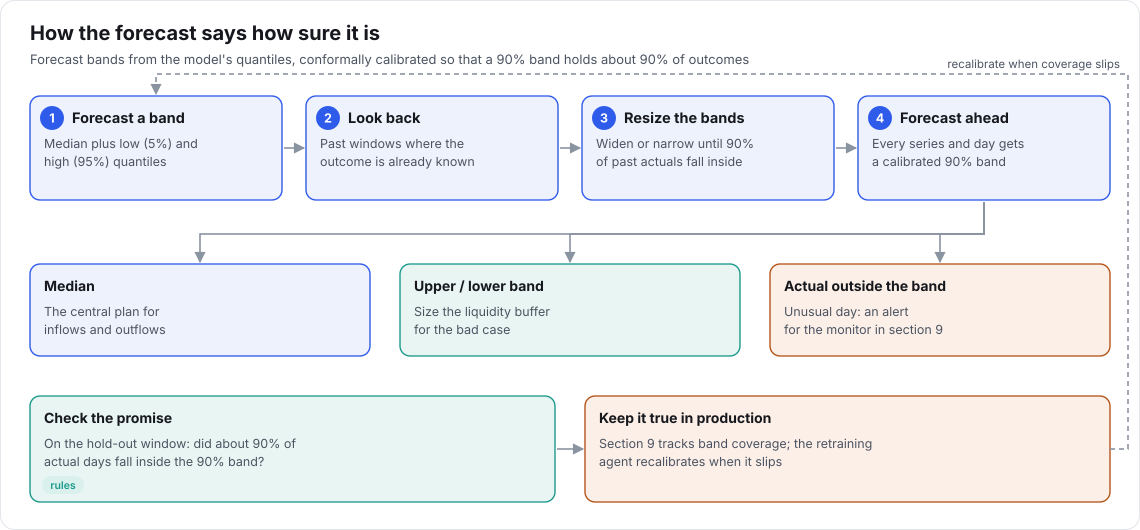

In [ ]:
# @title Diagram: how uncertainty is measured { display-mode: "form" }
from IPython.display import SVG, display
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1140 530" width="1140" height="530" font-family="Inter, \'Helvetica Neue\', Helvetica, Arial, sans-serif" role="img" aria-label="How the forecast says how sure it is"><defs><marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#8A93A0"/></marker></defs><rect x="0.5" y="0.5" width="1139" height="529" rx="14" fill="#FFFFFF" stroke="#E3E6EB"/><text x="30" y="40" font-size="20" fill="#16181D" font-weight="700" text-anchor="start">How the forecast says how sure it is</text><text x="30" y="64" font-size="13" fill="#4A5260" font-weight="400" text-anchor="start">Forecast bands from the model&#x27;s quantiles, conformally calibrated so that a 90% band holds about 90% of outcomes</text><rect x="30" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="52" cy="118" r="12" fill="#2F5BEA"/><text x="52" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">1</text><text x="72" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Forecast a band</text><text x="44" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Median plus low (5%) and</text><text x="44" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">high (95%) quantiles</text><path d="M284,148.0 L304,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="306" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="328" cy="118" r="12" fill="#2F5BEA"/><text x="328" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">2</text><text x="348" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Look back</text><text x="320" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Past windows where the</text><text x="320" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">outcome is already known</text><path d="M560,148.0 L580,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="582" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="604" cy="118" r="12" fill="#2F5BEA"/><text x="604" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">3</text><text x="624" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Resize the bands</text><text x="596" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Widen or narrow until 90%</text><text x="596" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">of past actuals fall inside</text><path d="M836,148.0 L856,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="858" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="880" cy="118" r="12" fill="#2F5BEA"/><text x="880" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">4</text><text x="900" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Forecast ahead</text><text x="872" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Every series and day gets</text><text x="872" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">a calibrated 90% band</text><rect x="30" y="264" width="340" height="92" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><text x="44" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Median</text><text x="44" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">The central plan for</text><text x="44" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">inflows and outflows</text><path d="M984.0,202 L984.0,234 L200.0,234 L200.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="400" y="264" width="340" height="92" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><text x="414" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Upper / lower band</text><text x="414" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Size the liquidity buffer</text><text x="414" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">for the bad case</text><path d="M984.0,202 L984.0,234 L570.0,234 L570.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="770" y="264" width="340" height="92" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><text x="784" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Actual outside the band</text><text x="784" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Unusual day: an alert</text><text x="784" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">for the monitor in section 9</text><path d="M984.0,202 L984.0,234 L940.0,234 L940.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="30" y="396" width="525" height="106" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><text x="44" y="423" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Check the promise</text><text x="44" y="448" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">On the hold-out window: did about 90% of</text><text x="44" y="466" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">actual days fall inside the 90% band?</text><rect x="42" y="476" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="63.0" y="489" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><rect x="585" y="396" width="525" height="106" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><text x="599" y="423" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Keep it true in production</text><text x="599" y="448" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Section 9 tracks band coverage; the retraining</text><text x="599" y="466" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">agent recalibrates when it slips</text><path d="M557,449.0 L583,449.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><path d="M1110,449.0 L1128,449.0 L1128,74 L156.0,74 L156.0,94" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)" stroke-dasharray="5 4"/><text x="1120" y="68" font-size="11.5" fill="#4A5260" font-weight="400" text-anchor="end">recalibrate when coverage slips</text></svg>'))

In [ ]:
# @title Uncertainty: band coverage before and after calibration, and automatic accuracy guards { display-mode: "form" }
cov_tab = pd.DataFrame({"with covariates": m_cov, "calibrated": m_cal}).loc[COVK] * (100 if max(m_cal[k] for k in COVK) <= 1 else 1)
nominal = [float(k.split("_")[1]) for k in COVK]
width_series = per.groupby("item_id").apply(lambda g: ((g["0.95"] - g["0.05"]) / g.item_id.map(SCALE)).mean()).sort_values()
inside_series = per.groupby("item_id").apply(lambda g: g["value"].between(g["0.05"], g["0.95"]).mean() * 100)
fig = make_subplots(rows=1, cols=3, subplot_titles=("Band coverage: promised vs measured (%)", "Share of days inside the 90% band, by series", "Band width by series (× average day)"))
fig.add_trace(go.Bar(x=[f"{n:.0f}% band" for n in nominal], y=nominal, name="promised", marker_color=GREY), 1, 1)
for name, col in (("with covariates", ORANGE), ("calibrated", TEAL)):
    fig.add_trace(go.Bar(x=[f"{n:.0f}% band" for n in nominal], y=cov_tab[name].values, name=name, marker_color=col), 1, 1)
fig.add_trace(go.Histogram(x=inside_series.values, nbinsx=15, marker_color=BLUE, showlegend=False), 1, 2)
fig.add_vline(x=90, line_dash="dot", line_color=DARK, row=1, col=2)
fig.add_trace(go.Bar(x=width_series.values, y=width_series.index, orientation="h", marker_color=ORANGE, showlegend=False), 1, 3)
fig.update_yaxes(showticklabels=False, row=1, col=3)
fig.update_layout(template="plotly_white", height=440, barmode="group", title="Uncertainty you can check: calibrated prediction bands on the hold-out", legend=dict(orientation="h", y=-0.15))
fig.show()

measured = float(cov_tab["calibrated"].iloc[-1]); promised = nominal[-1]
qs = per[[str(q) for q in QUANTILES]].to_numpy()
checks = [("no missing forecasts", bool(np.isfinite(per[QCOLS].to_numpy()).all())),
          ("quantiles are ordered (P5 ≤ P10 ≤ … ≤ P95)", bool((np.diff(qs, axis=1) >= -1e-6).mean() > 0.999)),
          ("beats the seasonal-naive forecast (MASE below 1)", bool(m_cal["mase"] < 1)),
          ("covariates do not hurt accuracy", bool(m_cov["mase"] <= m_plain["mase"] * 1.02)),
          (f"measured coverage within 10 points of the {promised:.0f}% promise", bool(abs(measured - promised) <= 10)),
          ("hold-out error within 25% of the backtest error (no selection overfit)", bool(m_cal["mase"] <= 1.25 * mase_of.get(CHAMPION, m_cal["mase"])))]
display(pd.DataFrame(checks, columns=["check", "passed"]).style.hide(axis="index").map(lambda v: f"color:{TEAL if v else RED};font-weight:600", subset=["passed"]))
record("uncertainty", method="model quantiles with conformal calibration on rolling windows", promised_coverage_pct=promised, measured_coverage_pct=measured,
       coverage_before_calibration_pct=float(cov_tab["with covariates"].iloc[-1]), average_band_width_vs_average_day=float(width_series.mean()))
record("limitations", note_1="fairness metrics do not apply to aggregate cash-flow series; consistency across segments is reported instead",
       note_2="regime changes outside the history (policy shocks, crises) widen errors until new data arrives; the monitor in section 9 is the control",
       note_3="the forecaster is zero-shot or lightly trained; it has not been validated on other institutions' data")
record("governance", frameworks_referenced="SR 11-7; SAMA model risk expectations; SAMA and NDMO data standards; CBB AI policy; SDAIA AI Ethics Principles; EU AI Act; ISO/IEC 42001",
       sanity_checks_passed=int(sum(v for _, v in checks)), sanity_checks_total=len(checks), human_approval_gates=sum(1 for a in AUDIT if a["actor"] == "human"))

In [ ]:
# @title In this run, in plain English { display-mode: "form" }
def _verdict(promised, measured, noun="sets"):
    gap = measured - promised
    if abs(gap) <= 2:
        return "close to the promise"
    return (f"above the promise (the {noun} are a little cautious, which is the safe side)" if gap > 0
            else f"below the promise: treat the {noun} with care and recalibrate before relying on them")

U = FACTS["uncertainty"]
pr, ms, before = U["promised_coverage_pct"], U["measured_coverage_pct"], U["coverage_before_calibration_pct"]
display(Markdown(f"""**In this run, in plain English**
- We promised that **{pr:.0f}%** of actual days would fall inside the band. Before calibration **{before:.1f}%** did; after calibration **{ms:.1f}%** did on the hold-out window, {_verdict(pr, ms, "bands")}.
- On average the band is **{U['average_band_width_vs_average_day']:.2f}×** the size of an average day for that series: the cash buffer that covers the bad case."""))

## 7.2 Regulatory evidence map
Fairness in the consumer-lending sense does not apply to aggregate cash-flow series, so the table reports consistency across segments in its place.

In [ ]:
# @title Model risk: which evidence in this notebook supports which expectation { display-mode: "form" }
REG_MAP = pd.DataFrame([
    ("Conceptual soundness", "Problem statement, data preparation log, feature rationale, model selection rule", "SR 11-7 · SAMA model risk expectations"),
    ("Data quality and lineage", "Data profile, agent action log with human approvals, leakage checks", "SAMA Data Management · NDMO standards · PDPL"),
    ("Outcomes analysis", "Hold-out metrics, evaluation dashboards, segment performance", "SR 11-7 · Basel sound-practice principles"),
    ("Uncertainty", "Conformal prediction with measured coverage, calibration", "SR 11-7 (model limitations) · CBB AI policy"),
    ("Consistency across segments", "Error and band coverage by segment and by series", "SR 11-7 (outcomes analysis) · CBB AI policy"),
    ("Explainability", "Global drivers and per-decision explanations", "SDAIA AI Ethics Principles · EU AI Act"),
    ("Ongoing monitoring", "Drift monitoring, performance tracking, retraining with approval gate", "SR 11-7 · SAMA model risk expectations"),
    ("Documentation", "Generated model card with grounding check, audit trail", "SR 11-7 · ISO/IEC 42001"),
], columns=["Expectation", "Evidence produced in this notebook", "Frameworks it speaks to"])
display(REG_MAP.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
        .set_caption("Frameworks are named for orientation only. The bank's Compliance and Risk functions own the control mapping; "
                     "no clause-level compliance is claimed here."))

# 8 · Artefacts before production

## 8.1 Model card
The model card is written by an LLM **only from the facts this notebook recorded**, against a documentation standard written for a model-risk committee:

1. **Choose the writer.** The **Lexsi LLM gateway** (`/gateway/v1/chat/completions`): one API for every provider registered in the Lexsi project, with each call traced there. Section 1 sets it to Claude Sonnet 5.5 through Open Router, as registered in the Lexsi project; add the `LEXSI_API_TOKEN` Colab secret. Without them the notebook falls back to open weights on this GPU, then to a template. Only the aggregate fact sheet is sent, never ledger rows.
2. **Send a full brief.** A system prompt (role, citation and number rules, what each of the 14 sections must contain, a self-check), the card template, the fact sheet grouped by section with a citation key per fact, and plain-English metric notes. Expand the prompt below to read exactly what is sent.
3. **Check automatically.** Every number must carry a citation key; each key must exist; each number must match its fact; all 14 sections must be present; no invented approvals, clause numbers, dates or compliance claims.
4. **Revise once.** If the checks fail, the issue list goes back to the writer for one rewrite. Whatever remains is listed for a human reviewer.

In [ ]:
# @title The documentation standard: system prompt, 14-section template, metric notes { display-mode: "form" }
CARD_SECTIONS = [
    "0. Document control", "1. Executive summary", "2. Intended use and scope", "3. Data", "4. Methodology and model selection",
    "5. Performance on held-out data", "6. Explainability", "7. Uncertainty and calibration", "8. Fairness",
    "9. Limitations and known risks", "10. Monitoring, alerting and retraining", "11. Regulatory alignment",
    "12. Approvals and sign-off", "13. Change log",
]

SYSTEM_PROMPT = textwrap.dedent("""
# ROLE
You are a senior model-risk documentation specialist at a Gulf bank supervised by SAMA (Saudi Central Bank) and the
Central Bank of Bahrain. You write the model card that goes to three readers:
- the model-risk committee, who decide whether the model may be used and read sections 0, 1, 9 and 12 first;
- the independent validator, who checks every number against the evidence;
- the supervisor's examiner, who looks for honest limitations and working controls.
A card that overstates, invents or cannot be traced is worse than no card. Precision and traceability come before style.

# SOURCE OF TRUTH
The user message contains a FACT SHEET. It is the only source you may use. Each fact has a key, for example
`performance.roc_auc = 0.7277`. The part before the dot is the fact group (data, preparation, selection, performance ...).

# CITATION RULES
1. Every number you write is followed immediately by the key it came from, in square brackets.
   Right:  The model reaches a ROC AUC of 0.728 [performance.roc_auc] on 3,000 unseen loans [performance.test_rows].
   Wrong:  The model reaches a ROC AUC of about 0.73 on the test set.            (no key; "about")
   Wrong:  ROC AUC improved by 0.015 over the baseline.                           (a number you computed)
2. Inside a table, put the key in the "Source" column of the same row instead of in brackets.
3. Use a key only for the fact it names. Never attach a key to a different number.
4. Text facts (model names, feature names, methods, rules) are quoted as written and also carry their key.

# NUMBER RULES
5. Round, never change: scores to 3 decimals, counts to whole numbers with thousands separators, percentages to 1 decimal.
6. A fact stored as a share (0.9017) may be written as a percentage (90.2%) with the same key. Say which it is.
7. Do NO arithmetic. Do not write differences, ratios, sums, averages or percentage changes that are not themselves facts.
   To compare two facts, state both with their keys and say which is higher, lower or about equal.
8. If something the template asks for is not in the fact sheet, write exactly "Not recorded". Never estimate or infer it.

# NEVER WRITE
9. Dates, people's names, team names, committee names, ticket numbers or version numbers that are not in the fact sheet.
10. Approvals, validation outcomes or sign-offs. Every approval is "Pending". The risk tier is "To be assigned by Model Risk Management".
11. Regulation article, clause or circular numbers, and any statement that the model "complies", "is compliant" or "meets"
    a regulation. Name a framework only if it appears in the fact sheet, and describe the evidence, not compliance.
12. Marketing language: "state-of-the-art", "robust", "best-in-class", "ensures", "guarantees", "cutting-edge".
13. Advice the facts do not support (for example recommending a threshold or a new feature).

# WHAT EACH SECTION MUST CONTAIN
0 Document control: the table, filled from use_case.* and the values marked "given".
1 Executive summary: exactly five bullets, in this order: what the model decides and for whom; which model was selected and
  how (selection.*); the headline held-out result with its metric explained in a few words (performance.*); how uncertainty
  is handled (uncertainty.*); the single most important risk to watch (limitations.* or monitoring.*). No bullet over 35 words.
2 Intended use and scope: the decision supported, intended users (only if recorded), the population the data covers, and an
  "Out of scope" list of at least three uses the facts do not support (other products, other populations, automated decisions
  without the recorded human review, and so on, phrased as limits of the evidence).
3 Data: source and size; a table of the data sets with rows and purpose; candidate features and what remained after
  preparation; what the data-preparation agent removed and why, including leakage controls (preparation.*); data-quality
  findings (missing values, skew); engineered features (features.*).
4 Methodology and model selection: how many candidates were raced and how many succeeded; the selection rule in plain words;
  the selected model and whether it is zero-shot, fine-tuned or trained; the hyperparameter search; why it won
  (selection.selection_reason if recorded); the hardware (training.*).
5 Performance on held-out data: the table with one row per performance.* fact and a plain-English "What it means" taken from
  the METRIC NOTES; then two or three sentences comparing the selected model with the best classic baseline (state both
  numbers, no arithmetic) and saying what the result means for the decision.
6 Explainability: the global method and the top drivers named in plain words; how single decisions are explained; a caution
  that importance shows association with the prediction, not cause.
7 Uncertainty and calibration: the method; promised versus measured coverage; what happens to uncertain cases; calibration
  figures if recorded.
8 Fairness: the table with one row per fairness.* fact; the attribute used and the number of groups; a neutral reading of the
  largest gap; a statement that other protected attributes were not assessed if the facts say so. No legal conclusions.
  For forecasting models write that fairness metrics do not apply and report consistency across segments instead.
9 Limitations and known risks: a numbered list of at least four items. Each item has three parts: the limitation, why it
  matters for the decision, and the control or monitor that addresses it (from monitoring.*, uncertainty.* or governance.*),
  or "No control recorded".
10 Monitoring, alerting and retraining: the monitors; the alert thresholds if recorded; how alerts reach the retraining
  agent; the champion-challenger rule and promotion margin; every human approval gate; then what monitoring has observed so
  far and every retraining event (retraining.*). If there are no observations yet, say "No production observations yet".
11 Regulatory alignment: the table. For each expectation list the card sections that hold the evidence, write the status as
  "Evidence provided" or "Not recorded", and cite one fact key. Close with one sentence naming the frameworks in
  governance.frameworks_referenced and stating that control mapping is owned by the bank's Compliance function.
12 Approvals and sign-off: the table with every cell "Pending", followed by "Open items for the validator": a bullet for
  every "Not recorded" you wrote in the card, or "None" if there were none.
13 Change log: every change supplied by the user, as bullets in the order given, or "Initial version".

# STYLE
- Plain English, short sentences, active voice. Explain each metric in a few words the first time it appears.
- Prefer tables for numbers and bullets for lists. No paragraph longer than four sentences.
- Feature names are written as recorded, in backticks.
- Target length: 900 to 1,500 words excluding tables.

# BEFORE YOU ANSWER, CHECK
- Every number has a key next to it or in its row, and the key exists in the fact sheet.
- No number was computed by you. No date, name, approval or clause number was invented.
- All 14 headings are present, numbered 0 to 13, in order, exactly as in the template.
- Every "Not recorded" in the card is listed under section 12.

# EXTRA RULES
- Square brackets contain ONLY a fact key, nothing else. Never write notes, reasoning or "not recorded" inside brackets.
  If the exact fact is missing, use the closest fact that is recorded with its own key, or write "Not recorded" in plain text.
- In section 11 the status may be "Evidence provided", "Partly provided: <which part>", "Not applicable: <why>" or "Not recorded".
  Use "Not recorded" only when no section of the card holds any evidence for that expectation.

# OUTPUT
Markdown only. Start with the line "# Model card · <use-case name>" and end with the last line of section 13.
No preamble, no closing remarks, no code fence around the card.
""").strip()

CARD_TEMPLATE = textwrap.dedent("""
# Model card · <use-case name>

## 0. Document control
| Field | Value | Source |
|---|---|---|
| Model name | <use-case name> | use_case.name |
| Model version | <version> | use_case.version |
| Card version | <card version given by the user> | given |
| Status | Draft, pending independent validation | given |
| Model owner | <owner> | use_case.owner |
| Risk tier | To be assigned by Model Risk Management | given |
| Written by | <writer given by the user> | given |

## 1. Executive summary
<five bullets as specified>

## 2. Intended use and scope
<decision supported, intended users, population in scope>

**Out of scope**
<at least three bullets>

## 3. Data
<source and size in one or two sentences>

| Data set | Rows | Used for | Source |
|---|---|---|---|
<one row per recorded data set>

<features before and after preparation; what the agent removed and why; leakage controls; data-quality findings; engineered features>

## 4. Methodology and model selection
<candidates, selection rule, selected model, adaptation, hyperparameter search, why it won, hardware>

## 5. Performance on held-out data
| Metric | Value | What it means | Source |
|---|---|---|---|
<one row per recorded performance fact>

<comparison with the best classic baseline, and what the result means for the decision>

## 6. Explainability
<global method and top drivers; single-decision explanations; the association-not-cause caution>

## 7. Uncertainty and calibration
<method, promised vs measured coverage, treatment of uncertain cases, calibration>

## 8. Fairness
| Metric | Value | Source |
|---|---|---|
<one row per recorded fairness fact, or a single row "Not recorded">

<neutral interpretation and limits>

## 9. Limitations and known risks
<numbered list; each item: limitation · why it matters · control or monitor>

## 10. Monitoring, alerting and retraining
<monitors, thresholds, alert routing, champion-challenger rule, approval gates>

**Observed so far**
<observations and retraining events, or "No production observations yet">

## 11. Regulatory alignment
| Expectation | Evidence in this card | Status | Source |
|---|---|---|---|
| Conceptual soundness | <sections> | <status> | <key> |
| Data quality and lineage | <sections> | <status> | <key> |
| Outcomes analysis | <sections> | <status> | <key> |
| Ongoing monitoring | <sections> | <status> | <key> |
| Explainability and fairness | <sections> | <status> | <key> |
| Documentation and change control | <sections> | <status> | <key> |

<one sentence naming the frameworks in the fact sheet; control mapping is owned by the bank's Compliance function>

## 12. Approvals and sign-off
| Role | Name | Decision | Date |
|---|---|---|---|
| Model owner | Pending | Pending | Pending |
| Independent model validation | Pending | Pending | Pending |
| Model risk committee | Pending | Pending | Pending |

**Open items for the validator**
<one bullet per "Not recorded" in this card, or "None">

## 13. Change log
<bullets>
""").strip()

# Plain-English meanings the writer may use in the "What it means" column (deliberately free of numbers)
METRIC_NOTES = {
    "roc_auc": "how well the model ranks risky cases above safe ones; higher is better",
    "average_precision": "how concentrated the true positives are among the highest scores; higher is better",
    "f1": "balance of precision and recall at the chosen threshold; higher is better",
    "precision": "of the cases the model flags, the share that are truly positive",
    "recall": "of the truly positive cases, the share the model flags",
    "accuracy": "share of all cases classified correctly at the chosen threshold",
    "balanced_accuracy": "accuracy averaged over the two classes, so the rarer class counts equally",
    "mcc": "single summary of the confusion matrix that stays fair when classes are unbalanced; higher is better",
    "brier": "average squared gap between predicted probability and outcome; lower is better",
    "log_loss": "penalty for confident wrong probabilities; lower is better",
    "ks": "largest separation between the score distributions of the two classes; higher is better",
    "gini": "a rescaling of ROC AUC used in credit scoring; higher is better",
    "threshold": "the score above which a case is flagged; chosen on validation data",
    "r2": "share of the variation in the target that the model explains; higher is better",
    "rmse": "typical size of the error, with large errors weighted more; in the target's units; lower is better",
    "mae": "average size of the error in the target's units; lower is better",
    "median_abs_error": "the error size that half of the predictions stay within; lower is better",
    "mape_pct": "average error as a percentage of the actual value; lower is better",
    "explained_variance": "share of the target's variation captured by the predictions; higher is better",
    "max_error": "the single largest error on the test set",
    "within_20pct_share": "percentage of predictions that land within one fifth of the actual value",
    "mase": "forecast error relative to a seasonal-naive forecast; below one beats it; lower is better",
    "wql": "error of the whole predicted range, not just the middle; lower is better",
    "smape": "symmetric percentage error of the median forecast; lower is better",
    "wape_pct": "total absolute error as a percentage of total actual flow; lower is better",
    "inside_90_band_pct": "percentage of actual outcomes that fell inside the ninety-percent band",
    "inside_80_band_pct": "percentage of actual outcomes that fell inside the eighty-percent band",
    "batch_rows_per_second": "scoring throughput in batch mode",
    "measured_coverage": "share of test cases whose true outcome fell inside the prediction set or interval",
    "disparate_impact_ratio": "lowest group selection rate divided by the highest; closer to one means more equal",
    "demographic_parity_difference": "gap between the highest and lowest group selection rates; closer to zero is more equal",
    "equal_opportunity_difference": "gap between groups in the share of true positives that are flagged",
    "equalized_odds_difference": "the larger of the gaps in true-positive and false-positive rates between groups",
    "predictive_parity_difference": "gap between groups in the precision of the flag",
    "max_feature_psi": "largest population stability index of any monitored feature; higher means more drift",
}

SECTION_GUIDE = {"use_case": "0, 1, 2", "data": "3", "preparation": "3", "features": "3", "selection": "4", "training": "4",
                 "performance": "1, 5", "explainability": "6", "uncertainty": "7", "fairness": "8", "limitations": "9",
                 "monitoring": "10", "retraining": "10, 13", "governance": "11"}


def flatten_facts(facts):
    flat = {}
    for sec, vals in facts.items():
        for k, v in vals.items():
            if isinstance(v, (np.floating, np.integer)):
                v = float(v)
            if isinstance(v, float) and not np.isfinite(v):
                continue
            flat[f"{sec}.{k}"] = v
    return flat


def build_messages(facts, changes, version_label, writer_label):
    flat = flatten_facts(facts)
    groups = {}
    for k, v in flat.items():
        groups.setdefault(k.split(".", 1)[0], []).append(f"- {k} = {v}")
    fact_block = "\n\n".join(f"[{g}]  (mainly for section {SECTION_GUIDE.get(g, 'as relevant')})\n" + "\n".join(lines) for g, lines in groups.items())
    notes = "\n".join(f"- {k}: {METRIC_NOTES[k.split('.', 1)[1]]}" for k in flat if k.split(".", 1)[1] in METRIC_NOTES)
    change_lines = "\n".join(f"- {c}" for c in changes) if changes else "- Initial version"
    user = (f"Write the model card, card version {version_label}. It is being written by: {writer_label}.\n\n"
            f"=== TEMPLATE (reproduce the headings and tables exactly; replace each <instruction>) ===\n\n{CARD_TEMPLATE}\n\n"
            f"=== FACT SHEET ({len(flat)} facts; the only source you may use; cite the key after every number) ===\n\n{fact_block}\n\n"
            f"=== METRIC NOTES (plain-English meanings for the 'What it means' column) ===\n{notes or '- none'}\n\n"
            f"=== CHANGES SINCE THE PREVIOUS VERSION (for section 13) ===\n{change_lines}\n")
    return SYSTEM_PROMPT, user


def writer_label():
    return f"{LEXSI_PROVIDER} · {LEXSI_MODEL} through the Lexsi LLM gateway" if WRITER == "lexsi" else (
        "open-weights model on the notebook GPU" if WRITER not in ("template",) else "template writer (no LLM)")


def show_prompt(version_label="v1", changes=None):
    system, user = build_messages(FACTS, changes, version_label, writer_label())
    display(Markdown(f"**Prompt sent to the writer:** system prompt {len(system):,} characters · user message {len(user):,} characters "
                     f"(about {(len(system) + len(user)) // 4:,} tokens) · {len(flatten_facts(FACTS))} facts · no customer-level data."))
    for title, body in (("System prompt: role, citation rules, section requirements, self-check", system),
                        ("User message: template, fact sheet, metric notes, changes", user)):
        display(HTML(f"<details><summary><b>{title}</b> · click to expand</summary>"
                     f"<pre style='white-space:pre-wrap;font-size:12px'>{_html.escape(body)}</pre></details>"))

In [ ]:
# @title Facts for the card { display-mode: "form" }
record("use_case", name=USE_CASE_NAME, task="probabilistic time-series forecasting with anomaly monitoring", decision_supported=DECISION_SUPPORTED,
       owner="[model owner]", version="v1")
record("data", holdout_rows=len(actual), holdout_steps_per_series=HORIZON)
record("selection", best_classic_model="TabularTS-GBM", best_classic_backtest_mase=float(mase_of.get("TabularTS-GBM", np.nan)),
       hyperparameter_search=f"TabularTS-GBM boosting rounds {list(gbm_sweep.max_iter)} -> {GBM_PARAMS['max_iter']}; "
                             f"{PRIMARY} context length {list(ctx_sweep.context)} -> {BEST_CONTEXT}")
record("uncertainty", treatment_of_uncertain_cases="every forecast is returned with its 80% and 90% bands, so planners see the range, not one number")
record("monitoring", plan="window-by-window monitors (series drift, forecast error, band coverage, data quality, scheduled review) with warning and critical "
       "thresholds; critical alerts go to a retraining webhook; an agent runs a champion-challenger review and promotes only after human approval")

In [ ]:
show_prompt("v1")               # exactly what the writer receives

In [ ]:
# @title Writers (Lexsi gateway, local GPU, template) and the automatic checks { display-mode: "form" }
_LLM = {}
NEED_GB = {"gpt-oss-120b": 70, "32B": 70, "7B": 18}


def _load_local():
    import gc
    from transformers import AutoModelForCausalLM, AutoTokenizer
    for name in LOCAL_WRITERS if WRITER in ("local", "lexsi") else [WRITER]:
        need = next((g for k, g in NEED_GB.items() if k in name), 0)
        free_gb = torch.cuda.mem_get_info()[0] / 1e9
        if need and free_gb < need:
            print(f"skipping {name}: needs about {need} GB of free GPU memory, {free_gb:.0f} GB available")
            continue
        try:
            t0 = time.time(); gc.collect(); torch.cuda.empty_cache()
            tok = AutoTokenizer.from_pretrained(name)
            model = AutoModelForCausalLM.from_pretrained(name, torch_dtype="auto" if "gpt-oss" in name else torch.bfloat16, device_map="auto")
            _LLM.update(tok=tok, model=model, name=name, load_seconds=round(time.time() - t0, 1), gpu_gb=round(torch.cuda.memory_allocated() / 1e9, 1))
            print(f"loaded {name} in {_LLM['load_seconds']}s · GPU memory in use {_LLM['gpu_gb']} GB")
            return
        except Exception as exc:
            print(f"could not load {name} → trying the next option ({str(exc)[:120]})")
            _LLM.clear(); gc.collect(); torch.cuda.empty_cache()
    raise RuntimeError("no local writer could be loaded")


def _split_harmony(text):
    final = re.search(r"<\|channel\|>final<\|message\|>(.*?)(?:<\|return\|>|<\|end\|>|$)", text, flags=re.S)
    analysis = re.search(r"<\|channel\|>analysis<\|message\|>(.*?)(?:<\|end\|>|<\|start\|>|$)", text, flags=re.S)
    if final:
        return final.group(1).strip(), (analysis.group(1).strip() if analysis else "")
    return re.sub(r"<\|[^|]+\|>", "", text).strip(), ""


def write_local(system, messages):
    if "model" not in _LLM:
        _load_local()
    tok, model, name = _LLM["tok"], _LLM["model"], _LLM["name"]
    harmony = "gpt-oss" in name
    ids = tok.apply_chat_template([{"role": "system", "content": system}, *messages], add_generation_prompt=True,
                                  return_tensors="pt", **({"reasoning_effort": "medium"} if harmony else {})).to(model.device)
    out = model.generate(ids, max_new_tokens=9000 if harmony else 4000, do_sample=False)
    raw = tok.decode(out[0, ids.shape[1]:], skip_special_tokens=not harmony)
    text, reasoning = _split_harmony(raw) if harmony else (raw.strip(), "")
    return text, reasoning, {"writer": name, "input_tokens": int(ids.shape[1]), "output_tokens": int(out.shape[1] - ids.shape[1]),
                             "load_seconds": _LLM["load_seconds"], "gpu_memory_gb": _LLM["gpu_gb"]}


def _as_prompt(system, messages):
    # text/generation takes one prompt string: the instructions, the task and, on the revision pass, the draft and the fixes
    parts = [f"### INSTRUCTIONS\n{system}"]
    for m in messages:
        title = "YOUR PREVIOUS DRAFT" if m["role"] == "assistant" else ("TASK" if len(parts) == 1 else "REVISION REQUEST")
        parts.append(f"### {title}\n{m['content']}")
    parts.append("### OUTPUT\nWrite the complete model card now, in Markdown, starting with the line '# Model card'.")
    return "\n\n".join(parts)


def _read(body):
    # text, token counts and extras from either response shape
    det = body.get("details")
    if isinstance(det, dict) and isinstance(det.get("result"), dict):                   # text/generation
        res = det["result"]
        return res.get("output") or "", (res.get("audit_trail") or {}).get("tokens") or {}, res
    if body.get("choices"):                                                               # chat/completions
        ch = body["choices"][0]; msg = ch.get("message") or {}
        content = msg.get("content") or ch.get("text") or ""
        if isinstance(content, list):
            content = "".join(b.get("text", "") for b in content if isinstance(b, dict))
        return content, body.get("usage") or {}, {"finish_reason": ch.get("finish_reason"),
                                                  "reasoning": msg.get("reasoning") or msg.get("reasoning_content") or ""}
    raise RuntimeError(f"no text in the gateway response: {str(det or body)[:300]}")    # e.g. blocked by a guardrail


def write_lexsi(system, messages):
    global LEXSI_ENDPOINT, LEXSI_REASONING
    t0, prompt = time.time(), _as_prompt(system, messages)
    chat_msgs = [{"role": "system", "content": system}, *messages]
    max_tokens = LEXSI_MAX_TOKENS
    for attempt in range(2):
        if LEXSI_ENDPOINT == "text":
            r = lexsi_generate(prompt, max_tokens)
            if r.status_code == 400 and "Provider must be one of" in r.text:
                print(f"text/generation does not accept provider '{LEXSI_PROVIDER}' on this gateway → same model through chat/completions")
                LEXSI_ENDPOINT = "chat"
        if LEXSI_ENDPOINT == "chat":
            r = lexsi_chat(chat_msgs, max_tokens, LEXSI_REASONING)
            if r.status_code in (400, 422) and LEXSI_REASONING:
                print(f"the call was rejected with the reasoning setting ({r.text[:120]}) → retrying with the model's default")
                LEXSI_REASONING = None
                r = lexsi_chat(chat_msgs, max_tokens)
        try:
            body = r.json()
        except ValueError:
            body = {"detail": r.text[:300]}
        if r.status_code != 200:
            hint = {401: "check the LEXSI_API_TOKEN secret", 403: "the token has no access to this project",
                    404: f"check that '{LEXSI_MODEL}' is registered in project {LEXSI_PROJECT} under provider '{LEXSI_PROVIDER}'",
                    504: "the gateway timed out; lower LEXSI_MAX_TOKENS or keep LEXSI_REASONING low"}.get(r.status_code, "see the gateway message")
            raise RuntimeError(f"Lexsi gateway returned {r.status_code}: {str(body.get('detail', body))[:300]} → {hint}")
        text, tokens, res = _read(body)
        finish = str(res.get("finish_reason") or "")
        if finish in ("length", "max_tokens") and attempt == 0:
            print(f"answer cut off at {max_tokens:,} tokens (thinking tokens count against the limit) → asking again with {max_tokens * 2:,}")
            max_tokens *= 2
            continue
        break
    if finish in ("length", "max_tokens"):
        print(f"⚠️ still cut off at {max_tokens:,} tokens; the checks below will list the missing sections")
    if prompt[-200:] in text:                                   # some text-generation backends echo the prompt
        text = text.split(prompt[-200:])[-1]
    if "# Model card" in text:
        text = text[text.index("# Model card"):]
    text = re.sub(r"^```(?:markdown)?\s*|\s*```$", "", text.strip())
    return text, res.get("reasoning") or "", {
        "writer": f"{LEXSI_PROVIDER} · {LEXSI_MODEL} (Lexsi, {'text/generation' if LEXSI_ENDPOINT == 'text' else 'chat/completions'})",
        "http_status": r.status_code, "http_version": r.http_version, "max_tokens_used": max_tokens, "reasoning_setting": str(LEXSI_REASONING),
        "input_tokens": tokens.get("prompt_tokens") or tokens.get("input_tokens") or 0,
        "output_tokens": tokens.get("completion_tokens") or tokens.get("output_tokens") or 0,
        "reasoning_tokens": tokens.get("reasoning_tokens") or (tokens.get("completion_tokens_details") or {}).get("reasoning_tokens"),
        "token_explanations_returned": any("expla" in k.lower() for k in res), "finish_reason": finish,
        "lexsi_project": LEXSI_PROJECT, "gateway_seconds": round(time.time() - t0, 1)}


def write_template(facts, changes, version_label):
    """Deterministic writer: fills the same template from the facts, with a citation after every number."""
    flat = flatten_facts(facts)
    def cite(key, label=None):
        v = flat.get(key)
        if v is None:
            return "Not recorded"
        if isinstance(v, float):
            v = f"{v:,.4g}" if abs(v) < 1000 else f"{v:,.0f}"
        return f"{v} [{key}]"
    rows = lambda sec: [(k.split(".", 1)[1], k) for k in flat if k.startswith(sec + ".")]
    table = lambda sec: "\n".join(f"| {name.replace('_', ' ')} | {cite(k)} | {k} |" for name, k in rows(sec)) or "| Not recorded | Not recorded | — |"
    uc = lambda k: flat.get(f"use_case.{k}", "Not recorded")
    L = [f"# Model card · {uc('name')}", "", "## 0. Document control", "| Field | Value | Source |", "|---|---|---|",
         f"| Model name | {uc('name')} | use_case.name |", f"| Model version | {uc('version')} | use_case.version |",
         f"| Card version | {version_label} | given |", "| Status | Draft, pending independent validation | given |",
         f"| Model owner | {uc('owner')} | use_case.owner |", "| Risk tier | To be assigned by Model Risk Management | given |",
         "| Written by | template writer (no LLM) | given |", "",
         "## 1. Executive summary", f"- Decision supported: {uc('decision_supported')}.",
         f"- Selected model: {cite('selection.selected_model')}.", f"- Selection metric: {cite('selection.selection_metric')}.",
         "- Held-out performance: see section 5.", "- Main risk to watch: drift in the population; see sections 9 and 10.", "",
         "## 2. Intended use and scope", f"- Task: {uc('task')}.", f"- Decision supported: {uc('decision_supported')}.",
         "- Out of scope: any use not described in the facts.", "",
         "## 3. Data", "| Item | Value | Source |", "|---|---|---|", table("data"), table("preparation"), table("features"), "",
         "## 4. Methodology and model selection", "| Item | Value | Source |", "|---|---|---|", table("selection"), table("training"), "",
         "## 5. Performance on held-out data", "| Metric | Value | What it means | Source |", "|---|---|---|---|",
         "\n".join(f"| {n.replace('_', ' ')} | {cite(k)} | — | {k} |" for n, k in rows("performance")) or "| Not recorded | — | — | — |", "",
         "## 6. Explainability", "| Item | Value | Source |", "|---|---|---|", table("explainability"), "",
         "## 7. Uncertainty and calibration", "| Item | Value | Source |", "|---|---|---|", table("uncertainty"), "",
         "## 8. Fairness", "| Metric | Value | Source |", "|---|---|---|", table("fairness"), "",
         "## 9. Limitations and known risks", *[f"{i}. {flat[k]}" for i, k in enumerate([k for k in flat if k.startswith("limitations.")], 1)], "",
         "## 10. Monitoring, alerting and retraining", "| Item | Value | Source |", "|---|---|---|", table("monitoring"), table("retraining"), "",
         "## 11. Regulatory alignment", "| Expectation | Evidence in this card | Status | Source |", "|---|---|---|---|",
         "| Conceptual soundness | Sections 3–4 | Evidence provided | selection.selection_rule |",
         "| Data quality and lineage | Section 3 | Evidence provided | preparation.features_removed |",
         "| Outcomes analysis | Section 5 | Evidence provided | performance.evaluated_on |",
         "| Ongoing monitoring | Section 10 | Evidence provided | monitoring.plan |",
         "| Explainability and fairness | Sections 6, 8 | Evidence provided | explainability.method |",
         "| Documentation and change control | Sections 12–13 | Evidence provided | governance.human_approval_gates |", "",
         f"Frameworks referenced: {flat.get('governance.frameworks_referenced', 'Not recorded')}. Control mapping is owned by the bank's Compliance function.", "",
         "## 12. Approvals and sign-off", "| Role | Name | Decision | Date |", "|---|---|---|---|",
         "| Model owner | Pending | Pending | Pending |", "| Independent model validation | Pending | Pending | Pending |",
         "| Model risk committee | Pending | Pending | Pending |", "",
         "## 13. Change log", *([f"- {c}" for c in changes] if changes else ["- Initial version"])]
    return "\n".join(L), "", {"writer": "template writer (no LLM)"}



FORBIDDEN = [(r"\b(article|clause|circular)\s+(no\.?\s*)?\d", "cites a regulation article or clause number"),
             (r"\b(approved|validated|signed off)\s+(by|on)\b", "claims an approval or validation"),
             (r"\b(fully|is)\s+compliant\b|\bcomplies with\b", "claims compliance"),
             (r"\b(19|20)\d{2}-\d{2}-\d{2}\b", "contains a date that is not in the facts")]


def _matches(value, written):
    """Does the number as written match the fact value (allowing rounding and share↔percent)?"""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return False
    d = len(written.split(".")[1]) if "." in written else 0
    n = float(written)
    tol = 0.5 * 10 ** (-d) + 1e-9
    return abs(v - n) <= tol or abs(v * 100 - n) <= tol or (abs(v) >= 1000 and abs(v - n) <= max(tol, abs(v) * 0.0005))


def check_card(card, facts, changes=None):
    """Automatic hallucination and completeness checks on a generated card."""
    flat = flatten_facts(facts)
    card = re.sub(r"\b[Ss]ections?\s+\d+(?:\s*[–-]\s*\d+)?(?:\s*(?:,|and)\s*\d+)*", "Section", card)   # section references are not facts
    text = card.replace(",", "")
    issues = []
    # 1. every cited key exists, and the number next to it matches the fact
    cites = list(re.finditer(r"\[([a-z_]+\.[a-z0-9_]+)\]", card))
    bad_keys = sorted({m.group(1) for m in cites if m.group(1) not in flat})
    mism = []
    for m in cites:
        k = m.group(1)
        if k not in flat:
            continue
        before = card[max(0, m.start() - 40):m.start()].replace(",", "")
        nums = re.findall(r"-?\d+(?:\.\d+)?", before)
        if nums and isinstance(flat[k], (int, float)) and not isinstance(flat[k], bool) and not _matches(flat[k], nums[-1]):
            mism.append(f"{nums[-1]} [{k}] (fact = {flat[k]})")
    # table rows: value cell vs source cell
    for row in re.findall(r"^\|(.+)\|\s*$", card, flags=re.M):
        cells = [c.strip() for c in row.split("|")]
        if len(cells) >= 3 and cells[-1] in flat and isinstance(flat[cells[-1]], (int, float)) and not isinstance(flat[cells[-1]], bool):
            nums = re.findall(r"-?\d+(?:\.\d+)?", " ".join(cells[1:-1]).replace(",", ""))
            if nums and not any(_matches(flat[cells[-1]], n) for n in nums):
                mism.append(f"table row '{cells[0]}': {nums[0]} vs {cells[-1]} = {flat[cells[-1]]}")
    # 2. numbers that are not grounded in any fact (prose only; ignore headings, list numbering and small integers)
    known = [v for v in flat.values() if isinstance(v, (int, float)) and not isinstance(v, bool)]
    known += [float(n) for v in flat.values() if isinstance(v, str) for n in re.findall(r"\d+(?:\.\d+)?", v.replace(",", ""))]
    known += [float(n) for k in flat for n in re.findall(r"\d+", k)]          # numbers that are part of a fact's name, e.g. the 80% band
    body = re.sub(r"^#+ .*$", "", text, flags=re.M)
    body = re.sub(r"^\s*\d+\.\s", "", body, flags=re.M)
    nums = [n for n in re.findall(r"(?<![\w.\[])-?\d+(?:\.\d+)?(?![\w\]])", body) if not (n.isdigit() and int(n) <= 13)]
    change_nums = set(re.findall(r"\d+(?:\.\d+)?", " ".join(changes or []).replace(",", "")))
    ungrounded = sorted({n for n in nums if n not in change_nums and not any(_matches(v, n) for v in known)})
    # 3. structure and forbidden content
    missing_sections = [s for s in CARD_SECTIONS if not re.search(r"^##\s*" + re.escape(s), card, flags=re.M)]
    fact_text = " ".join(str(v) for v in flat.values()).lower()
    forbidden = [why for pat, why in FORBIDDEN
                 if any(m.group(0).lower() not in fact_text for m in re.finditer(pat, card, flags=re.I))]     # allowed if it is a recorded fact
    notes = [m.group(0) for m in re.finditer(r"\[([^\]\n]{1,300})\]", card)
             if not re.fullmatch(r"[a-z_]+\.[a-z0-9_]+", m.group(1)) and "." in m.group(1) and "_" in m.group(1)]
    if notes: issues.append(f"brackets must contain only a fact key; rewrite these as plain text with a proper key: {'; '.join(n[:100] for n in notes[:5])}")
    if bad_keys: issues.append(f"cites keys that do not exist: {', '.join(bad_keys[:8])}")
    if mism: issues.append(f"numbers that do not match their cited fact: {'; '.join(mism[:8])}")
    if ungrounded: issues.append(f"numbers not found in the facts: {', '.join(ungrounded[:12])}")
    if missing_sections: issues.append(f"missing sections: {', '.join(missing_sections)}")
    issues += [f"forbidden content: {f}" for f in forbidden]
    report = {"citations": len(cites), "invalid_citation_keys": len(bad_keys), "malformed_citations": len(notes), "number_mismatches": len(mism),
              "ungrounded_numbers": len(ungrounded), "sections_present": f"{len(CARD_SECTIONS) - len(missing_sections)}/{len(CARD_SECTIONS)}",
              "forbidden_content": len(forbidden)}
    checked = max(len(nums) + len(cites), 1)
    report["grounded_pct"] = round(100 * (1 - (len(ungrounded) + len(mism)) / checked), 1)
    report["passed"] = not issues
    return report, issues


def generate_model_card(facts, changes=None, version_label="v1"):
    """Draft → automatic checks → one revision with the issue list (if needed) → final checks."""
    facts = json.loads(json.dumps(facts, default=float))
    trace, rounds = {"card_version": version_label}, []
    system, user = build_messages(facts, changes, version_label, writer_label())
    messages = [{"role": "user", "content": user}]
    write = write_lexsi if WRITER == "lexsi" else write_local
    t0 = time.time()
    try:
        if WRITER == "template":
            card, reasoning, meta = write_template(facts, changes, version_label)
        else:
            card, reasoning, meta = write(system, messages)
    except Exception as exc:
        print(f"⚠️ writer failed: {str(exc)[:500]}\n   → using the template writer for this card")
        card, reasoning, meta = write_template(facts, changes, version_label)
    report, issues = check_card(card, facts, changes)
    rounds.append({"round": "draft", **report})
    if issues and REVISION_PASS and not meta["writer"].startswith("template"):
        revise = ("An automatic checker compared your draft with the fact sheet and found these problems:\n- " + "\n- ".join(issues) +
                  "\n\nRewrite the COMPLETE card. Fix every problem listed: replace any number that is not in the fact sheet with the correct "
                  "fact and its key, or with 'Not recorded'; remove anything you computed yourself; restore any missing heading exactly as in "
                  "the template. Keep everything that was already correct. Same template, same rules, Markdown only.")
        messages += [{"role": "assistant", "content": card}, {"role": "user", "content": revise}]
        try:
            card2, reasoning2, meta2 = write(system, messages)
            report2, issues2 = check_card(card2, facts, changes)
            rounds.append({"round": "revision", **report2})
            if len(issues2) <= len(issues):
                card, issues, report = card2, issues2, report2
                reasoning = (reasoning + "\n\n--- revision ---\n" + reasoning2).strip()
                meta["output_tokens"] = meta.get("output_tokens", 0) + meta2.get("output_tokens", 0)
        except Exception as exc:
            print("revision pass failed:", str(exc)[:160])
    trace.update(meta, seconds=round(time.time() - t0, 1), rounds=len(rounds), prompt_characters=len(system) + len(user))
    trace["_reasoning"], trace["_rounds"], trace["_issues"] = reasoning, rounds, issues
    return card, trace, report


def show_card(card, trace, report):
    display(pd.DataFrame([{k: v for k, v in trace.items() if not k.startswith("_")}]).T.rename(columns={0: "trace"}))
    display(pd.DataFrame(trace["_rounds"]).set_index("round").T.rename_axis("automatic checks"))
    fig = go.Figure(go.Indicator(mode="gauge+number", value=report["grounded_pct"], number={"suffix": "%"},
                                 title={"text": "Numbers in the card that trace back to a recorded fact"},
                                 gauge={"axis": {"range": [0, 100]}, "bar": {"color": TEAL if report["passed"] else ORANGE}}))
    fig.update_layout(height=250, margin=dict(t=60, b=10)); fig.show()
    if trace["_issues"]:
        print("remaining issues for a human reviewer:\n- " + "\n- ".join(trace["_issues"]))
    if trace["_reasoning"]:
        display(HTML(f"<details><summary><b>Writer's reasoning trace</b> ({len(trace['_reasoning']):,} characters) · click to expand</summary>"
                     f"<pre style='white-space:pre-wrap;font-size:12px'>{_html.escape(trace['_reasoning'][:12000])}</pre></details>"))
    display(Markdown(card))

In [ ]:
CARD_V1, TRACE_V1, CHECKS_V1 = generate_model_card(FACTS, version_label="v1")

In [ ]:
show_card(CARD_V1, TRACE_V1, CHECKS_V1)
open("model_card_v1.md", "w").write(CARD_V1);

## 8.2 Production API contract
A forecasting request carries the series identifier, its recent history, the horizon and the quantiles wanted; the response returns the quantile forecast with an audit block. The cell validates a real request and answers it with the selected model, so the contract is tested, not just written.

In [ ]:
# @title Forecast API: contract, validation and a live round trip { display-mode: "form" }
def forecast_api(request):
    t0 = time.time()
    for field in ("unique_identifier", "horizon", "data"):
        if field not in request:
            return {"success": False, "details": f"missing field: {field}"}
    item = request["unique_identifier"]
    if item not in SCALE.index:
        return {"success": False, "details": f"unknown series: {item}"}
    hist_ = pd.DataFrame(request["data"]["history"]); hist_["timestamp"] = pd.to_datetime(hist_["timestamp"])
    hist_ = hist_.assign(item_id=item, y=hist_["value"] / SCALE[item])[["item_id", "timestamp", "y"]]
    p = TimeSeriesPipeline(PRIMARY, forecast_params={"prediction_length": int(request["horizon"]), "quantile_levels": request.get("quantile_levels", QUANTILES)},
                           tuning_params={"device": DEVICE}, model_params=dict(PRIMARY_PARAMS))
    out = p.fit(hist_, schema).predict().to_pandas()
    qcols = [c for c in out.columns if c not in ("item_id", "timestamp", "target")]
    out[qcols] = out[qcols] * SCALE[item]
    return {"success": True, "model_name": PRIMARY, "model_version": "v1", "unique_identifier": item, "unit": UNIT,
            "forecast": [{"timestamp": str(r.timestamp.date()), **{c: round(float(out.loc[r.Index, c]), 2) for c in qcols}}
                         for r in out.itertuples()],
            "audit_trail": {"latency_ms": round((time.time() - t0) * 1000), "context_points": len(hist_), "scored_at": pd.Timestamp.now().isoformat(timespec="seconds")}}

api_item = meta.item_id.iloc[0]
h_ = value_hist[value_hist.item_id == api_item].tail(max(SCALE_WINDOW, 8 * MONTH_LAG))
request = {"unique_identifier": api_item, "tag": "Live", "horizon": HORIZON, "quantile_levels": QUANTILES,
           "data": {"history": [{"timestamp": str(t.date()), "value": round(float(v), 4)} for t, v in zip(h_.timestamp, h_.value)]}}
response = forecast_api(request)
print("POST /forecast   headers: x-api-token\n\nREQUEST (history truncated to 3 points)")
print(json.dumps({**request, "data": {"history": request["data"]["history"][:3] + ["…"]}}, indent=1))
print("\nRESPONSE (first 3 steps)")
print(json.dumps({**response, "forecast": response.get("forecast", [])[:3]}, indent=1))
print("\nrejects a bad request:", forecast_api({"unique_identifier": "no such series", "horizon": 5, "data": {}})["details"])
if response["success"]:
    r_ = pd.DataFrame(response["forecast"]); r_["timestamp"] = pd.to_datetime(r_["timestamp"])
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=h_.timestamp.tail(120), y=h_.value.tail(120), name="history sent", line=dict(color=DARK)))
    fig.add_trace(go.Scatter(x=pd.concat([r_.timestamp, r_.timestamp[::-1]]), y=pd.concat([r_["0.95"], r_["0.05"][::-1]]), fill="toself", fillcolor="rgba(47,91,234,0.15)", line=dict(width=0), name="90% band returned"))
    fig.add_trace(go.Scatter(x=r_.timestamp, y=r_["0.5"], name="median returned", line=dict(color=BLUE, width=3)))
    fig.update_layout(template="plotly_white", height=380, title=f"API round trip · {api_item}", yaxis_title=UNIT)
    fig.show()

# 9 · Model in production

## 9.1 Anomaly detection on a live feed

The last 480 days become a **live monitoring feed**; labelled incidents are injected into its final 150 days:

| Incident | Looks like | Typical cause |
|---|---|---|
| Spike | one day at 3–5× normal | suspected fraud, large one-off |
| Outage | 1–3 days near zero | channel outage, failed feed |
| Level shift | 5–10 days at ±40–60% | migration, reporting break |

Each day is scored against rolling forecasts made **only from earlier history**, turned into a conformal p-value against a clean reference period, and flagged below the false-alarm rate `alpha`.

In [ ]:
# @title Monitoring chart helper { display-mode: "form" }
def monitor_figure(res, feed_df, items, title_suffix, truth=None, events=None):
    """Expected band, observed flow, alerts (and true incidents or known events) with a series dropdown."""
    fig = go.Figure()
    per = 5
    for k, item in enumerate(items):
        r = res[res.item_id == item]; f = feed_df[feed_df.item_id == item]; vis = k == 0
        fig.add_trace(go.Scatter(x=pd.concat([r.timestamp, r.timestamp[::-1]]), y=pd.concat([r.upper, r.lower[::-1]]),
                                 fill="toself", fillcolor="rgba(47,91,234,0.14)", line=dict(width=0), name="expected range", visible=vis))
        fig.add_trace(go.Scatter(x=f.timestamp, y=f.y, name="observed", line=dict(color=DARK, width=1.3), visible=vis))
        if truth is not None:
            t = r.merge(truth[truth.is_anomaly], on=["item_id", "timestamp"])
            fig.add_trace(go.Scatter(x=t.timestamp, y=t.value, mode="markers", name="true incident", visible=vis,
                                     marker=dict(symbol="circle-open", size=14, color=ORANGE, line=dict(width=2))))
        else:
            fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name="", showlegend=False, visible=vis))
        a = r[r.is_anomaly.fillna(False).astype(bool)]
        fig.add_trace(go.Scatter(x=a.timestamp, y=a.value, mode="markers", name="TabTune alert", visible=vis,
                                 marker=dict(symbol="x", size=9, color=RED)))
        fig.add_trace(go.Scatter(x=r.timestamp, y=r.score, name="anomaly score", yaxis="y2", line=dict(color=GREY, width=1), visible=vis))
    buttons = [dict(label=item, method="update",
                    args=[{"visible": [j // per == k for j in range(per * len(items))]}, {"title": f"{item} · {title_suffix}"}])
               for k, item in enumerate(items)]
    for when, label in (events or []):
        fig.add_vline(x=pd.Timestamp(when), line_dash="dot", line_color=GOLD)
        fig.add_annotation(x=pd.Timestamp(when), y=1.02, yref="paper", text=label, showarrow=False, textangle=-20, font=dict(size=10))
    fig.update_layout(template="plotly_white", height=580, title=f"{items[0]} · {title_suffix}",
                      yaxis=dict(title="indexed flow", domain=[0.3, 1]), yaxis2=dict(title="score", domain=[0, 0.22]),
                      updatemenus=[dict(buttons=buttons, x=1.0, xanchor="right", y=1.18)], legend=dict(orientation="h", y=-0.12))
    return fig

In [ ]:
# @title Build the feed, inject labelled incidents, run three detectors { display-mode: "form" }
rng = np.random.default_rng(11)
LIVE_DAYS, INJECT_DAYS = 480, 150
live = panel[panel.timestamp > panel.timestamp.max() - pd.Timedelta(days=LIVE_DAYS)][["item_id", "timestamp", "y"]].copy()
live = live.sort_values(["item_id", "timestamp"]).reset_index(drop=True)
live["is_anomaly"] = False
events, cutoff = [], live.timestamp.max() - pd.Timedelta(days=INJECT_DAYS)
for item, idx in live.groupby("item_id").indices.items():
    idx = np.asarray(idx); window = idx[live.loc[idx, "timestamp"].values > cutoff]; used = set()
    for kind in rng.choice(["spike", "spike", "outage", "level_shift"], size=rng.integers(3, 6)):
        length = {"spike": 1, "outage": int(rng.integers(1, 4)), "level_shift": int(rng.integers(5, 11))}[kind]
        for _ in range(20):
            start = int(rng.integers(0, len(window) - length)); span = set(range(start, start + length))
            if not span & used:
                break
        used |= span; rows = window[start:start + length]
        factor = {"spike": rng.uniform(3, 5), "outage": rng.uniform(0.02, 0.15),
                  "level_shift": rng.choice([rng.uniform(1.4, 1.6), rng.uniform(0.4, 0.6)])}[kind]
        live.loc[rows, "y"] *= factor; live.loc[rows, "is_anomaly"] = True
        events.append({"item_id": item, "start": live.loc[rows[0], "timestamp"], "days": length, "type": kind})
events = pd.DataFrame(events)
labels, feed = live[["item_id", "timestamp", "is_anomaly"]], live.drop(columns="is_anomaly")
print(f"{len(events)} incidents · {int(labels.is_anomaly.sum())} anomalous days out of {len(live):,}")

In [ ]:
AD_PARAMS = {"min_context": 240, "alpha": 0.02, "reference_fraction": 0.3}     # alpha = false-alarm rate on clean days
results, scores = {}, []
for method in ("interval", "forecast_error", "likelihood"):
    det = TimeSeriesPipeline(DETECTOR, task_type="anomaly_detection", tuning_params={"device": DEVICE},
                             task_params={"method": method, **AD_PARAMS})
    results[method] = det.fit(feed, schema).predict()                       # scores every day from earlier history only
    scores.append({"method": method, **results[method].evaluate(labels)})   # against the labelled incidents

In [ ]:
# @title Baseline and detector scores { display-mode: "form" }
from sklearn.metrics import roc_auc_score, average_precision_score
scores = pd.DataFrame(scores).set_index("method")

def rolling_median_score(v):                                   # classic robust baseline
    med = v.rolling(29, center=True, min_periods=7).median()
    return (v - med).abs() / (1.4826 * (v - med).abs().rolling(29, center=True, min_periods=7).median() + 1e-9)
scored = results["interval"].to_pandas()[["item_id", "timestamp", "score"]].dropna()
chk = (scored.merge(feed.assign(base=feed.groupby("item_id")["y"].transform(rolling_median_score)), on=["item_id", "timestamp"])
       .merge(labels, on=["item_id", "timestamp"]))
scores.loc["rolling median (baseline)", ["auroc", "auprc"]] = [roc_auc_score(chk.is_anomaly, chk.base), average_precision_score(chk.is_anomaly, chk.base)]
display(scores[["n", "n_anomalies", "auroc", "auprc", "precision", "recall", "f1"]])
BEST = scores.drop("rolling median (baseline)")["auprc"].idxmax()
display(Markdown(f"**Best detector by AUPRC: `{BEST}`** with {DETECTOR}. Always read it next to the simple baseline."))

In [ ]:
# @title Monitoring dashboard and alert analytics { display-mode: "form" }
res = results[BEST].to_pandas()
monitor_figure(res, feed, list(meta.item_id), "live monitoring", truth=labels).show()

alerts = results[BEST].anomalies.merge(meta, on="item_id").merge(labels.rename(columns={"is_anomaly": "confirmed_incident"}), on=["item_id", "timestamp"])
alerts["deviation_%"] = (alerts.value / alerts.expected.replace(0, np.nan) - 1) * 100
queue = alerts.sort_values("score", ascending=False)[["timestamp", "item_id", "group", "value", "expected", "deviation_%", "p_value", "confirmed_incident"]].head(15)
display(queue.style.format({"value": "{:,.2f}", "expected": "{:,.2f}", "deviation_%": "{:+.0f}%", "p_value": "{:.4f}"})
        .background_gradient(subset=["deviation_%"], cmap="RdBu_r", vmin=-100, vmax=100).set_caption("Top 15 alerts by anomaly score"))

flagged = set(zip(alerts.item_id, alerts.timestamp))
events["detected"] = [any((e.item_id, d) in flagged for d in pd.date_range(e.start, periods=e.days)) for e in events.itertuples()]
by_type = events.groupby("type")["detected"].mean().mul(100).reset_index()
weeks = pd.date_range(feed.timestamp.max() - pd.Timedelta(days=INJECT_DAYS + 60), feed.timestamp.max(), freq="W")
weekly = (alerts.groupby(["item_id", pd.Grouper(key="timestamp", freq="W")]).size().unstack(fill_value=0)
          .reindex(index=list(meta.sort_values("group").item_id), columns=weeks, fill_value=0))
fig = make_subplots(rows=1, cols=2, column_widths=[0.3, 0.7], subplot_titles=("Incidents detected by type (%)", "Alerts per series per week"))
fig.add_trace(go.Bar(x=by_type.type, y=by_type.detected, marker_color=[BLUE, ORANGE, TEAL][:len(by_type)],
                     text=by_type.detected.round(0), textposition="outside", showlegend=False), 1, 1)
fig.add_trace(go.Heatmap(z=weekly.values, x=weekly.columns, y=weekly.index, colorscale=[[0, "#F7F7F4"], [1, ORANGE]], zmin=0,
                         colorbar=dict(title="alerts")), 1, 2)
fig.update_yaxes(range=[0, 115], row=1, col=1)
fig.update_layout(template="plotly_white", height=760, title=f"Alert analytics · {DETECTOR} · method {BEST}")
fig.show()
print(f"incidents detected: {int(events.detected.sum())} of {len(events)} · alerts raised: {len(alerts)} · "
      f"alerts on confirmed incident days: {alerts.confirmed_incident.mean():.0%}")

## 9.2 Monitoring options
A forecaster in production can fail in different ways, and each has its own monitor. The replay below runs all of them on three consecutive forecast windows and raises alerts from the rules that follow.

| Monitor | Question it answers | Measure used here | Needs actuals? |
|---|---|---|---|
| **Series drift** | Are flows moving away from their usual level? | Each series' window average against past windows of the same length (z-score); share of series beyond ±2.5 | No |
| **Forecast error** | Is the forecaster still accurate? | Window MASE against the backtest MASE at selection | Yes |
| **Band coverage** | Do the 90% bands still hold 90% of outcomes? | Measured coverage against the promise | Yes |
| **Data quality** | Is the feed itself broken? | Rise in zero or missing days against the history | No |
| **Anomaly rate** | Is the live feed unusually noisy? | Share of days the detector flags (section 9.1) | No |
| **Scheduled review** | Has the model gone too long without a review? | Windows since the last champion-challenger review | No |

Warnings notify the model owner. **Critical** alerts are POSTed to the **retraining webhook**, which queues a champion-challenger review for the retraining agent. Data-quality alerts go to the data owner instead.

In [ ]:
# @title Forecast windows to replay, and the champion re-run helper { display-mode: "form" }
def level_shift(ref_y, new_y):
    roll = pd.Series(ref_y).rolling(len(new_y)).mean().dropna()
    return float((np.mean(new_y) - roll.mean()) / (roll.std() + 1e-9)) if len(roll) > 5 else 0.0

def run_champion(hist_df, act_df):
    p = TimeSeriesPipeline(PRIMARY, forecast_params=fp, license_mode="commercial", tuning_params={"device": DEVICE}, model_params=dict(PRIMARY_PARAMS))
    p.fit(hist_df, schema_cov, future_df=act_df[["item_id", "timestamp", *KNOWN]])
    p.calibrate(windows=1 if FAST else 3)
    return p.evaluate(act_df, forecast=p.predict(), output_format="json")

h_w2, a_w2 = split_horizon(history, schema_cov, prediction_length=HORIZON)
h_w1, a_w1 = split_horizon(h_w2, schema_cov, prediction_length=HORIZON)
WINDOWS = [("W1", h_w1, a_w1), ("W2", h_w2, a_w2), ("W3", history, actual)]
COV_KEY = [k for k in m_cal if k.startswith("coverage")][-1]
PROMISED = float(COV_KEY.split("_")[1])
print("windows:", ", ".join(f"{n} starts {a.timestamp.min():%d %b %Y}" for n, _, a in WINDOWS))

In [ ]:
ALERT_RULES = [   # warning → notify the owner · critical → the action
    dict(rule="series drift",       monitor="series drift",     metric="share_series_drifted", warn=0.15, critical=0.30, action="retrain"),
    dict(rule="forecast error",     monitor="forecast error",   metric="mase_vs_selection",    warn=1.10, critical=1.25, action="retrain"),
    dict(rule="band coverage",      monitor="band coverage",    metric="coverage_gap_pts",     warn=5.0,  critical=10.0, action="retrain"),
    dict(rule="zero / missing days",monitor="data quality",     metric="zero_missing_increase_pp", warn=2.0, critical=5.0, action="block_and_notify"),
    dict(rule="scheduled review",   monitor="scheduler",        metric="windows_since_review", warn=1,    critical=2,    action="retrain"),
]
pd.DataFrame(ALERT_RULES)

In [ ]:
# @title The monitor: every measure for a window, then the alert rules { display-mode: "form" }
from scipy.stats import ks_2samp


def evaluate_rules(metrics, rules, period, model_version):
    alerts = []
    for r in rules:
        v = metrics.get(r["metric"])
        if v is None or not np.isfinite(v):
            continue
        sev = "critical" if v >= r["critical"] else "warning" if v >= r["warn"] else None
        if sev:
            alerts.append({"alert_id": f"{period}:{r['rule']}", "rule": r["rule"], "monitor": r["monitor"], "severity": sev,
                           "action": r["action"] if sev == "critical" else "notify", "period": period, "metric": r["metric"],
                           "value": round(float(v), 4), "threshold": r["critical"] if sev == "critical" else r["warn"],
                           "model_version": model_version, "raised_at": pd.Timestamp.now().isoformat(timespec="seconds")})
    return alerts


class ForecastMonitor:
    def __init__(self, rules, selection_mase):
        self.rules, self.selection_mase, self.history, self.alerts, self.last_review, self.version, self.model_name = rules, selection_mase, [], [], 0, 1, PRIMARY

    def check(self, hist_df, act_df, period, index, metrics=None):
        mm = metrics or run_champion(hist_df, act_df)
        ref = hist_df.groupby("item_id").tail(2 * SCALE_WINDOW)
        drift = pd.Series({i: level_shift(ref[ref.item_id == i].y.to_numpy(), g.y.to_numpy()) for i, g in act_df.groupby("item_id")})
        act_vals = panel.merge(act_df[["item_id", "timestamp"]], on=["item_id", "timestamp"])["value"]
        base_zero = (hist_df.y.fillna(0) == 0).mean() * 100
        cov = mm[COV_KEY] * (100 if mm[COV_KEY] <= 1 else 1)
        m = {"period": period, "model": self.model_name, "mase": mm["mase"], "wql": mm["wql"], "coverage_pct": cov,
             "share_series_drifted": float((drift.abs() > 2.5).mean()), "mase_vs_selection": mm["mase"] / self.selection_mase,
             "coverage_gap_pts": abs(cov - PROMISED), "zero_missing_increase_pp": float(((act_vals.fillna(0) == 0).mean() * 100) - base_zero),
             "windows_since_review": index + 1 - self.last_review}
        alerts = evaluate_rules(m, self.rules, period, f"v{self.version}")
        self.history.append({**m, "drift": drift, "alerts": len(alerts)})
        self.alerts += alerts
        return {"metrics": m, "alerts": alerts}

In [ ]:
monitor = ForecastMonitor(ALERT_RULES, selection_mase=FACTS["selection"]["selected_backtest_mase"])

## 9.3 The retraining webhook and agent
The retraining agent has an **inbox**: a small HTTP endpoint (a webhook). The monitor POSTs every alert to it, signed with a shared secret. The webhook rejects unsigned or malformed alerts, ignores duplicates, logs warnings, and turns **critical** `retrain` alerts into one review job per window.

For a zero-shot forecaster, "retraining" means refreshing what can change: the model choice, the ensemble weights, the interval calibration and, optionally, LoRA fine-tuning (`RUN_FINETUNE = True`). The agent takes each job: **observe** the alerts → **human approval** → build **challengers** → **verify** champion vs challengers on the next, unseen window → **human approval** → **promote**. In production the webhook runs as a service behind the bank's API gateway; here it runs inside the notebook on a local port.

**With `AGENT_MODE = "llm"`** (section 1) the agent is an LLM. Its tools: `read_job`, `run_challengers` and `promote`. It decides whether the alerts justify retraining (data-quality alerts do not), which challengers to build, and whether to promote. The promotion rule is enforced inside the promote tool, so the agent cannot promote a challenger that has not won on unseen data. Retraining and promotion wait for human approval.

In [ ]:
# @title Webhook: the retraining agent's inbox (HTTP server, signature check, routing, job queue) { display-mode: "form" }
import hmac, hashlib, queue, threading, uuid, secrets as _secrets
import requests
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

WEBHOOK_SECRET = _secrets.token_hex(16)      # shared between the monitoring system and the webhook


class RetrainingWebhook:
    """HTTP endpoint that receives monitoring alerts and queues retraining jobs for the agent.

    POST /alerts   JSON alert, header X-Signature: sha256=<HMAC of the body>   → 202 queued | 200 logged | 401 | 422
    GET  /jobs     queued and finished jobs
    GET  /health
    """
    REQUIRED = ("alert_id", "rule", "monitor", "severity", "action", "period", "metric", "value", "threshold")

    def __init__(self, secret):
        self.secret, self.queue, self.jobs, self.seen, self.log = secret.encode(), queue.Queue(), {}, set(), []

    def _handle(self, raw, signature):
        expected = "sha256=" + hmac.new(self.secret, raw, hashlib.sha256).hexdigest()
        if not hmac.compare_digest(signature or "", expected):
            return 401, {"accepted": False, "reason": "invalid signature"}
        try:
            alert = json.loads(raw)
        except ValueError:
            return 422, {"accepted": False, "reason": "body is not JSON"}
        missing = [k for k in self.REQUIRED if k not in alert]
        if missing:
            return 422, {"accepted": False, "reason": f"missing fields: {missing}"}
        if alert["alert_id"] in self.seen:
            return 200, {"accepted": False, "reason": "duplicate alert (already received)"}
        self.seen.add(alert["alert_id"])
        if not (alert["severity"] == "critical" and alert["action"] == "retrain"):
            self.log.append({**alert, "routed_to": "logged / owner notified"})
            return 200, {"accepted": True, "routed_to": "logged / owner notified"}
        job = next((j for j in self.jobs.values() if j["period"] == alert["period"] and j["status"] == "queued"), None)
        if job is None:                                # one retraining job per period, however many alerts point at it
            job = {"job_id": "job-" + uuid.uuid4().hex[:6], "period": alert["period"], "status": "queued", "alerts": []}
            self.jobs[job["job_id"]] = job
            self.queue.put(job["job_id"])
        job["alerts"].append(alert)
        self.log.append({**alert, "routed_to": job["job_id"]})
        return 202, {"accepted": True, "routed_to": "retraining agent", "job_id": job["job_id"]}

    def start(self):
        hook = self

        class Handler(BaseHTTPRequestHandler):
            def log_message(self, *args):
                pass

            def _reply(self, code, body):
                data = json.dumps(body, default=str).encode()
                self.send_response(code); self.send_header("Content-Type", "application/json")
                self.send_header("Content-Length", str(len(data))); self.end_headers(); self.wfile.write(data)

            def do_POST(self):
                if self.path != "/alerts":
                    return self._reply(404, {"error": "not found"})
                raw = self.rfile.read(int(self.headers.get("Content-Length", 0)))
                self._reply(*hook._handle(raw, self.headers.get("X-Signature")))

            def do_GET(self):
                if self.path == "/health":
                    return self._reply(200, {"status": "ok", "queued": hook.queue.qsize()})
                if self.path == "/jobs":
                    return self._reply(200, list(hook.jobs.values()))
                self._reply(404, {"error": "not found"})

        self.server = ThreadingHTTPServer(("127.0.0.1", 0), Handler)       # port 0 = any free port
        threading.Thread(target=self.server.serve_forever, daemon=True).start()
        self.url = f"http://127.0.0.1:{self.server.server_address[1]}"
        return self

    def stop(self):
        self.server.shutdown()


def send_alert(url, alert, secret=WEBHOOK_SECRET):
    """What the monitoring system does: sign the alert and POST it."""
    body = json.dumps(alert, default=str).encode()
    sig = "sha256=" + hmac.new(secret.encode(), body, hashlib.sha256).hexdigest()
    return requests.post(url + "/alerts", data=body, headers={"Content-Type": "application/json", "X-Signature": sig}, timeout=10)

In [ ]:
hook = RetrainingWebhook(WEBHOOK_SECRET).start()
requests.get(hook.url + "/health").json()

In [ ]:
probe_alert = {"alert_id": "test-1", "rule": "smoke test", "monitor": "manual", "severity": "warning", "action": "notify",
               "period": "TEST", "metric": "none", "value": 0, "threshold": 0}
print("signed     →", send_alert(hook.url, probe_alert).json())
print("duplicate  →", send_alert(hook.url, probe_alert).json())
print("forged     →", requests.post(hook.url + "/alerts", json=probe_alert, headers={"X-Signature": "sha256=forged"}).status_code)

In [ ]:
# @title The retraining agent (definition) { display-mode: "form" }
MASE_TOLERANCE, PROMOTE_MARGIN = 1.02, 0.01


class ReviewAgent:
    def __init__(self, webhook, monitor):
        self.webhook, self.monitor, self.events = webhook, monitor, []

    def run_pending(self, train_df, next_window):
        while not self.webhook.queue.empty():
            self.handle(self.webhook.jobs[self.webhook.queue.get()], train_df, next_window)

    def handle(self, job, train_df, next_window):
        reasons = [f"{a['rule']} ({a['metric']} {a['value']} ≥ {a['threshold']})" for a in job["alerts"]]
        audit("retrain-agent", f"{job['job_id']} observe", f"{job['period']}: " + "; ".join(reasons))
        if next_window is None:
            job["status"] = "deferred: no later window to verify on"
            audit("retrain-agent", f"{job['job_id']} decide", "no unseen window to verify on", "DEFERRED")
            return
        if not human_gate(f"{job['period']}: run a champion-challenger review ({'; '.join(reasons)})?", True):
            job["status"] = "rejected by reviewer"
            return
        h_next, a_next = next_window
        hy = h_next[["item_id", "timestamp", "y"]]
        champ = run_champion(h_next, a_next)
        challengers = {}
        def attempt(label, build):
            try:
                t0 = time.time(); r = build(); challengers[label] = {"mase": r["mase"], "wql": r["wql"], "seconds": time.time() - t0}
            except Exception as exc:
                audit("retrain-agent", "challenger failed", f"{label}: {str(exc)[:90]}")
        if LB_WINNER != PRIMARY:
            def _winner():
                p = TimeSeriesPipeline(LB_WINNER, forecast_params=fp, tuning_params={"device": DEVICE},
                                       model_params=dict(GBM_PARAMS if LB_WINNER == "TabularTS-GBM" else {})).fit(hy, schema)
                p.calibrate(windows=1 if FAST else 3); return p.evaluate(a_next, forecast=p.predict(), output_format="json")
            attempt(f"{LB_WINNER} (recalibrated)", _winner)
        def _ens():
            e = TimeSeriesEnsemble(members, ensemble_strategy="greedy_selection", forecast_params=fp, verbose=False).fit(hy, schema)
            return e.evaluate(a_next)
        attempt("Greedy ensemble (refreshed weights)", _ens)
        if RUN_FINETUNE and not FAST:
            attempt("ChronosBolt + LoRA", lambda: TimeSeriesPipeline("ChronosBolt", tuning_strategy="peft", forecast_params=fp,
                    tuning_params={"epochs": 2, "steps_per_epoch": 50, "device": DEVICE}).fit(hy, schema).evaluate(a_next))
        best = min(challengers, key=lambda k: challengers[k]["wql"]) if challengers else None
        win = bool(best) and challengers[best]["wql"] < champ["wql"] * (1 - PROMOTE_MARGIN) and challengers[best]["mase"] <= champ["mase"] * MASE_TOLERANCE
        audit("retrain-agent", f"{job['job_id']} verify", f"next window: champion {self.monitor.model_name} MASE {champ['mase']:.3f}, WQL {champ['wql']:.3f}; best challenger "
              + (f"{best}: MASE {challengers[best]['mase']:.3f}, WQL {challengers[best]['wql']:.3f}" if best else "none"))
        promoted = win and human_gate(f"Promote '{best}' (WQL {challengers[best]['wql']:.3f} vs {champ['wql']:.3f})?", True)
        if promoted:
            self.monitor.model_name, self.monitor.version = best, self.monitor.version + 1
        self.monitor.last_review = len(self.monitor.history)
        audit("retrain-agent", f"{job['job_id']} promote", f"needs WQL {PROMOTE_MARGIN:.0%} better with MASE no worse than +{MASE_TOLERANCE - 1:.0%}",
              f"PROMOTED {best}" if promoted else f"KEPT {self.monitor.model_name}")
        job.update(status="promoted" if promoted else "kept champion")
        self.events.append({"job_id": job["job_id"], "period": job["period"], "reasons": reasons, "champion": champ, "challengers": challengers,
                            "best": best, "promoted": promoted})

In [ ]:
# @title LLM retraining agent: tools and guardrails { display-mode: "form" }
class LLMReviewAgent(ReviewAgent):
    """Same job as the rule agent. The LLM decides whether to review, which challengers to build, and whether to promote; rules guard promotion."""

    def _challenger_builders(self, h_next, a_next):
        hy = h_next[["item_id", "timestamp", "y"]]
        out = {}
        if LB_WINNER != PRIMARY:
            def _winner():
                p = TimeSeriesPipeline(LB_WINNER, forecast_params=fp, tuning_params={"device": DEVICE},
                                       model_params=dict(GBM_PARAMS if LB_WINNER == "TabularTS-GBM" else {})).fit(hy, schema)
                p.calibrate(windows=1 if FAST else 3); return p.evaluate(a_next, forecast=p.predict(), output_format="json")
            out[f"{LB_WINNER} (recalibrated)"] = _winner
        out["Greedy ensemble (refreshed weights)"] = lambda: TimeSeriesEnsemble(members, ensemble_strategy="greedy_selection", forecast_params=fp,
                                                                               verbose=False).fit(hy, schema).evaluate(a_next)
        if RUN_FINETUNE and not FAST:
            out["ChronosBolt + LoRA"] = lambda: TimeSeriesPipeline("ChronosBolt", tuning_strategy="peft", forecast_params=fp,
                                                                   tuning_params={"epochs": 2, "steps_per_epoch": 50, "device": DEVICE}).fit(hy, schema).evaluate(a_next)
        return out

    def handle(self, job, train_df, next_window):
        if AGENT_MODE != "llm":
            return super().handle(job, train_df, next_window)
        st = {"challengers": {}}
        reasons = [f"{a['rule']} ({a['metric']} {a['value']} ≥ {a['threshold']})" for a in job["alerts"]]
        builders = self._challenger_builders(*next_window) if next_window is not None else {}
        keys = ("period", "model", "mase", "wql", "coverage_pct", "share_series_drifted", "mase_vs_selection", "coverage_gap_pts", "zero_missing_increase_pp")
        def read_job():
            return {"job_id": job["job_id"], "window": job["period"], "live_model": self.monitor.model_name, "selection_mase": round(float(self.monitor.selection_mase), 4),
                    "alerts": [{k: a[k] for k in ("rule", "monitor", "severity", "action", "metric", "value", "threshold")} for a in job["alerts"]],
                    "monitor_history": [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in h.items() if k in keys} for h in self.monitor.history[-3:]],
                    "unseen_next_window_available": next_window is not None, "challengers_available": list(builders),
                    "promotion_rule": f"WQL at least {PROMOTE_MARGIN:.0%} better than the champion and MASE no worse than +{MASE_TOLERANCE - 1:.0%}, on the next window"}
        def run_challengers(challengers=None):
            if next_window is None:
                return {"error": "no unseen window to verify on"}
            h_next, a_next = next_window
            st["champ"] = run_champion(h_next, a_next)
            for name in (challengers or list(builders)):
                if name not in builders:
                    st["challengers"][name] = {"error": "not available"}; continue
                try:
                    t0 = time.time(); r = builders[name](); st["challengers"][name] = {"mase": r["mase"], "wql": r["wql"], "seconds": time.time() - t0}
                except Exception as exc:
                    st["challengers"][name] = {"error": str(exc)[:120]}
            ok = {k: v for k, v in st["challengers"].items() if "wql" in v}
            best = min(ok, key=lambda k: ok[k]["wql"]) if ok else None
            st["best"] = best
            st["win"] = bool(best) and ok[best]["wql"] < st["champ"]["wql"] * (1 - PROMOTE_MARGIN) and ok[best]["mase"] <= st["champ"]["mase"] * MASE_TOLERANCE
            return {"champion": {"model": self.monitor.model_name, "mase": round(st["champ"]["mase"], 4), "wql": round(st["champ"]["wql"], 4)},
                    "challengers": {k: {kk: round(vv, 4) if isinstance(vv, float) else vv for kk, vv in v.items()} for k, v in st["challengers"].items()},
                    "best": best, "best_meets_promotion_rule": st["win"]}
        def promote(challenger):
            if "champ" not in st:
                return {"error": "run_challengers first"}
            if challenger != st.get("best") or not st.get("win"):
                return {"refused": True, "reason": "only the best challenger, and only if it meets the promotion rule, can be promoted (rule)"}
            self.monitor.model_name, self.monitor.version = challenger, self.monitor.version + 1
            st["promoted"] = True
            return {"promoted": challenger, "live_version": self.monitor.version}
        llm = LLMAgent(
            "retraining agent",
            role="You look after a cash-flow forecaster in production. A monitoring webhook has opened a review job for you.",
            goal=("Decide whether the alerts justify a champion-challenger review. If they do, build the challengers you judge useful, compare them with "
                  "the champion on the next unseen window, and promote the best one only if it meets the promotion rule. If a review is not the right "
                  "response (for example a data-quality problem, or no unseen window), finish and say who should act."),
            rules=["Data-quality alerts are for the data owner, not a reason to change the model.", "Never promote without the comparison on the unseen window."],
            tools=[Tool("read_job", read_job, "the alerts, recent monitor history, available challengers and the promotion rule"),
                   Tool("run_challengers", run_challengers, "build challengers and score them and the champion on the next unseen window",
                        {"challengers": "list of names from challengers_available (optional; default all)"}, approval=True),
                   Tool("promote", promote, "make a challenger the live model", {"challenger": "name"}, approval=True)],
            max_steps=8)
        summary = run_llm_agent(llm, f"Job {job['job_id']} for {job['period']}: {'; '.join(reasons)}.", lambda: ReviewAgent.handle(self, job, train_df, next_window))
        if summary == "rule-based fallback":
            return
        self.monitor.last_review = len(self.monitor.history)
        if "champ" in st:
            promoted = bool(st.get("promoted"))
            job.update(status="promoted" if promoted else "kept champion")
            self.events.append({"job_id": job["job_id"], "period": job["period"], "reasons": reasons, "champion": st["champ"],
                                "challengers": {k: v for k, v in st["challengers"].items() if "wql" in v}, "best": st["best"], "promoted": promoted})
        else:
            job["status"] = f"no review: {summary[:120]}"

In [ ]:
agent = (LLMReviewAgent if AGENT_MODE == "llm" else ReviewAgent)(hook, monitor)

## 9.4 Replaying three forecast windows
Each window: the monitor checks it, every alert is POSTed to the webhook, and the agent works through whatever the webhook queued.

In [ ]:
for k, (period, h_df, a_df) in enumerate(WINDOWS):
    report = monitor.check(h_df, a_df, period, index=k, metrics=m_cal if period == "W3" else None)
    for alert in report["alerts"]:
        send_alert(hook.url, alert)                                          # monitor → webhook (signed POST)
    nxt = WINDOWS[k + 1][1:] if k + 1 < len(WINDOWS) else None
    agent.run_pending(train_df=h_df, next_window=nxt)                         # webhook queue → retraining agent

In [ ]:
show_agent_trace("retraining agent")

In [ ]:
# @title Monitoring dashboard, webhook log and review results { display-mode: "form" }
H = pd.DataFrame(monitor.history)
ALERTS = pd.DataFrame(monitor.alerts)
drift_grid = pd.DataFrame({h["period"]: h["drift"] for h in monitor.history}).reindex(meta.sort_values("group").item_id)
rule_of = {r["metric"]: r for r in ALERT_RULES}
fig = make_subplots(rows=2, cols=3, vertical_spacing=0.18, horizontal_spacing=0.1, specs=[[{"rowspan": 2}, {}, {}], [None, {}, {}]],
                    subplot_titles=("Series drift (z-score vs past windows)", "Forecast error · MASE vs selection", "Band coverage (%)",
                                    "Data quality · zero/missing days (+pp)", "Alerts raised"))
fig.add_trace(go.Heatmap(z=drift_grid.values, x=drift_grid.columns, y=drift_grid.index, colorscale="RdBu_r", zmin=-4, zmax=4, colorbar=dict(title="z", x=0.3)), 1, 1)
fig.add_trace(go.Scatter(x=H.period, y=H.mase_vs_selection, mode="lines+markers", line=dict(color=BLUE, width=3), showlegend=False), 1, 2)
for lvl, col in ((rule_of["mase_vs_selection"]["warn"], GOLD), (rule_of["mase_vs_selection"]["critical"], RED)):
    fig.add_trace(go.Scatter(x=H.period, y=[lvl] * len(H), mode="lines", line=dict(color=col, dash="dot"), showlegend=False, hoverinfo="skip"), 1, 2)
fig.add_trace(go.Bar(x=H.period, y=H.coverage_pct, marker_color=TEAL, text=H.coverage_pct.round(0), textposition="outside", showlegend=False), 1, 3)
fig.add_trace(go.Scatter(x=H.period, y=[PROMISED] * len(H), mode="lines", line=dict(color=DARK, dash="dot"), showlegend=False), 1, 3)
fig.add_trace(go.Bar(x=H.period, y=H.zero_missing_increase_pp, marker_color=ORANGE, showlegend=False), 2, 2)
if len(ALERTS):
    for sev, col in (("warning", GOLD), ("critical", RED)):
        a = ALERTS[ALERTS.severity == sev]
        fig.add_trace(go.Scatter(x=a.period, y=a.rule, mode="markers", name=sev, marker=dict(size=14, color=col, symbol="square")), 2, 3)
fig.update_yaxes(showticklabels=False, row=1, col=1)
fig.update_layout(template="plotly_white", height=760, legend=dict(orientation="h", y=-0.08),
                  title=f"Production monitoring · {len(H)} windows · {len(ALERTS)} alerts · live model: {monitor.model_name} (v{monitor.version})")
fig.show()
log = pd.DataFrame(hook.log)
if len(log):
    display(log[["period", "rule", "monitor", "severity", "value", "threshold", "action", "routed_to"]].style.hide(axis="index")
            .map(lambda v: f"color:{RED};font-weight:600" if v == "critical" else (f"color:{ORANGE}" if v == "warning" else ""), subset=["severity"])
            .set_caption("Webhook log: every alert received and where it was routed"))
for e in agent.events:
    names = [f"{e['champion'] and monitor.model_name} (champion)"] + list(e["challengers"]); vals = [e["champion"]] + list(e["challengers"].values())
    fig = make_subplots(rows=1, cols=2, subplot_titles=(f"MASE on the window after {e['period']}", f"WQL on the window after {e['period']}"))
    for c_, k_ in enumerate(("mase", "wql"), 1):
        fig.add_trace(go.Bar(x=names, y=[v[k_] for v in vals], text=[f"{v[k_]:.3f}" for v in vals], textposition="outside", showlegend=False,
                             marker_color=[BLUE if i == 0 else GREY for i in range(len(names))]), 1, c_)
    fig.update_layout(template="plotly_white", height=400, title=f"{e['job_id']} · champion vs challengers · " + ("promoted " + e["best"] if e["promoted"] else "champion kept"))
    fig.show()

## 9.5 Regenerated model card
The fact sheet is updated with what monitoring saw and what the agent did, and the card is written again with a change log. The same checks run on the new card.

In [ ]:
# @title Facts from the production period { display-mode: "form" }
H = pd.DataFrame(monitor.history); ALERTS = pd.DataFrame(monitor.alerts)
record("monitoring", windows_replayed=len(H), alerts_raised=len(ALERTS), critical_alerts=int((ALERTS.severity == "critical").sum()) if len(ALERTS) else 0,
       worst_window_mase=float(H.mase.max()), lowest_window_coverage_pct=float(H.coverage_pct.min()), max_share_series_drifted=float(H.share_series_drifted.max()),
       anomaly_detector=DETECTOR, alert_routing="critical alerts POSTed to a signed retraining webhook; warnings notify the owner",
       alert_thresholds="; ".join(f"{r['rule']}: warning {r['warn']}, critical {r['critical']}" for r in ALERT_RULES), promotion_margin=PROMOTE_MARGIN)
changes = []
if agent.events:
    e = agent.events[-1]
    record("retraining", reviews=len(agent.events), review_window=e["period"], trigger="; ".join(e["reasons"]), challengers_tested=len(e["challengers"]),
           champion_wql_next_window=e["champion"]["wql"], best_challenger=str(e["best"]),
           best_challenger_wql_next_window=float(e["challengers"][e["best"]]["wql"]) if e["best"] else float("nan"),
           outcome=f"{e['best']} promoted" if e["promoted"] else f"{monitor.model_name} kept", human_approvals="review and promotion gates")
    for e in agent.events:
        changes += [f"{e['period']}: critical alerts ({'; '.join(e['reasons'])}) opened {e['job_id']}.",
                    f"{e['job_id']}: {len(e['challengers'])} challenger(s) verified on the next unseen window against the champion (WQL {e['champion']['wql']:.4f}); "
                    + (f"{e['best']} promoted after human approval." if e["promoted"] else "champion kept, no challenger cleared the promotion margin.")]
else:
    record("retraining", outcome="no review was run during the monitoring period")
    changes = ["Monitoring period completed with no review."]
FACTS["use_case"]["version"] = f"v{monitor.version}"
for c in changes:
    print("•", c)

In [ ]:
CARD_V2, TRACE_V2, CHECKS_V2 = generate_model_card(FACTS, changes=changes, version_label="v2")
show_card(CARD_V2, TRACE_V2, CHECKS_V2)
open("model_card_v2.md", "w").write(CARD_V2);

# 10 · Conclusions

## Agent activity
What each agent did in this run: every LLM call (through the Lexsi gateway, so each is also traced in the Lexsi project), the tools the agents called, and which actions a human approved.

In [ ]:
# @title Agent activity: LLM calls, tools and approvals { display-mode: "form" }
S, C_ = pd.DataFrame(AGENT_STEPS), pd.DataFrame(AGENT_CALLS)
if not len(S):
    print(f"The agents ran in rule mode (AGENT_MODE = '{AGENT_MODE}'): no LLM calls.")
else:
    by = C_.groupby("agent").agg(calls=("agent", "size"), seconds=("seconds", "sum"), input_tokens=("input_tokens", "sum"), output_tokens=("output_tokens", "sum"))
    tools_ = S.groupby(["agent", "tool"]).size().rename("calls").reset_index()
    fig = make_subplots(rows=1, cols=3, column_widths=[0.28, 0.28, 0.44], subplot_titles=("LLM calls per agent", "Tokens per agent", "Tools called"))
    fig.add_trace(go.Bar(x=by.index, y=by.calls, marker_color=BLUE, showlegend=False, text=by.calls, textposition="outside"), 1, 1)
    fig.add_trace(go.Bar(x=by.index, y=by.input_tokens, name="input", marker_color=GREY), 1, 2)
    fig.add_trace(go.Bar(x=by.index, y=by.output_tokens, name="output", marker_color=ORANGE), 1, 2)
    for j, (a_, g_) in enumerate(tools_.groupby("agent")):
        fig.add_trace(go.Bar(y=g_.tool, x=g_.calls, orientation="h", name=a_, marker_color=PALETTE[j % len(PALETTE)]), 1, 3)
    fig.update_layout(template="plotly_white", height=420, barmode="stack",
                      title=f"Agent activity · {len(C_)} LLM calls · {int(C_.input_tokens.sum() + C_.output_tokens.sum()):,} tokens · {C_.model.iloc[0]}")
    fig.show()
    ap = S.dropna(subset=["approved"])
    display(pd.DataFrame({"steps": S.groupby("agent").size(), "actions needing approval": ap.groupby("agent").size(),
                          "approved": ap[ap.approved == True].groupby("agent").size()}).fillna(0).astype(int))
record("governance", agents="LLM agents through the Lexsi gateway" if AGENT_MODE == "llm" else "rule-based agents",
       agent_llm_calls=len(AGENT_CALLS), agent_actions_approved=int(sum(1 for s in AGENT_STEPS if s["approved"] is True)))

In [ ]:
# @title Plain-English conclusions from the recorded facts { display-mode: "form" }
P_, S, U = FACTS["performance"], FACTS["selection"], FACTS["uncertainty"]
CONCLUSIONS = [
    f"**Data:** {FACTS['data']['series']:.0f} series and {FACTS['data']['panel_rows']:,.0f} rows were prepared and checked by a data readiness agent, with human approval at each step.",
    f"**Model:** {S['candidates_succeeded']:.0f} forecasters were raced on rolling backtests; **{S['selected_model']}** was selected (backtest MASE {S['selected_backtest_mase']:.3f}; seasonal-naive is {S['seasonal_naive_mase']:.3f}).",
    f"**Accuracy on unseen data:** MASE {P_['mase']:.3f} (below 1 beats the seasonal-naive forecast) and a typical error of {P_['wape_pct']:.0f}% of the flow.",
    f"**Uncertainty:** the {U['promised_coverage_pct']:.0f}% band held {U['measured_coverage_pct']:.0f}% of actual outcomes.",
    f"**Drivers:** the covariates the model leaned on most were {FACTS['explainability']['most_useful_covariates']}.",
    f"**Documentation:** the model card was written by {TRACE_V2['writer']} from a 14-section standard; {CHECKS_V2['grounded_pct']:.0f}% of its numbers trace back to recorded facts ({CHECKS_V2['citations']} citations checked).",
    f"**Production:** {FACTS['monitoring']['windows_replayed']:.0f} windows replayed; {FACTS['monitoring']['alerts_raised']:.0f} alerts ({FACTS['monitoring']['critical_alerts']:.0f} critical) reached the retraining agent through a signed webhook; outcome: {FACTS['retraining']['outcome']}.",
    CLOSING_LINE,
]

In [ ]:
# @title Conclusions and the audit trail { display-mode: "form" }
# ✅ Conclusions in plain English, and the full audit trail
display(Markdown("## What this exercise showed\n\n" + "\n".join(f"- {line}" for line in CONCLUSIONS)))
trail = pd.DataFrame(AUDIT)
if len(trail):
    fig = px.histogram(trail, x="step", color="actor", color_discrete_sequence=PALETTE, title="Audit trail · logged agent steps and human decisions")
    fig.update_layout(template="plotly_white", height=360, xaxis_title=""); fig.show()
    display(trail.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))